## Importing Models

### Import the pretrained DNABERT2 model

In [1]:
# Import necessary libraries
import torch
from transformers import AutoTokenizer, AutoModel

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load the model and tokenizer
def load_dnabert():
    try:
        # For transformers version 4.28
        tokenizer = AutoTokenizer.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True)
        model = AutoModel.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True, max_position_embeddings=38000)
    except:
        # For transformers version > 4.28
        from transformers.models.bert.configuration_bert import BertConfig
        config = BertConfig.from_pretrained("zhihan1996/DNABERT-2-117M")
        config.max_position_embeddings = 38000
        tokenizer = AutoTokenizer.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True)
        model = AutoModel.from_pretrained("zhihan1996/DNABERT-2-117M", trust_remote_code=True, config=config)
    
    model = model.to(device)
    return tokenizer, model

tokenizer, model = load_dnabert()

# Function to get embeddings for a DNA sequence
def get_dna_embeddings(sequence, model, tokenizer):
    # Tokenize the sequence
    inputs = tokenizer(sequence, return_tensors='pt')
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    # Get model outputs
    with torch.no_grad():
        outputs = model(inputs['input_ids'])
    hidden_states = outputs[0]
    
    # Calculate embeddings using both pooling methods
    embedding_mean = torch.mean(hidden_states[0], dim=0)
    embedding_max = torch.max(hidden_states[0], dim=0)[0]
    
    return embedding_mean, embedding_max

# Test the model with an example sequence
example_dna = "ACGTAGCATCGGATCTATCTATCGACACTTGGTTATCGATCTACGAGCATCTCGTTAGC"
emb_mean, emb_max = get_dna_embeddings(example_dna, model, tokenizer)

print("Mean pooling embedding shape:", emb_mean.shape)
print("Max pooling embedding shape:", emb_max.shape)

# Example of how to use the embeddings for multiple sequences
def process_multiple_sequences(sequences):
    results = []
    for seq in sequences:
        emb_mean, emb_max = get_dna_embeddings(seq, model, tokenizer)
        results.append({
            'sequence': seq,
            'mean_embedding': emb_mean.cpu().numpy(),
            'max_embedding': emb_max.cpu().numpy()
        })
    return results

# Test with multiple sequences
test_sequences = [
    "ACGTAGCATCGGAT",
    "TCTATCTATCGACA",
    "CTTGGTTATCGATC"
]

results = process_multiple_sequences(test_sequences)
print(f"\nProcessed {len(results)} sequences successfully!")

/home/joe/miniconda3/envs/dnabert2/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


/home/joe/miniconda3/envs/dnabert2/lib/python3.8/site-packages/huggingface_hub/file_download.py:896: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:126: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of the model checkpoint at zhihan1996/DNABERT-2-117M were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.decoder.weight', 'cls.predictions.decoder.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias']
- This IS expected if you are initi

Mean pooling embedding shape: torch.Size([768])
Max pooling embedding shape: torch.Size([768])

Processed 3 sequences successfully!


In [2]:
# %% cell 3 code
import time
import random

# Generate a large random DNA sequence (1000 bases)
bases = ['A', 'C', 'G', 'T']
large_dna_sequence = "".join(random.choice(bases) for _ in range(1000))
print(f"Generated a DNA sequence of length: {len(large_dna_sequence)}")

# Measure inference time
start_time = time.time()
emb_mean_large, emb_max_large = get_dna_embeddings(large_dna_sequence, model, tokenizer)
end_time = time.time()

duration = end_time - start_time

print(f"\nInference for {len(large_dna_sequence)} bases took: {duration:.4f} seconds")
print("Mean pooling embedding shape:", emb_mean_large.shape)
print("Max pooling embedding shape:", emb_max_large.shape)


Generated a DNA sequence of length: 1000

Inference for 1000 bases took: 0.0145 seconds
Mean pooling embedding shape: torch.Size([768])
Max pooling embedding shape: torch.Size([768])


### Import the ESM-2

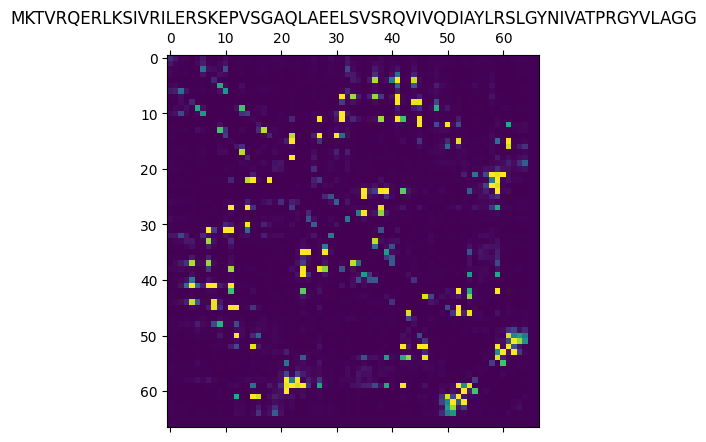

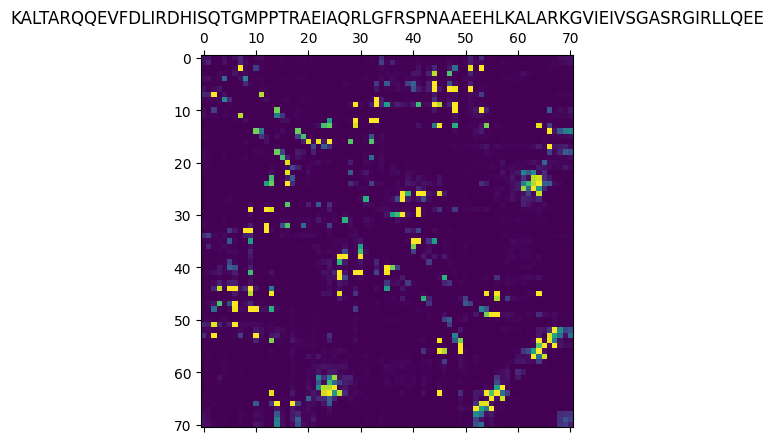

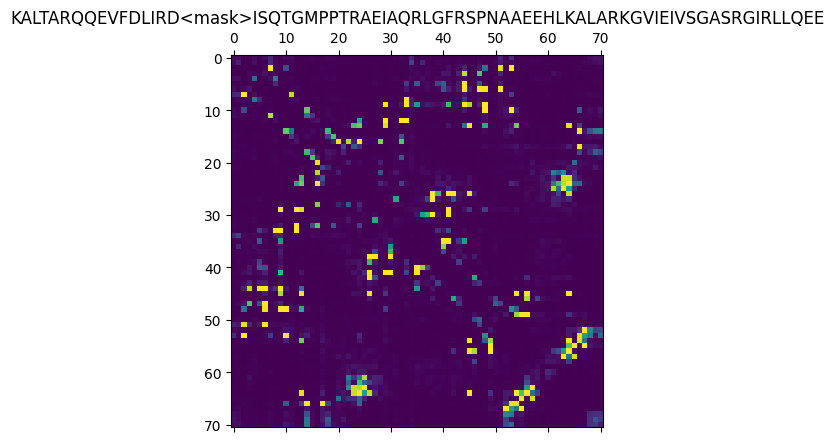

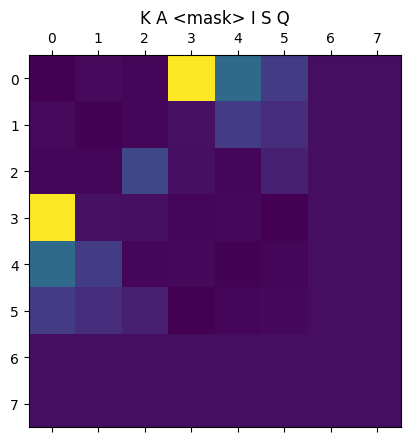

In [3]:
import torch
import esm

# Load ESM-2 model
model, alphabet = esm.pretrained.esm2_t36_3B_UR50D()
batch_converter = alphabet.get_batch_converter()
model.eval()  # disables dropout for deterministic results

# Prepare data (first 2 sequences from ESMStructuralSplitDataset superfamily / 4)
data = [
    ("protein1", "MKTVRQERLKSIVRILERSKEPVSGAQLAEELSVSRQVIVQDIAYLRSLGYNIVATPRGYVLAGG"),
    ("protein2", "KALTARQQEVFDLIRDHISQTGMPPTRAEIAQRLGFRSPNAAEEHLKALARKGVIEIVSGASRGIRLLQEE"),
    ("protein2 with mask","KALTARQQEVFDLIRD<mask>ISQTGMPPTRAEIAQRLGFRSPNAAEEHLKALARKGVIEIVSGASRGIRLLQEE"),
    ("protein3",  "K A <mask> I S Q"),
]
batch_labels, batch_strs, batch_tokens = batch_converter(data)
batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)

# Extract per-residue representations (on CPU)
with torch.no_grad():
    results = model(batch_tokens, repr_layers=[36], return_contacts=True)
token_representations = results["representations"][36]

# Generate per-sequence representations via averaging
# NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1.
sequence_representations = []
for i, tokens_len in enumerate(batch_lens):
    sequence_representations.append(token_representations[i, 1 : tokens_len - 1].mean(0))

# Look at the unsupervised self-attention map contact predictions
import matplotlib.pyplot as plt
for (_, seq), tokens_len, attention_contacts in zip(data, batch_lens, results["contacts"]):
    plt.matshow(attention_contacts[: tokens_len, : tokens_len])
    plt.title(seq)
    plt.show()


## Pepare the dataset

In [4]:
import pandas as pd

# Load the dataset
file_path = "final_dataset/final_dataset_SLC19A2_model_5.pkl"

df = pd.read_pickle(file_path)

# Print the head of the dataframe
print("DataFrame Head:")
df


DataFrame Head:


,#chr,pos,variation,variant_type,snp_id,clinical_significance,validation_status,function_class,gene,frequency,...,Siberian_is_mentioned,Qatari_freq,Qatari_is_mentioned,Avg_Frequency,Max_Frequency,Min_Frequency,Total_Studies,by-frequency,by-alfa,by-cluster
0,1,169476354,T>C,snv,1000230073,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000013:2:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.000031,0.000071,0.000008,3,1,1,1
1,1,169476354,T>C,snv,1000230073,normal,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000013:2:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.082630,0.185311,0.005581,5,1,1,1
2,1,169475878,T>C,snv,1000304891,normal,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000007:1:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.056416,0.175923,0.004349,11,1,1,1
3,1,169475878,T>C,snv,1000304891,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000007:1:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.000007,0.000008,0.000007,2,1,1,1
4,1,169483460,T>C,snv,1000361639,normal,by-frequency;by-alfa,intron_variant,SLC19A2,C:0.:0:ALFA,...,0,0.100872,1,0.058910,0.139787,0.000490,14,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22128,1,169485475,"G>A,C,T",snv,999809738,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.005137:15:KOREAN|G:0.5:3:Siberian|A:0.0000...,...,0,0.000000,0,0.000015,0.000015,0.000015,1,1,1,1
22129,1,169485475,"G>A,C,T",snv,999809738,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.005137:15:KOREAN|G:0.5:3:Siberian|A:0.0000...,...,0,0.000000,0,0.005137,0.005137,0.005137,1,1,1,1
22130,1,169485475,"G>A,C,T",snv,999809738,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.005137:15:KOREAN|G:0.5:3:Siberian|A:0.0000...,...,0,0.000000,0,0.000000,0.000000,0.000000,0,1,1,1
22131,1,169481070,C>A,snv,999949244,normal,by-frequency;by-alfa,intron_variant,SLC19A2,A:0.000004:1:TOPMED|A:0.:0:ALFA,...,0,0.000000,0,0.141436,0.342026,0.015769,9,1,1,1


In [5]:
file_path_2 = 'final_dataset/final_dataset_SLC19A3_model_5.pkl'

df_2 = pd.read_pickle(file_path_2)

# Print the head of the second dataframe
print("DataFrame 2 Head:")
print(df_2.head(), df_2.shape)


DataFrame 2 Head:
  #chr        pos variation variant_type      snp_id clinical_significance  \
0    2  227685064       G>A          snv  1000108682                   NaN   
1    2  227685064       G>A          snv  1000108682                normal   
2    2  227692888       A>T          snv  1000182811                   NaN   
3    2  227692888       A>T          snv  1000182811                normal   
4    2  227702777       T>A          snv  1000236352                   NaN   

                 validation_status       function_class     gene  \
0                              NaN  3_prime_UTR_variant  SLC19A3   
1                              NaN  3_prime_UTR_variant  SLC19A3   
2             by-frequency;by-alfa       intron_variant  SLC19A3   
3             by-frequency;by-alfa       intron_variant  SLC19A3   
4  by-frequency;by-alfa;by-cluster       intron_variant  SLC19A3   

                                           frequency  ... Avg_Frequency  \
0                            

In [6]:
# Find common columns between both dataframes
common_columns = df.columns.intersection(df_2.columns).tolist()
print(f"Common columns found: {len(common_columns)}")
print(f"Columns in df but not in df_2: {set(df.columns) - set(df_2.columns)}")
print(f"Columns in df_2 but not in df: {set(df_2.columns) - set(df.columns)}")

# Keep only common columns in both dataframes
df_common = df[common_columns].copy()
df_2_common = df_2[common_columns].copy()

# Concatenate the dataframes
df_combined = pd.concat([df_common, df_2_common], ignore_index=True)

print(f"\nOriginal df shape: {df.shape}")
print(f"Original df_2 shape: {df_2.shape}")
print(f"Combined dataframe shape: {df_combined.shape}")
print(f"Final number of columns: {len(common_columns)}")

# Remove duplicates if any
df_combined = df_combined.drop_duplicates()
print(f"Shape after removing duplicates: {df_combined.shape}")

Common columns found: 86
Columns in df but not in df_2: {'PharmGKB_freq', 'PharmGKB_is_mentioned'}
Columns in df_2 but not in df: set()

Original df shape: (22133, 88)
Original df_2 shape: (38892, 86)
Combined dataframe shape: (61025, 86)
Final number of columns: 86
Shape after removing duplicates: (55456, 86)


In [7]:
# Drop any rows that contain error-related words (Error, error, fail, etc.)
print(f"Number of rows before cleaning: {len(df_combined)}")

# Convert all values to string and check for error-related terms case-insensitively
error_pattern = '(?i)(error|fail|exception|invalid|timeout|crash)'
mask = df_combined.astype(str).apply(lambda x: x.str.contains(error_pattern)).any(axis=1)
df_clean = df_combined[~mask]

print(f"Number of rows after cleaning: {len(df_clean)}")
print(f"Removed {len(df_combined) - len(df_clean)} rows containing error-related terms")

# Display the first few rows of the cleaned dataframe
df_clean.head()

Number of rows before cleaning: 55456


/tmp/ipykernel_1357893/1749372498.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df_combined.astype(str).apply(lambda x: x.str.contains(error_pattern)).any(axis=1)


Number of rows after cleaning: 55456
Removed 0 rows containing error-related terms


,#chr,pos,variation,variant_type,snp_id,clinical_significance,validation_status,function_class,gene,frequency,...,Siberian_is_mentioned,Qatari_freq,Qatari_is_mentioned,Avg_Frequency,Max_Frequency,Min_Frequency,Total_Studies,by-frequency,by-alfa,by-cluster
0,1,169476354,T>C,snv,1000230073,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000013:2:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.000031,0.000071,0.000008,3,1,1,1
1,1,169476354,T>C,snv,1000230073,normal,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000013:2:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.082630,0.185311,0.005581,5,1,1,1
2,1,169475878,T>C,snv,1000304891,normal,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000007:1:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.056416,0.175923,0.004349,11,1,1,1
3,1,169475878,T>C,snv,1000304891,NaN,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,C:0.000007:1:GnomAD_genomes|C:0.000008:2:TOPME...,...,0,0.000000,0,0.000007,0.000008,0.000007,2,1,1,1
4,1,169483460,T>C,snv,1000361639,normal,by-frequency;by-alfa,intron_variant,SLC19A2,C:0.:0:ALFA,...,0,0.100872,1,0.058910,0.139787,0.000490,14,1,1,1


In [42]:
#USE THIS if you don't want the bases outside the gene region
# Process the reverse_complement_dna column to remove first 2000 and last 1000 bases

"""
df_clean['reverse_complement_dna'] = df_clean['reverse_complement_dna'].apply(
    lambda seq: seq[2000:-1000] if len(seq) > 3000 else seq
)

# Display the processed dataframe
df_clean
"""

"\ndf_clean['reverse_complement_dna'] = df_clean['reverse_complement_dna'].apply(\n    lambda seq: seq[2000:-1000] if len(seq) > 3000 else seq\n)\n\n# Display the processed dataframe\ndf_clean\n"

In [8]:
df_clean = df_combined.copy()

In [9]:
# Rename the clinical_significance column to original_clinical_sig
if 'clinical_significance' in df_clean.columns and 'original_clinical_sig' not in df_clean.columns:
    df_clean = df_clean.rename(columns={'clinical_significance': 'original_clinical_sig'})
    print("Renamed 'clinical_significance' column to 'original_clinical_sig'")
elif 'original_clinical_sig' in df_clean.columns:
    print("Column 'original_clinical_sig' already exists")
else:
    print("Column 'clinical_significance' not found in the dataframe")

# Rename the generated_dna column to reverse_complement_dna if needed
if 'generated_dna' in df_clean.columns and 'reverse_complement_dna' not in df_clean.columns:
    df_clean = df_clean.rename(columns={'generated_dna': 'reverse_complement_dna'})
    print("Renamed 'generated_dna' column to 'reverse_complement_dna'")
elif 'reverse_complement_dna' in df_clean.columns:
    print("Column 'reverse_complement_dna' already exists")
else:
    print("Column 'generated_dna' not found in the dataframe")


Renamed 'clinical_significance' column to 'original_clinical_sig'
Renamed 'generated_dna' column to 'reverse_complement_dna'


In [10]:
# Identify SNP IDs with labels other than 'normal' and NaN
labeled_snps = df_clean.loc[
    (df_clean['original_clinical_sig'].notna()) & (df_clean['original_clinical_sig'] != 'nan') & (df_clean['original_clinical_sig'] != 'normal'),
    'snp_id'
].unique().tolist()

# Print the number of unique labeled SNP IDs
print(f"Found {len(labeled_snps)} unique SNP IDs with labels other than 'normal' and NaN")

# Filter dataframes based on SNP IDs
snp_id_mask = df_clean['snp_id'].isin(labeled_snps)
df_labeled = df_clean[snp_id_mask].copy()
df_unlabeled = df_clean[~snp_id_mask].copy()

print(f"Labeled data shape: {df_labeled.shape}")
print(f"Unlabeled data shape: {df_unlabeled.shape}")


Found 962 unique SNP IDs with labels other than 'normal' and NaN
Labeled data shape: (2333, 86)
Unlabeled data shape: (53123, 86)


In [11]:
# Count the number of rows before filtering
print(f"Total rows before filtering: {len(df_unlabeled)}")

# Identify rows with 'normal' clinical significance
normal_mask = df_unlabeled['original_clinical_sig'] == 'normal'
normal_indices = df_unlabeled[normal_mask].index
non_normal_indices = df_unlabeled[~normal_mask].index

# Calculate how many 'normal' samples to keep (10%)
keep_count = int(len(normal_indices) * 0.1)

# Randomly select 10% of 'normal' samples to keep
import random
random.seed(42)  # For reproducibility
indices_to_keep = random.sample(list(normal_indices), keep_count) if len(normal_indices) > 0 else []

# Create a new dataframe with reduced 'normal' samples
filtered_indices = list(indices_to_keep) + list(non_normal_indices)
unlabeled_df = df_unlabeled.loc[filtered_indices]

# Count the number of rows after filtering
print(f"Total rows after filtering: {len(unlabeled_df)}")
print(f"Removed {len(normal_indices) - keep_count} 'normal' samples ({90 if len(normal_indices) > 0 else 0}% of normal samples)")

# Display the first few rows


Total rows before filtering: 53123
Total rows after filtering: 31199
Removed 21924 'normal' samples (90% of normal samples)


### continue for training

In [12]:
# clean labels
preprocess = df_labeled.copy()
# First, clean up extra whitespace
preprocess["original_clinical_sig"] = preprocess["original_clinical_sig"].str.strip()

# Define a mapping dictionary for the specific replacements
replacement_mapping = {
    "likely-benign;benign-likely-benign": "likely-benign",
    "likely-pathogenic;pathogenic": "likely-pathogenic",
    "uncertain-significance;likely-pathogenic": "likely-pathogenic",
    "likely-pathogenic;uncertain-significance": "likely-pathogenic",
    "likely-benign;uncertain-significance": "likely-benign",
    "likely-benign;conflicting-interpretations-of-pathogenicity": "likely-benign",
    "pathogenic;pathogenic-likely-pathogenic": "pathogenic",
    "conflicting-interpretations-of-pathogenicity": "uncertain-significance",
    "uncertain-significance;likely-benign": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;uncertain-significance": "uncertain-significance",
    "conflicting-interpretations-of-pathogenicity;benign-likely-benign": "likely-benign",
    "uncertain-significance;likely-benign;conflicting-interpretations-of-pathogenicity;benign": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;likely-benign": "likely-benign",
    "benign-likely-benign;conflicting-interpretations-of-pathogenicity;uncertain-significance": "likely-benign",
    "benign-likely-benign;benign": "likely-benign",
    "benign;likely-benign": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;uncertain-significance": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;benign-likely-benign": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;benign": "likely-benign",
    "benign;likely-benign;conflicting-interpretations-of-pathogenicity;benign-likely-benign": "likely-benign",
    "uncertain-significance;pathogenic": "pathogenic",
    "likely-pathogenic;pathogenic-likely-pathogenic": "likely-pathogenic",
    "likely-pathogenic;benign": "uncertain-significance",
    "uncertain-significance;not-provided": "uncertain-significance",
    "uncertain-significance;benign-likely-benign": "likely-benign",
    "likely-benign;uncertain-significance;benign": "likely-benign",
    "benign-likely-benign;uncertain-significance;benign": "likely-benign",
    "pathogenic-likely-pathogenic;likely-pathogenic": "likely-pathogenic",
    "benign;uncertain-significance;likely-benign": "likely-benign",
    "benign;likely-benign;uncertain-significance": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;uncertain-significance;likely-benign": "likely-benign",
    "pathogenic;likely-pathogenic": "likely-pathogenic",
    "uncertain-significance;not-provided": "uncertain-significance",
    "likely-benign;benign": "likely-benign",
    "uncertain-significance;benign-likely-benign": "likely-benign",
    "uncertain-significance;benign-likely-benign": "likely-benign",
    "conflicting-interpretations-of-pathogenicity;uncertain-significance;likely-benign": "likely-benign",
    "pathogenic;uncertain-significance": "likely-pathogenic",
    "benign;uncertain-significance": "likely-benign",
    "uncertain-significance;likely-benign;benign": "likely-benign",
    "pathogenic-likely-pathogenic": "likely-pathogenic",
    " pathogenic-likely-pathogenic;pathogenic": "pathogenic",
    "likely-benign;pathogenic":"uncertain-significance",
    "uncertain-significance;conflicting-interpretations-of-pathogenicity": "uncertain-significance",
    "likely-benign;conflicting-interpretations-of-pathogenicity;uncertain-significance": "likely-benign",
    "benign-likely-benign;uncertain-significance": "likely-benign",
    "pathogenic-likely-pathogenic;likely-benign;pathogenic": "likely-pathogenic",
    "benign;benign-likely-benign": "likely-benign",
    "benign-likely-benign;likely-benign": "likely-benign",
    "uncertain-significance;conflicting-interpretations-of-pathogenicity": "uncertain-significance",
    "pathogenic-likely-pathogenic;pathogenic": "likely-pathogenic",
    "pathogenic;likely-benign":"uncertain-significance",
    "likely-pathogenic;benign-likely-benign;uncertain-significance":"uncertain-significance",
    "benign;conflicting-interpretations-of-pathogenicity;likely-benign":"likely-benign",
    "conflicting-interpretations-of-pathogenicity;benign-likely-benign;likely-benign":"likely-benign",   
    "conflicting-interpretations-of-pathogenicity;likely-benign;uncertain-significance":"uncertain-significance",
}

# Make a copy of the original column to compare later
preprocess["clinical_significance_before"] = preprocess["original_clinical_sig"].copy()

# Replace exact string matches using the mapping
preprocess["original_clinical_sig"] = preprocess["original_clinical_sig"].replace(replacement_mapping)

# Count how many changes were made
changes_count = (preprocess["original_clinical_sig"] != preprocess["clinical_significance_before"]).sum()
print(f"\nNumber of clinical significance labels changed: {changes_count}")

# Drop the temporary column used for comparison
preprocess.drop("clinical_significance_before", axis=1, inplace=True)





Number of clinical significance labels changed: 26


In [13]:
df_processed = preprocess.copy()

# Map clinical significance to continuous labels
clinical_sig_mapping = {
    'normal': 3,
    'benign': 2,
    'likely-benign': 1,
    'uncertain-significance': 0,
    'likely-pathogenic': -1,
    'pathogenic': -2
}

# Create ContinuousLabel column based on original_clinical_sig
df_processed['ContinuousLabel'] = df_processed['original_clinical_sig'].map(clinical_sig_mapping)

# Rename reverse_complement_dna column to sequence
df_processed.rename(columns={'reverse_complement_dna': 'sequence'}, inplace=True)

# Print how many mappings have been done successfully
print(f"Successfully mapped {df_processed['ContinuousLabel'].count()} out of {len(df_processed)} clinical significance values.")

Successfully mapped 2333 out of 2333 clinical significance values.


In [14]:
for index, row in df_processed.iterrows():
    if pd.isna(row['ContinuousLabel']):
        print(f"Row {index} has an unrecognized clinical significance: {row['original_clinical_sig']}")
        print (f"clinical significance: {row['original_clinical_sig']}")

In [15]:
print(df_processed.shape)
df_processed.head()

# Print length of first 10 rows of sequence column
for i in range(min(10, len(df_processed))):
    print(f"Row {i} sequence length: {len(df_processed['sequence'].iloc[i])}")

(2333, 87)
Row 0 sequence length: 26062
Row 1 sequence length: 26062
Row 2 sequence length: 26062
Row 3 sequence length: 26062
Row 4 sequence length: 26062
Row 5 sequence length: 26062
Row 6 sequence length: 26062
Row 7 sequence length: 26062
Row 8 sequence length: 26055
Row 9 sequence length: 26052


In [16]:
# Shuffle and randomize the rows in df_processed
df_processed = df_processed.sample(frac=1, random_state=42).reset_index(drop=True)

# Display the shuffled dataframe
df_processed

,#chr,pos,variation,variant_type,snp_id,original_clinical_sig,validation_status,function_class,gene,frequency,...,Qatari_freq,Qatari_is_mentioned,Avg_Frequency,Max_Frequency,Min_Frequency,Total_Studies,by-frequency,by-alfa,by-cluster,ContinuousLabel
0,1,169470079,A>G,snv,552366444,normal,by-frequency;by-alfa;by-cluster,coding_sequence_variant;synonymous_variant,SLC19A2,G:0.0002:1:1000Genomes|G:0.000312:2:1000Genome...,...,0.112552,1,0.094020,0.391609,0.028547,11,1,1,1,3
1,2,227702267,T>C,snv,1574565534,normal,NaN,missense_variant;5_prime_UTR_variant;coding_se...,SLC19A3,NaN,...,0.000000,0,0.052837,0.106725,0.005606,8,1,1,1,3
2,2,227688250,G>A,snv,1574542050,likely-benign,NaN,synonymous_variant;coding_sequence_variant,SLC19A3,NaN,...,0.000000,0,0.000000,0.000000,0.000000,0,0,0,0,1
3,1,169468260,A>G,snv,751410694,likely-benign,by-frequency;by-alfa;by-cluster,intron_variant,SLC19A2,G:0.0000087:1:ExAC|G:0.0000021:3:GnomAD_exomes...,...,0.000000,0,0.000006,0.000009,0.000002,4,1,1,1,1
4,2,227695891,T>G,snv,2106325855,normal,by-frequency;by-cluster,coding_sequence_variant;synonymous_variant,SLC19A3,G:0.000007:1:GnomAD_genomes,...,0.000000,0,0.046884,0.267671,0.001133,8,1,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2328,2,227688321,T>C,snv,2470555222,likely-benign,NaN,intron_variant,SLC19A3,NaN,...,0.000000,0,0.000000,0.000000,0.000000,0,0,0,0,1
2329,2,227687524,"A>C,G,T",snv,1308805272,normal,by-frequency;by-alfa;by-cluster,coding_sequence_variant;missense_variant,SLC19A3,T:0.00001:1:TOMMO|T:0.:0:ALFA,...,0.236664,1,0.091092,0.236664,0.014392,9,1,1,1,3
2330,2,227699202,"G>A,T",snv,1353757275,uncertain-significance,by-frequency;by-alfa;by-cluster,synonymous_variant;stop_gained;coding_sequence...,SLC19A3,A:0.00005:1:ALFA,...,0.000000,0,0.000000,0.000000,0.000000,0,1,1,1,0
2331,2,227698865,A>G,snv,1553571227,pathogenic,by-frequency;by-alfa;by-cluster,coding_sequence_variant;missense_variant,SLC19A3,G:0.0000014:2:GnomAD_exomes|G:0.:0:GnomAD_geno...,...,0.000000,0,0.000003,0.000004,0.000001,2,1,1,1,-2


## Continue for labeling

In [25]:

df_test = unlabeled_df.copy()
# Rename reverse_complement_dna column to sequence
df_test.rename(columns={'reverse_complement_dna': 'sequence'}, inplace=True)

In [26]:
print(df_test.shape)
df_processed = df_test

(31199, 86)


In [ ]:
# gener

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder 
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd # Make sure pandas is imported if pd.isna is used

# Ensure df_processed exists from the previous cell
if 'df_processed' not in locals():
    raise NameError("df_processed is not defined. Please run the previous cell to generate it.")
# Ensure get_dna_embeddings, model, and tokenizer are defined
if 'get_dna_embeddings' not in locals() or 'model' not in locals() or 'tokenizer' not in locals():
     raise NameError("get_dna_embeddings, model, or tokenizer is not defined. Please ensure they are loaded.")

# Set device to CUDA if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move model to device
model = model.to(device)

# --- 1. Generate Embeddings using df_processed (Splitting Sequences) ---
print("Generating embeddings for processed sequences (splitting into 5 parts)...")
combined_embeddings_list_nn = []
sequences_list_nn = [] # Keep track of original sequences corresponding to embeddings
num_parts = 5
embedding_dim_per_part = -1 # Will be determined by the first successful embedding

# Use mean pooling embeddings for this task (applied to each part)
embedding_type_nn = 'mean' # or 'max' or 'concatenate'

# Limit the number of sequences for faster testing/debugging if needed
# df_subset_nn = df_processed.head(200) # Uncomment for testing
df_subset_nn = df_processed

# Assuming get_dna_embeddings, model, and tokenizer are defined from earlier cells
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for NN"):
    sequence = row['sequence']

    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid sequence '{sequence}'")
        continue

    # Ensure sequence is long enough to be split (optional, depends on desired handling)
    min_len_per_part = 10 # Example minimum length for a part to be meaningful
    if len(sequence) < num_parts * min_len_per_part:
        print(f"Skipping row {index}: Sequence too short ({len(sequence)} bases) to split into {num_parts} parts of min length {min_len_per_part}.")
        continue

    part_embeddings = []
    try:
        # Split sequence into num_parts roughly equal parts
        seq_len = len(sequence)
        part_len = seq_len // num_parts
        start_indices = [i * part_len for i in range(num_parts)]
        # Adjust the last part to include any remainder
        end_indices = [(i + 1) * part_len for i in range(num_parts - 1)] + [seq_len]

        for i in range(num_parts):
            sub_sequence = sequence[start_indices[i]:end_indices[i]]

            if len(sub_sequence) == 0: # Should not happen with the length check above, but good practice
                print(f"Warning: Skipping empty sub-sequence for row {index}, part {i+1}")
                continue # Or handle by padding/zero-vector

            # Get embeddings for the sub-sequence
            emb_mean, emb_max = get_dna_embeddings(sub_sequence, model, tokenizer)

            if embedding_type_nn == 'mean':
                embedding_part = emb_mean.cpu().numpy().flatten() # Flatten in case it's not already 1D
            elif embedding_type_nn == 'max':
                embedding_part = emb_max.cpu().numpy().flatten()
            elif embedding_type_nn == 'concatenate':
                # Concatenate along feature dim (dim=1 if batch dim exists, dim=0 otherwise)
                embedding_part = torch.cat((emb_mean, emb_max), dim=emb_mean.dim()-1).cpu().numpy().flatten()
            else:
                 # Default to mean if type is unknown
                embedding_part = emb_mean.cpu().numpy().flatten()

            if embedding_dim_per_part == -1:
                embedding_dim_per_part = len(embedding_part) # Set the expected dimension

            # Ensure consistent embedding dimension (handle potential errors from get_dna_embeddings)
            if len(embedding_part) != embedding_dim_per_part:
                 raise ValueError(f"Inconsistent embedding dimension for part {i+1} of sequence {index}. Expected {embedding_dim_per_part}, got {len(embedding_part)}.")

            part_embeddings.append(embedding_part)

        # Check if we got the expected number of embeddings
        if len(part_embeddings) == num_parts:
            # Combine the embeddings for the parts (concatenate them)
            combined_embedding = np.concatenate(part_embeddings)
            combined_embeddings_list_nn.append(combined_embedding)
            sequences_list_nn.append(sequence) # Store the original sequence
        else:
             print(f"Skipping row {index}: Could not generate embeddings for all {num_parts} parts (got {len(part_embeddings)}).")


    except Exception as e:
        print(f"Error processing sequence at index {index} ('{sequence[:30]}...'): {e}")
        # Optionally skip problematic sequences or handle differently
        continue

# Convert lists to NumPy arrays
X_nn = np.array(combined_embeddings_list_nn)

if X_nn.shape[0] > 0:
    print(f"\nGenerated {X_nn.shape[0]} combined embeddings of shape {X_nn.shape[1]} (from {num_parts} parts).")
    print(f"Individual part embedding dimension: {embedding_dim_per_part}")
else:
    print("\nNo combined embeddings were generated. Cannot proceed with further processing.")
    # Exit or handle the case where no data is available
    # raise SystemExit("Stopping execution: No embeddings generated.") # Or similar

Using device: cuda
Generating embeddings for processed sequences (splitting into 5 parts)...


Processing sequences for NN:   0%|          | 0/31199 [00:00<?, ?it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 512 to 1410
  warnings.warn(
/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 1410 to 1429
  warnings.warn(
Processing sequences for NN:  42%|████▏     | 13097/31199 [31:37<1:03:47,  4.73it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 1429 to 1430
  warnings.warn(
Processing sequences for NN:  42%|████▏     | 13211/31199 [32:00<1:04:55,  4.62it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b58


Generated 31199 combined embeddings of shape 3840 (from 5 parts).
Individual part embedding dimension: 768


In [19]:
# Save DNA-BERT embeddings with timestamp
import time
timestamp = int(time.time())
np.save(f"embeddings/dnabert_embeddings_labeling_both{timestamp}.npy", X_nn)
print(f"Saved DNA-BERT embeddings to embeddings/dnabert_embeddings_labeling_both{timestamp}.npy")

Saved DNA-BERT embeddings to embeddings/dnabert_embeddings_labeling_both1754989195.npy


In [27]:
# Load the specific DNA-BERT embeddings file
import os
import numpy as np

# Load the specific file
file_path = "embeddings/dnabert_embeddings_labeling_both1754989195.npy"
X_nn = np.load(file_path)
print(f"Loaded DNA-BERT embeddings from {file_path}")
print(f"Loaded embedding shape: {X_nn.shape}")


Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_labeling_both1754989195.npy
Loaded embedding shape: (31199, 3840)


In [21]:
# --- 2. Generate Embeddings using ESM-2 model ---
print("Generating embeddings using ESM-2 model...")

# Load ESM-2 model (smaller version for efficiency)
print("Loading ESM-2 model...")
import esm
esm_model, alphabet = esm.pretrained.esm2_t36_3B_UR50D()
batch_converter = alphabet.get_batch_converter()
esm_model.eval()  # disables dropout for deterministic results

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
esm_model = esm_model.to(device)

# Function to get ESM-2 embeddings for protein sequences
def get_esm2_embeddings(sequence, model, alphabet, batch_converter, device):
    # Prepare data for ESM-2
    data = [("seq", sequence)]
    batch_labels, batch_strs, batch_tokens = batch_converter(data)
    
    # Move to GPU
    batch_tokens = batch_tokens.to(device)
    
    # Get embeddings
    with torch.no_grad():
        results = model(batch_tokens, repr_layers=[36], return_contacts=True)
    token_representations = results["representations"][36]
    
    # Generate sequence representation via averaging (mean pooling)
    # NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1.
    batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)
    sequence_representation = token_representations[0, 1:batch_lens[0]-1].mean(0)
    
    # Also compute max pooling for comparison
    sequence_representation_max = token_representations[0, 1:batch_lens[0]-1].max(0)[0]
    
    return sequence_representation, sequence_representation_max

# Lists to store ESM-2 embeddings
embeddings_list_esm2 = []
sequences_list_esm2 = []
error_snp_ids = []  # Track SNP IDs with errors

# Process sequences with ESM-2
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for ESM-2"):
    # Use protein_sequence column instead of sequence
    sequence = row['protein_sequence']
    snp_id = row.get('snp_id', 'unknown')  # Get SNP ID if available
    
    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid protein sequence '{sequence}'")
        error_snp_ids.append(snp_id)
        continue
    
    try:
        # Get embeddings for the whole sequence using ESM-2
        emb_mean, emb_max = get_esm2_embeddings(sequence, esm_model, alphabet, batch_converter, device)
        
        # Use mean embeddings by default
        embedding = emb_mean.cpu().numpy().flatten()
        
        # Store the embedding and corresponding sequence
        embeddings_list_esm2.append(embedding)
        sequences_list_esm2.append(sequence)
    
    except Exception as e:
        print(f"Error processing protein sequence at index {index} ('{sequence[:30]}...'): {e}")
        error_snp_ids.append(snp_id)
        continue

# Convert lists to NumPy arrays
X_nn_esm2 = np.array(embeddings_list_esm2)

if X_nn_esm2.shape[0] > 0:
    print(f"\nGenerated {X_nn_esm2.shape[0]} ESM-2 embeddings of shape {X_nn_esm2.shape[1]}")
else:
    print("\nNo ESM-2 embeddings were generated. Cannot proceed with ESM-2 model training.")

# Print SNP IDs with errors
if error_snp_ids:
    print("\nSNP IDs with errors during ESM-2 embedding generation:")
    for snp_id in error_snp_ids:
        print(f"  - {snp_id}")


Generating embeddings using ESM-2 model...
Loading ESM-2 model...
Using device: cuda


Processing sequences for ESM-2: 100%|██████████| 31199/31199 [8:58:44<00:00,  1.04s/it]   



Generated 31199 ESM-2 embeddings of shape 2560


In [22]:
# Save the generated ESM-2 embeddings locally
if X_nn_esm2.shape[0] > 0:
    print("\nSaving ESM-2 embeddings to disk...")
    import datetime
    import os
    
    # Generate timestamp for filenames
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    
    # Save embeddings and labels with timestamp
    file_path = os.path.join("embeddings", f"labeling_SLC19A2_X_nn_esm2_{timestamp}.npy")
    np.save(file_path, X_nn_esm2)
    print(f"Saved ESM-2 embeddings to {file_path}")
else:
    print("No ESM-2 embeddings to save.")



Saving ESM-2 embeddings to disk...
Saved ESM-2 embeddings to embeddings/labeling_SLC19A2_X_nn_esm2_20250812_105918.npy


In [28]:
# Load the previously saved ESM-2 embeddings
import numpy as np
import os

# Path to the saved embeddings
embeddings_path = "embeddings/labeling_SLC19A2_X_nn_esm2_20250812_105918.npy"

# Check if the file exists
if os.path.exists(embeddings_path):
    print(f"Loading ESM-2 embeddings from {embeddings_path}...")
    X_nn_esm2 = np.load(embeddings_path)
    print(f"Loaded ESM-2 embeddings with shape: {X_nn_esm2.shape}")
else:
    print(f"Error: Could not find embeddings file at {embeddings_path}")
    X_nn_esm2 = np.array([])

Loading ESM-2 embeddings from embeddings/labeling_SLC19A2_X_nn_esm2_20250812_105918.npy...
Loaded ESM-2 embeddings with shape: (31199, 2560)


In [203]:
print(df_processed.columns.tolist())

['#chr', 'pos', 'variation', 'variant_type', 'snp_id', 'original_clinical_sig', 'validation_status', 'function_class', 'gene', 'frequency', 'original', 'mutant', 'sequence', 'generated_mRNA', 'protein_sequence', 'MGP_freq', 'MGP_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_

In [29]:
import numpy as np

x_3_columns = ['PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', 'TOPMED_freq', 'TOPMED_is_mentioned', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Siberian_freq', 'Siberian_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GoESP_freq', 'GoESP_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'Vietnamese_freq', 'Vietnamese_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', '1000Genomes_freq', '1000Genomes_is_mentioned', 'Qatari_freq', 'Qatari_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'MGP_freq', 'MGP_is_mentioned', 'Avg_Frequency', 'Max_Frequency', 'Min_Frequency', 'Total_Studies', 'by-frequency', 'by-alfa', 'by-cluster']
x_3 = df_processed.values[:, df_processed.columns.isin(x_3_columns)]
# Ensure x_3 is a NumPy array of type float32
x_3 = np.array(x_3, dtype=np.float32)
print("x_3 type:", type(x_3))
print("x_3 dtype:", x_3.dtype)
print("x_3 shape:", x_3.shape)
x_3[0:32,:]


x_3 type: <class 'numpy.ndarray'>
x_3 dtype: float32
x_3 shape: (31199, 71)


array([[0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.01121822, 1.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.09765211, ..., 1.        , 1.        ,
        1.        ],
       ...,
       [0.        , 0.        , 0.04334324, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ]], dtype=float32)

In [30]:
# Ensure that the number of embeddings from both methods match
if X_nn.shape[0] != X_nn_esm2.shape[0]:
    raise ValueError("Mismatch in number of embeddings: DNA embeddings have shape {} while ESM-2 embeddings have shape {}.".format(X_nn.shape, X_nn_esm2.shape))

# Fuse the embeddings by concatenating along the feature dimension (axis=1)
X_fused = np.concatenate((X_nn, X_nn_esm2,x_3), axis=1)

# Print the shape of the fused embeddings
print("Fused embeddings shape:", X_fused.shape)


Fused embeddings shape: (31199, 6471)


## Generating Embeddings (training)

### DNABERT EMBEDDINGS

In [16]:
# gener

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd # Make sure pandas is imported if pd.isna is used

# Ensure df_processed exists from the previous cell
if 'df_processed' not in locals():
    raise NameError("df_processed is not defined. Please run the previous cell to generate it.")
# Ensure get_dna_embeddings, model, and tokenizer are defined
if 'get_dna_embeddings' not in locals() or 'model' not in locals() or 'tokenizer' not in locals():
     raise NameError("get_dna_embeddings, model, or tokenizer is not defined. Please ensure they are loaded.")

# Set device to CUDA if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move model to device
model = model.to(device)

# --- 1. Generate Embeddings using df_processed (Splitting Sequences) ---
print("Generating embeddings for processed sequences (splitting into 5 parts)...")
combined_embeddings_list_nn = []
labels_list_nn = []
sequences_list_nn = [] # Keep track of original sequences corresponding to embeddings
num_parts = 5
embedding_dim_per_part = -1 # Will be determined by the first successful embedding

# Use mean pooling embeddings for this task (applied to each part)
embedding_type_nn = 'mean' # or 'max' or 'concatenate'

# Limit the number of sequences for faster testing/debugging if needed
# df_subset_nn = df_processed.head(200) # Uncomment for testing
df_subset_nn = df_processed

# Assuming get_dna_embeddings, model, and tokenizer are defined from earlier cells
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for NN"):
    sequence = row['sequence']
    label = row['ContinuousLabel'] # Assuming this is the correct label column

    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid sequence '{sequence}'")
        continue

    # Ensure label is valid (e.g., not NaN)
    if pd.isna(label):
        print(f"Skipping row {index}: Invalid label '{label}'")
        continue

    # Ensure sequence is long enough to be split (optional, depends on desired handling)
    min_len_per_part = 10 # Example minimum length for a part to be meaningful
    if len(sequence) < num_parts * min_len_per_part:
        print(f"Skipping row {index}: Sequence too short ({len(sequence)} bases) to split into {num_parts} parts of min length {min_len_per_part}.")
        continue

    part_embeddings = []
    try:
        # Split sequence into num_parts roughly equal parts
        seq_len = len(sequence)
        part_len = seq_len // num_parts
        start_indices = [i * part_len for i in range(num_parts)]
        # Adjust the last part to include any remainder
        end_indices = [(i + 1) * part_len for i in range(num_parts - 1)] + [seq_len]

        for i in range(num_parts):
            sub_sequence = sequence[start_indices[i]:end_indices[i]]

            if len(sub_sequence) == 0: # Should not happen with the length check above, but good practice
                print(f"Warning: Skipping empty sub-sequence for row {index}, part {i+1}")
                continue # Or handle by padding/zero-vector

            # Get embeddings for the sub-sequence
            emb_mean, emb_max = get_dna_embeddings(sub_sequence, model, tokenizer)

            if embedding_type_nn == 'mean':
                embedding_part = emb_mean.cpu().numpy().flatten() # Flatten in case it's not already 1D
            elif embedding_type_nn == 'max':
                embedding_part = emb_max.cpu().numpy().flatten()
            elif embedding_type_nn == 'concatenate':
                # Concatenate along feature dim (dim=1 if batch dim exists, dim=0 otherwise)
                embedding_part = torch.cat((emb_mean, emb_max), dim=emb_mean.dim()-1).cpu().numpy().flatten()
            else:
                 # Default to mean if type is unknown
                embedding_part = emb_mean.cpu().numpy().flatten()

            if embedding_dim_per_part == -1:
                embedding_dim_per_part = len(embedding_part) # Set the expected dimension

            # Ensure consistent embedding dimension (handle potential errors from get_dna_embeddings)
            if len(embedding_part) != embedding_dim_per_part:
                 raise ValueError(f"Inconsistent embedding dimension for part {i+1} of sequence {index}. Expected {embedding_dim_per_part}, got {len(embedding_part)}.")

            part_embeddings.append(embedding_part)

        # Check if we got the expected number of embeddings
        if len(part_embeddings) == num_parts:
            # Combine the embeddings for the parts (concatenate them)
            combined_embedding = np.concatenate(part_embeddings)
            combined_embeddings_list_nn.append(combined_embedding)
            labels_list_nn.append(label)
            sequences_list_nn.append(sequence) # Store the original sequence
        else:
             print(f"Skipping row {index}: Could not generate embeddings for all {num_parts} parts (got {len(part_embeddings)}).")


    except Exception as e:
        print(f"Error processing sequence at index {index} ('{sequence[:30]}...'): {e}")
        # Optionally skip problematic sequences or handle differently
        continue

# Convert lists to NumPy arrays
X_nn = np.array(combined_embeddings_list_nn)
y_nn_original = np.array(labels_list_nn)

if X_nn.shape[0] > 0:
    print(f"\nGenerated {X_nn.shape[0]} combined embeddings of shape {X_nn.shape[1]} (from {num_parts} parts).")
    print(f"Individual part embedding dimension: {embedding_dim_per_part}")
    print(f"Corresponding labels shape: {y_nn_original.shape}")
else:
    print("\nNo combined embeddings were generated. Cannot proceed with NN training.")
    # Exit or handle the case where no data is available
    # raise SystemExit("Stopping execution: No embeddings generated.") # Or similar

Using device: cuda
Generating embeddings for processed sequences (splitting into 5 parts)...


Processing sequences for NN:   0%|          | 0/2333 [00:00<?, ?it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 512 to 1026
  warnings.warn(
Processing sequences for NN:   0%|          | 1/2333 [00:00<16:35,  2.34it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 1026 to 1410
  warnings.warn(
/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_layers.py:433: UserWarning: Increasing alibi size from 1410 to 1429
  warnings.warn(
Processing sequences for NN:   3%|▎         | 78/2333 [00:12<06:34,  5.72it/s]/home/joe/.cache/huggingface/modules/transformers_modules/zhihan1996/DNABERT-2-117M/7bce263b15377fc15361f52cfab88f8b586abda0/bert_la


Generated 2333 combined embeddings of shape 3840 (from 5 parts).
Individual part embedding dimension: 768
Corresponding labels shape: (2333,)


In [17]:
# Save DNA-BERT embeddings with timestamp
import numpy as np
import time
timestamp = int(time.time())
np.save(f"embeddings/dnabert_embeddings_{timestamp}.npy", X_nn)
print(f"Saved DNA-BERT embeddings to dnabert_embeddings_{timestamp}.npy")

Saved DNA-BERT embeddings to dnabert_embeddings_1754981297.npy


In [17]:
import numpy as np

In [18]:
# Load the DNA-BERT embeddings from the specified file
X_nn = np.load("embeddings/dnabert_embeddings_1754981297.npy")
print(f"Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_1754981297.npy with shape: {X_nn.shape}")

Loaded DNA-BERT embeddings from embeddings/dnabert_embeddings_1754981297.npy with shape: (2333, 3840)


In [168]:
import gc

# Empty CUDA cache to free up GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    
# Force garbage collection to release memory
gc.collect()

print("GPU memory cleaned after DNA-BERT processing")


GPU memory cleaned after DNA-BERT processing


### SM-2 Embeddings

In [20]:
import numpy as np
# --- 2. Generate Embeddings using ESM-2 model ---
print("Generating embeddings using ESM-2 model...")

# Load ESM-2 model (smaller version for efficiency)
print("Loading ESM-2 model...")
import esm
from tqdm.auto import tqdm

esm_model, alphabet = esm.pretrained.esm2_t36_3B_UR50D()
batch_converter = alphabet.get_batch_converter()
esm_model.eval()  # disables dropout for deterministic results

# Move model to GPU device 1 if available
device = torch.device("cuda:1" if torch.cuda.is_available() and torch.cuda.device_count() > 1 else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
esm_model = esm_model.to(device)
df_subset_nn = df_processed
# Function to get ESM-2 embeddings for protein sequences
def get_esm2_embeddings(sequence, model, alphabet, batch_converter, device):
    # Prepare data for ESM-2
    data = [("seq", sequence)]
    batch_labels, batch_strs, batch_tokens = batch_converter(data)
    
    # Move to GPU
    batch_tokens = batch_tokens.to(device)
    
    # Get embeddings
    with torch.no_grad():
        results = model(batch_tokens, repr_layers=[36], return_contacts=True)
    token_representations = results["representations"][36]
    
    # Generate sequence representation via averaging (mean pooling)
    # NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1.
    batch_lens = (batch_tokens != alphabet.padding_idx).sum(1)
    sequence_representation = token_representations[0, 1:batch_lens[0]-1].mean(0)
    
    # Also compute max pooling for comparison
    sequence_representation_max = token_representations[0, 1:batch_lens[0]-1].max(0)[0]
    
    return sequence_representation, sequence_representation_max

# Lists to store ESM-2 embeddings
embeddings_list_esm2 = []
labels_list_esm2 = []
sequences_list_esm2 = []
error_snp_ids = []  # Track SNP IDs with errors

# Process sequences with ESM-2
for index, row in tqdm(df_subset_nn.iterrows(), total=df_subset_nn.shape[0], desc="Processing sequences for ESM-2"):
    # Use protein_sequence column instead of sequence
    sequence = row['protein_sequence']
    label = row['ContinuousLabel']
    snp_id = row.get('snp_id', 'unknown')  # Get SNP ID if available
    
    # Ensure sequence is a string and not empty
    if not isinstance(sequence, str) or len(sequence) == 0:
        print(f"Skipping row {index}: Invalid protein sequence '{sequence}'")
        error_snp_ids.append(snp_id)
        continue
    
    # Ensure label is valid
    if pd.isna(label):
        print(f"Skipping row {index}: Invalid label '{label}'")
        error_snp_ids.append(snp_id)
        continue
    
    try:
        # Get embeddings for the whole sequence using ESM-2
        emb_mean, emb_max = get_esm2_embeddings(sequence, esm_model, alphabet, batch_converter, device)
        
        # Use mean embeddings by default
        embedding = emb_mean.cpu().numpy().flatten()
        
        # Store the embedding and corresponding label
        embeddings_list_esm2.append(embedding)
        labels_list_esm2.append(label)
        sequences_list_esm2.append(sequence)
    
    except Exception as e:
        print(f"Error processing protein sequence at index {index} ('{sequence[:30]}...'): {e}")
        error_snp_ids.append(snp_id)
        continue

# Convert lists to NumPy arrays
X_nn_esm2 = np.array(embeddings_list_esm2)
y_nn_esm2 = np.array(labels_list_esm2)

if X_nn_esm2.shape[0] > 0:
    print(f"\nGenerated {X_nn_esm2.shape[0]} ESM-2 embeddings of shape {X_nn_esm2.shape[1]}")
    print(f"Corresponding labels shape: {y_nn_esm2.shape}")
else:
    print("\nNo ESM-2 embeddings were generated. Cannot proceed with ESM-2 model training.")

# Print SNP IDs with errors
if error_snp_ids:
    print("\nSNP IDs with errors during ESM-2 embedding generation:")
    for snp_id in error_snp_ids:
        print(f"  - {snp_id}")


Generating embeddings using ESM-2 model...
Loading ESM-2 model...
Using device: cuda:1


Processing sequences for ESM-2: 100%|██████████| 2333/2333 [08:28<00:00,  4.59it/s]


Generated 2333 ESM-2 embeddings of shape 2560
Corresponding labels shape: (2333,)


In [91]:
# Save the generated ESM-2 embeddings locally
if X_nn_esm2.shape[0] > 0:
    print("\nSaving ESM-2 embeddings to disk...")
    import os
    import datetime
    
    # Create directory if it doesn't exist
    save_dir = "embeddings"
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f"Created directory: {save_dir}")
    
    # Generate timestamp for filenames
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    
    # Save embeddings and labels with timestamp
    np.save(os.path.join(save_dir, f"X_nn_esm2_{timestamp}.npy"), X_nn_esm2)
    np.save(os.path.join(save_dir, f"y_nn_esm2_{timestamp}.npy"), y_nn_esm2)
    
    # Save sequences for reference with timestamp
    with open(os.path.join(save_dir, f"sequences_esm2_{timestamp}.txt"), "w") as f:
        for seq in sequences_list_esm2:
            f.write(f"{seq}\n")
    
    print(f"Saved ESM-2 embeddings to {save_dir}/X_nn_esm2_{timestamp}.npy")
    print(f"Saved labels to {save_dir}/y_nn_esm2_{timestamp}.npy")
    print(f"Saved sequences to {save_dir}/sequences_esm2_{timestamp}.txt")
else:
    print("No ESM-2 embeddings to save.")



Saving ESM-2 embeddings to disk...


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:22                                                                                   │
│                                                                                                  │
│   19 │                                                                                           │
│   20 │   # Save sequences for reference with timestamp                                           │
│   21 │   with open(os.path.join(save_dir, f"sequences_esm2_{timestamp}.txt"), "w") as f:         │
│ ❱ 22 │   │   for seq in sequences_list_esm2:                                                     │
│   23 │   │   │   f.write(f"{seq}\n")                                                             │
│   24 │                                                                                           │
│   25 │   print(f"Saved ESM-2 embeddings to {save_dir}/X_nn_esm2_{timestamp}.npy")                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
NameError: name 'sequences_list_esm2' is not defined

In [19]:
import numpy as np
import os

# Path to the saved ESM-2 embeddings file
embeddings_path_1 = "embeddings/X_nn_esm2_20250811_235944.npy"
embeddings_path_2 = "embeddings/y_nn_esm2_20250811_235944.npy"
X_nn_esm2 = np.load(embeddings_path_1)
y_nn_esm2 = np.load(embeddings_path_2)


### Fusing both embeddings

In [20]:
print(df_processed.columns.tolist())

['#chr', 'pos', 'variation', 'variant_type', 'snp_id', 'original_clinical_sig', 'validation_status', 'function_class', 'gene', 'frequency', 'original', 'mutant', 'sequence', 'generated_mRNA', 'protein_sequence', 'MGP_freq', 'MGP_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_

In [21]:
import numpy as np

x_3_columns = ['PRJEB37584_freq', 'PRJEB37584_is_mentioned', 'GoNL_freq', 'GoNL_is_mentioned', 'GnomAD_genomes_freq', 'GnomAD_genomes_is_mentioned', 'TOPMED_freq', 'TOPMED_is_mentioned', 'TWINSUK_freq', 'TWINSUK_is_mentioned', 'ALSPAC_freq', 'ALSPAC_is_mentioned', 'Siberian_freq', 'Siberian_is_mentioned', 'SGDP_PRJ_freq', 'SGDP_PRJ_is_mentioned', 'GENOME_DK_freq', 'GENOME_DK_is_mentioned', 'GoESP_freq', 'GoESP_is_mentioned', 'Chileans_freq', 'Chileans_is_mentioned', 'HGDP_Stanford_freq', 'HGDP_Stanford_is_mentioned', 'HapMap_freq', 'HapMap_is_mentioned', 'NorthernSweden_freq', 'NorthernSweden_is_mentioned', 'Korea4K_freq', 'Korea4K_is_mentioned', 'GnomAD_exomes_freq', 'GnomAD_exomes_is_mentioned', 'Vietnamese_freq', 'Vietnamese_is_mentioned', 'ALFA_freq', 'ALFA_is_mentioned', 'Daghestan_freq', 'Daghestan_is_mentioned', 'GENOGRAPHIC_freq', 'GENOGRAPHIC_is_mentioned', 'Korea1K_freq', 'Korea1K_is_mentioned', 'PAGE_STUDY_freq', 'PAGE_STUDY_is_mentioned', 'Estonian_freq', 'Estonian_is_mentioned', 'TOMMO_freq', 'TOMMO_is_mentioned', 'PRJEB36033_freq', 'PRJEB36033_is_mentioned', '1000Genomes_30X_freq', '1000Genomes_30X_is_mentioned', '1000Genomes_freq', '1000Genomes_is_mentioned', 'Qatari_freq', 'Qatari_is_mentioned', 'KOREAN_freq', 'KOREAN_is_mentioned', 'FINRISK_freq', 'FINRISK_is_mentioned', 'ExAC_freq', 'ExAC_is_mentioned', 'MGP_freq', 'MGP_is_mentioned', 'Avg_Frequency', 'Max_Frequency', 'Min_Frequency', 'Total_Studies', 'by-frequency', 'by-alfa', 'by-cluster']

x_3 = df_processed.values[:, df_processed.columns.isin(x_3_columns)]
# Ensure x_3 is a NumPy array of type float32
x_3 = np.array(x_3, dtype=np.float32)
print("x_3 type:", type(x_3))
print("x_3 dtype:", x_3.dtype)
print("x_3 shape:", x_3.shape)
x_3[0:32,:]


x_3 type: <class 'numpy.ndarray'>
x_3 dtype: float32
x_3 shape: (2333, 71)


array([[0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.00560603, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.07122172, ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ],
       [0.        , 0.        , 0.        , ..., 1.        , 1.        ,
        1.        ]], dtype=float32)

In [22]:
# Ensure that the number of embeddings from both methods match
if X_nn.shape[0] != X_nn_esm2.shape[0]:
    raise ValueError("Mismatch in number of embeddings: DNA embeddings have shape {} while ESM-2 embeddings have shape {}.".format(X_nn.shape, X_nn_esm2.shape))

# Fuse the embeddings by concatenating along the feature dimension (axis=1)
X_fused = np.concatenate((X_nn, X_nn_esm2,x_3), axis=1)

# Print the shape of the fused embeddings
print("Fused embeddings shape:", X_fused.shape)


Fused embeddings shape: (2333, 6471)


## Building the Classifier

### Hyperparamter Grid Search for DNA_BERT ONLY


Preparing data for PyTorch...
Filtered out 161 samples with label 0.
Remaining samples: 837
Original labels encoded to 5 classes.
Labels (encoded): [0 1 2 3 4]
Class mapping (Encoded Value: Class Name):
  0: Negative Medium (-2)
  1: Negative Low (-1)
  2: Positive Low (1)
  3: Positive Medium (2)
  4: Positive High (3)

Data split into training (585 samples), validation (126 samples), and testing (126 samples).

Addressing class imbalance...
Training set class counts (encoded): [ 35  10 259  25 256]
  Class 0 (Negative Medium (-2)): 35 samples
  Class 1 (Negative Low (-1)): 10 samples
  Class 2 (Positive Low (1)): 259 samples
  Class 3 (Positive Medium (2)): 25 samples
  Class 4 (Positive High (3)): 256 samples
Using WeightedRandomSampler for training data.

Defining the Neural Network...
Total hyperparameter combinations: 960
Limiting to 120 combinations out of 960 possible combinations
Will evaluate 120 hyperparameter combinations

Starting Grid Search with 120 combinations...
Usin

Epoch 1/500 Train:   0%|          | 0/19 [00:00<?, ?it/s]

  Epoch 1/500 - Train Loss: 1.0411, Train Acc: 0.3624 | Val Loss: 1.6261, Val Acc: 0.0159


  Epoch 10/500 - Train Loss: 0.1100, Train Acc: 0.7179 | Val Loss: 18.0879, Val Acc: 0.0556


  Epoch 20/500 - Train Loss: 0.0591, Train Acc: 0.8940 | Val Loss: 4.7163, Val Acc: 0.3889


...

  Epoch 240/500 - Train Loss: 0.0671, Train Acc: 0.9094 | Val Loss: 1.5595, Val Acc: 0.7540


  Epoch 250/500 - Train Loss: 0.0527, Train Acc: 0.9060 | Val Loss: 1.5965, Val Acc: 0.7460


  Early stopping triggered for this combination after 252 epochs.
Combination 120 finished. Best Validation Accuracy: 0.8095

--- Training Complete ---
Top 10 Training Results (based on Validation Accuracy):
  1. Params: {'dropout_rate': 0.3, 'hidden_dims': [128], 'loss_fn': 'FocalLoss', 'lr': 0.001, 'optimizer': 'AdamW', 'weight_decay': 0.1}, Val Acc: 0.9127, Epochs: 267
  2. Params: {'dropout_rate': 0.3, 'hidden_dims': [512], 'loss_fn': 'CrossEntropyLoss', 'lr': 0.0005, 'optimizer': 'Adam', 'weight_decay': 0.2}, Val Acc: 0.9127, Epochs: 277
  3. Params: {'dropout_rate': 0.3, 'hidden_dims': [256], 'loss_fn': 'CrossEntropyLoss', 'lr': 0.001, 'optimizer': 'AdamW', 'weight_decay': 0.05}, Val Acc: 0.9048, Epochs: 268
  4. Params: {'dropout_rate': 0.3, 'hidden_dims': [256], 'loss_fn': 'FocalLoss', 'lr': 0.001, 'optimizer': 'Adam', 'weight_decay': 0.1}, Val Acc: 0.9048, Epochs: 250
  5. Params: {'dropout_rate': 0.3, 'hidden_dims': [256], 'loss_fn': 'FocalLoss', 'lr': 0.001, 'optimizer': 'Ad

Evaluating Best Model: 100%|██████████| 4/4 [00:00<00:00, 1335.66it/s]



Test Accuracy (Best NN): 0.8254

Classification Report (Best NN):
                      precision    recall  f1-score   support

Negative Medium (-2)       0.43      0.38      0.40         8
   Negative Low (-1)       0.20      0.50      0.29         2
    Positive Low (1)       0.87      0.73      0.80        56
 Positive Medium (2)       1.00      0.80      0.89         5
   Positive High (3)       0.87      1.00      0.93        55

            accuracy                           0.83       126
           macro avg       0.67      0.68      0.66       126
        weighted avg       0.84      0.83      0.83       126


Confusion Matrix (Best NN):

Per-Class Accuracy (Best NN):
  Class Negative Medium (-2): 0.3750
  Class Negative Low (-1): 0.5000
  Class Positive Low (1): 0.7321
  Class Positive Medium (2): 0.8000
  Class Positive High (3): 1.0000

--- Group Evaluation (Secondary Evaluation) ---

Grouped Test Accuracy: 0.8333

Grouped Classification Report:
                          

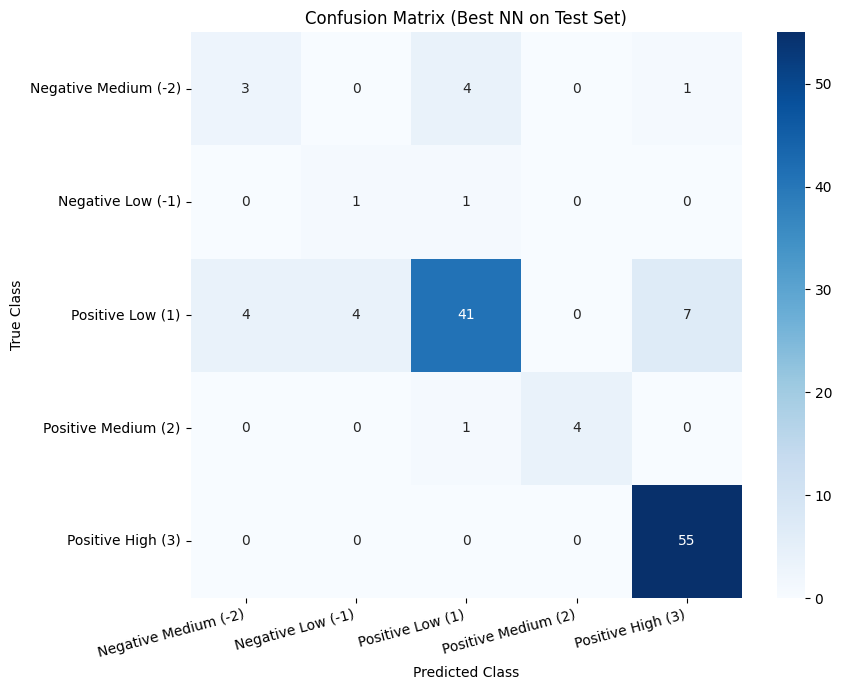

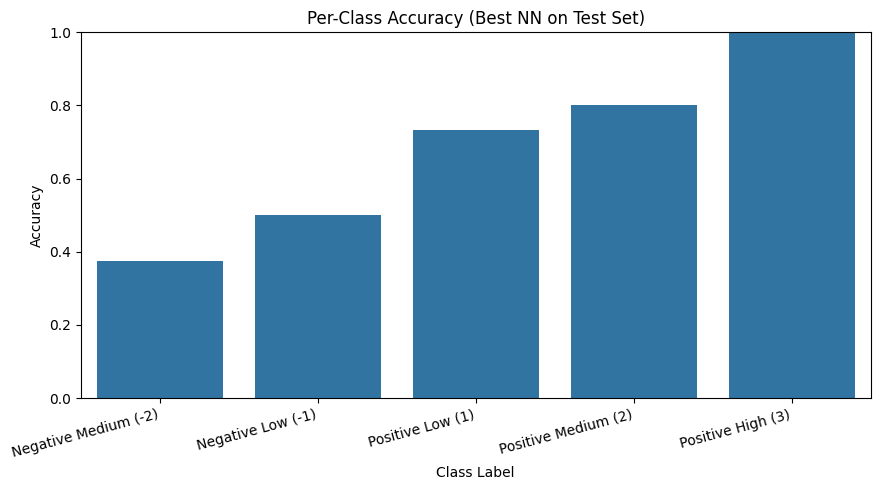

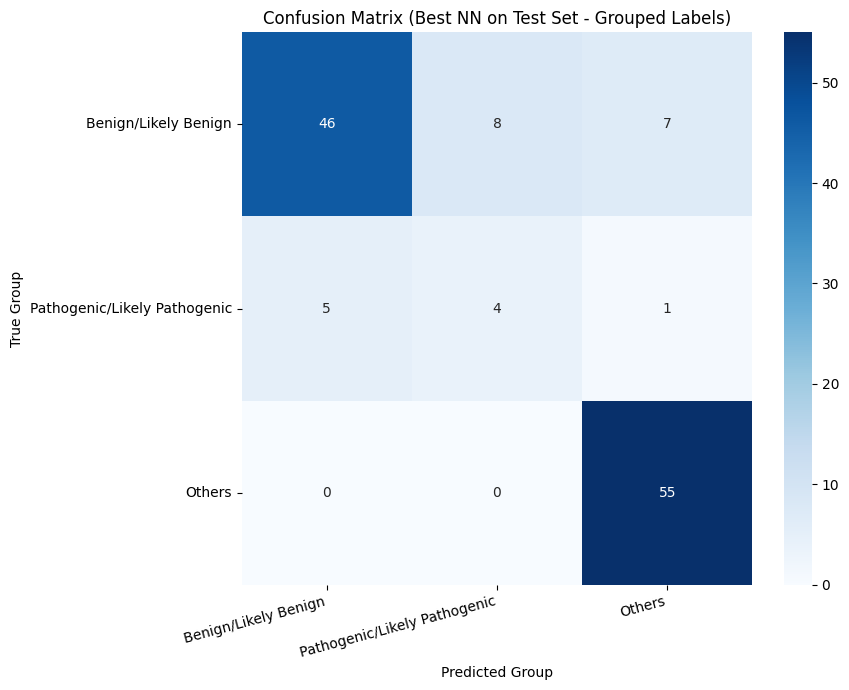

In [73]:
# Import necessary libraries for hyperparameter tuning and advanced techniques
from sklearn.model_selection import ParameterGrid
from torch.utils.data import WeightedRandomSampler
import torch.nn.functional as F # For Focal Loss
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

# Source: https://github.com/pytorch/pytorch/issues/7455#issuecomment-513062631
# (Adjusted slightly for clarity and stability)
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__()
        self.alpha = alpha # Can be a float or a tensor of shape [num_classes]
        self.gamma = gamma
        self.reduction = reduction
        self.weight = weight # Class weights (optional)

    def forward(self, inputs, targets):
        # inputs: [N, C], targets: [N]
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight) # Calculate CE loss per element
        pt = torch.exp(-ce_loss) # Probability of the true class

        # Handle alpha: If alpha is a tensor, select the weight for the target class
        if isinstance(self.alpha, torch.Tensor):
             # Ensure alpha tensor is on the same device as inputs
             alpha_t = self.alpha.gather(0, targets.data.view(-1)).to(inputs.device) # [N]
        elif isinstance(self.alpha, (float, int)):
             alpha_t = self.alpha # Use the same alpha for all classes if it's a float
        else:
             raise TypeError("alpha must be a float or a Tensor")


        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else: # 'none'
            return focal_loss


if X_nn.shape[0] > 0: # Proceed only if embeddings were generated
    # --- 2. Prepare Data for PyTorch ---
    print("\nPreparing data for PyTorch...")

    # Filter out samples with label 0
    non_zero_indices = y_nn_original != 0
    X_nn_filtered = X_nn[non_zero_indices]
    y_nn_filtered = y_nn_original[non_zero_indices]

    print(f"Filtered out {len(X_nn) - len(X_nn_filtered)} samples with label 0.")
    print(f"Remaining samples: {len(X_nn_filtered)}")

    # Now encode the labels (excluding 0)
    le = LabelEncoder()
    y_nn_encoded = le.fit_transform(y_nn_filtered)
    num_classes = len(le.classes_)

    # Define meaningful names for the classes
    class_names = {
        -3: 'Negative High (-3)',
        -2: 'Negative Medium (-2)',
        -1: 'Negative Low (-1)',
        1: 'Positive Low (1)',
        2: 'Positive Medium (2)',
        3: 'Positive High (3)'
    }
    # Ensure target names are ordered correctly based on LabelEncoder's classes_
    target_names = [class_names[i] for i in le.classes_]

    print(f"Original labels encoded to {num_classes} classes.")
    print(f"Labels (encoded): {np.unique(y_nn_encoded)}")
    print("Class mapping (Encoded Value: Class Name):")
    for i, name in enumerate(target_names):
        print(f"  {i}: {name}")

    # Split data into training, validation, and testing sets
    X_train_val, X_test_nn, y_train_val, y_test_nn = train_test_split(
        X_nn_filtered, y_nn_encoded, test_size=0.15, random_state=42, stratify=y_nn_encoded
    )
    X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
        X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val # 0.15 / (1-0.15) approx 0.1765
    )

    print(f"\nData split into training ({X_train_nn.shape[0]} samples), validation ({X_val_nn.shape[0]} samples), and testing ({X_test_nn.shape[0]} samples).")

    # Convert NumPy arrays to PyTorch tensors
    X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train_nn, dtype=torch.long)
    X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val_nn, dtype=torch.long)
    X_test_tensor = torch.tensor(X_test_nn, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test_nn, dtype=torch.long)

    # --- Address Class Imbalance with Weighted Sampling ---
    print("\nAddressing class imbalance...")
    class_counts_train = np.bincount(y_train_nn, minlength=num_classes)
    print(f"Training set class counts (encoded): {class_counts_train}")
    for i, count in enumerate(class_counts_train):
         # Ensure index i exists in target_names before accessing
         if i < len(target_names):
             print(f"  Class {i} ({target_names[i]}): {count} samples")
         else:
             print(f"  Class {i} (Unknown Name): {count} samples")


    if np.any(class_counts_train == 0):
        print("Warning: Some classes have zero samples in the training set. Weighted sampling might not work correctly.")
        use_weighted_sampler = False
        sampler = None # Ensure sampler is None
    else:
        class_weights_sample = 1. / torch.tensor(class_counts_train, dtype=torch.float32)
        # Ensure y_train_nn contains valid indices for class_weights_sample
        if y_train_nn.max() >= len(class_weights_sample):
             raise IndexError(f"Max label index {y_train_nn.max()} is out of bounds for class weights tensor with size {len(class_weights_sample)}")
        sample_weights = class_weights_sample[y_train_nn] # Assign weight to each sample
        sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
        print("Using WeightedRandomSampler for training data.")
        use_weighted_sampler = True

    # Create TensorDatasets
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

    # Create DataLoaders
    batch_size = 32 # Keep batch size reasonable, can be tuned

    # Use sampler only for the training loader
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        sampler=sampler if use_weighted_sampler else None,
        shuffle=not use_weighted_sampler # Shuffle is False if sampler is used
    )
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


    # --- 3. Define the Neural Network ---
    # Model definition remains the same structure, but output_dim is now num_classes
    print("\nDefining the Neural Network...")

    class ResidualBlock(nn.Module):
        """A residual block with two linear layers, BatchNorm, ReLU, and Dropout."""
        def __init__(self, in_dim, out_dim, dropout_rate):
            super(ResidualBlock, self).__init__()
            self.block = nn.Sequential(
                nn.Linear(in_dim, out_dim),
                nn.BatchNorm1d(out_dim),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
                nn.Linear(out_dim, out_dim),
                nn.BatchNorm1d(out_dim),
            )
            self.shortcut = nn.Sequential()
            if in_dim != out_dim:
                self.shortcut = nn.Sequential(
                    nn.Linear(in_dim, out_dim),
                    nn.BatchNorm1d(out_dim)
                )
            self.final_relu = nn.ReLU()
            self.final_dropout = nn.Dropout(dropout_rate)

        def forward(self, x):
            out = self.block(x)
            shortcut_out = self.shortcut(x)
            out += shortcut_out
            out = self.final_relu(out)
            out = self.final_dropout(out)
            return out

    class DNABERTClassifier(nn.Module):
        """Classifier using DNA-BERT embeddings with residual blocks."""
        # Adjusted output_dim to be passed dynamically
        def __init__(self, input_dim, hidden_dims=[512, 256, 128], output_dim=6, dropout_rate=0.4): # Default output_dim is now 6
            super(DNABERTClassifier, self).__init__()
            # Ensure hidden_dims is not empty
            if not hidden_dims:
                 raise ValueError("hidden_dims list cannot be empty")

            self.input_layer = nn.Sequential(
                nn.Linear(input_dim, hidden_dims[0]),
                nn.BatchNorm1d(hidden_dims[0]),
                nn.ReLU(),
                nn.Dropout(dropout_rate)
            )
            self.hidden_layers = nn.ModuleList()
            current_dim = hidden_dims[0]
            # Create residual blocks for layers beyond the first
            if len(hidden_dims) > 1:
                 for hidden_dim in hidden_dims[1:]:
                     self.hidden_layers.append(
                         ResidualBlock(current_dim, hidden_dim, dropout_rate)
                     )
                     current_dim = hidden_dim
            # The output layer takes input from the last hidden dimension (or the first if only one)
            self.output_layer = nn.Linear(current_dim, output_dim)


        def forward(self, x):
            out = self.input_layer(x)
            for layer in self.hidden_layers:
                out = layer(out)
            out = self.output_layer(out)
            return out

    # --- 4. Hyperparameter Tuning Setup ---
    # Define parameter grid with a variety of settings (120 combinations)
    param_grid = {
        'lr': [0.001, 0.0005, 0.0001],
        'weight_decay': [0.01, 0.05, 0.1, 0.2],
        'dropout_rate': [0.3, 0.5],
        'loss_fn': ['CrossEntropyLoss', 'FocalLoss'],
        'hidden_dims': [
            [128],                  # Single layer
            [256],                  # Single layer
            [512],                  # Single layer
            [128, 64],              # Two layers
            [256, 128],             # Two layers
            [512, 256],             # Two layers
            [256, 128, 64],         # Three layers
            [512, 256, 128],        # Three layers
            [1024, 512, 256],       # Three layers
            [512, 256, 128, 64]     # Four layers
        ],
        'optimizer': ['Adam', 'AdamW']
    }

    # Calculate total combinations
    total_combinations = 1
    for param_values in param_grid.values():
        total_combinations *= len(param_values)
    
    print(f"Total hyperparameter combinations: {total_combinations}")
    
    # Limit to 120 combinations if needed
    if total_combinations > 120:
        print(f"Limiting to 120 combinations out of {total_combinations} possible combinations")
        # You could implement a strategy to select a subset of combinations here
        # For simplicity, we'll just take the first 120 combinations
        grid = list(ParameterGrid(param_grid))[:120]
    else:
        grid = list(ParameterGrid(param_grid))
    
    print(f"Will evaluate {len(grid)} hyperparameter combinations")

    best_val_acc = 0.0
    best_params = None
    best_model_state_grid = None
    results = []

    print(f"\nStarting Grid Search with {len(grid)} combinations...")

    # Check for GPU availability once
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    input_dim = X_train_nn.shape[1]

    # --- Loop through Hyperparameters ---
    for i, params in enumerate(grid):
        print(f"\n--- Combination {i+1}/{len(grid)} ---")
        print(f"Parameters: {params}")

        # --- Instantiate Model with current params ---
        current_dropout = params['dropout_rate']
        current_hidden_dims = params['hidden_dims'] # Get hidden dims from grid
        # Pass the correct number of output classes and current hidden_dims
        nn_model = DNABERTClassifier(input_dim, current_hidden_dims, num_classes, dropout_rate=current_dropout)
        nn_model.to(device)
        # print(nn_model) # Optional: print model summary for each config

        # --- Define Loss Function ---
        # Calculate class weights for loss function based on training data
        if np.any(class_counts_train == 0):
             class_weights_loss = None
             print("Warning: Cannot calculate class weights for loss due to missing classes in train set.")
        else:
             # Ensure tensor is created correctly even if some counts are zero (though handled above)
             class_weights_tensor = 1. / torch.tensor(class_counts_train.astype(np.float32) + 1e-9) # Add epsilon for stability
             class_weights_loss = class_weights_tensor.to(device)
             print(f"Calculated class weights for loss function: {class_weights_loss.cpu().numpy()}")


        if params['loss_fn'] == 'FocalLoss':
             # You might want to tune alpha and gamma for Focal Loss as well
             # Alpha can also be the class_weights_tensor
             criterion = FocalLoss(alpha=class_weights_loss if class_weights_loss is not None else 1.0, gamma=2.0, reduction='mean')
             print("Using FocalLoss.")
        else: # Default to CrossEntropyLoss
             criterion = nn.CrossEntropyLoss(weight=class_weights_loss)
             print("Using CrossEntropyLoss (with weights if available).")


        # --- Define Optimizer ---
        optimizer = optim.AdamW(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        print("Using Optimizer: AdamW")

        # --- Define Scheduler ---
        # Increased patience for scheduler as well
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=15, verbose=False) # Quieter scheduler during grid search


        # --- Training Loop (for current hyperparameter set) ---
        num_epochs = 500 # Max epochs per combination (Increased as requested)
        train_losses_hist = []
        train_accuracies_hist = []
        val_accuracies_hist = []
        val_losses_hist = []
        current_best_val_acc = 0.0 # Best validation accuracy for *this* combination
        best_model_state_current = None
        patience_early_stopping = 200 # Increased patience for early stopping to aim for 200 epochs
        epochs_no_improve = 0

        print(f"Training with lr={params['lr']}, wd={params['weight_decay']}, dropout={current_dropout}, loss={params['loss_fn']}, hidden_dims={current_hidden_dims}...")

        for epoch in range(num_epochs):
            nn_model.train()
            running_loss = 0.0
            correct_train = 0
            total_train = 0

            # Simplified progress bar for grid search
            progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} Train", leave=False)
            for inputs, labels in progress_bar: # Use train_loader directly
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = nn_model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                # torch.nn.utils.clip_grad_norm_(nn_model.parameters(), max_norm=1.0) # Optional
                optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total_train += labels.size(0)
                correct_train += (predicted == labels).sum().item()

                # Update progress bar description
                progress_bar.set_postfix({'loss': loss.item()})


            # Avoid division by zero if dataset is empty
            epoch_train_loss = running_loss / len(train_loader.dataset) if len(train_loader.dataset) > 0 else 0.0
            epoch_train_acc = correct_train / total_train if total_train > 0 else 0.0
            train_losses_hist.append(epoch_train_loss)
            train_accuracies_hist.append(epoch_train_acc)

            # --- Validation Step ---
            nn_model.eval()
            correct_val = 0
            total_val = 0
            running_val_loss = 0.0
            with torch.no_grad():
                for inputs_val, labels_val in val_loader:
                    inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
                    outputs_val = nn_model(inputs_val)
                    loss_val = criterion(outputs_val, labels_val) # Use same criterion
                    running_val_loss += loss_val.item() * inputs_val.size(0)
                    _, predicted_val = torch.max(outputs_val.data, 1)
                    total_val += labels_val.size(0)
                    correct_val += (predicted_val == labels_val).sum().item()

            epoch_val_loss = running_val_loss / len(val_loader.dataset) if len(val_loader.dataset) > 0 else 0.0
            epoch_val_acc = correct_val / total_val if total_val > 0 else 0.0
            val_losses_hist.append(epoch_val_loss)
            val_accuracies_hist.append(epoch_val_acc)

            # Print progress every few epochs during grid search
            if (epoch + 1) % 10 == 0 or epoch == 0:
                 print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                       f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

            # Step the scheduler based on validation accuracy
            scheduler.step(epoch_val_acc)

            # Early Stopping Check & Save Best Model for this combination
            if epoch_val_acc > current_best_val_acc:
                current_best_val_acc = epoch_val_acc
                epochs_no_improve = 0
                best_model_state_current = nn_model.state_dict() # Save the best state for this run
                # print(f"    -> New best val acc for this combo: {current_best_val_acc:.4f}") # Verbose
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience_early_stopping:
                print(f"  Early stopping triggered for this combination after {epoch + 1} epochs.")
                break
        # --- End Training Loop for Combination ---

        print(f"Combination {i+1} finished. Best Validation Accuracy: {current_best_val_acc:.4f}")
        # Store the full parameters including hidden_dims
        results.append({'params': params, 'best_val_acc': current_best_val_acc, 'epochs': epoch + 1})

        # --- Update Overall Best Model (based on validation accuracy) ---
        if current_best_val_acc > best_val_acc:
            print(f"!!! Found new overall best validation accuracy: {current_best_val_acc:.4f} !!!")
            best_val_acc = current_best_val_acc
            best_params = params # Store the entire best parameter set
            best_model_state_grid = best_model_state_current # Keep the state dict of the best model

    # --- End Hyperparameter Search ---

    print("\n--- Training Complete ---")
    # Sort results by validation accuracy
    results.sort(key=lambda x: x['best_val_acc'], reverse=True)
    print("Top 10 Training Results (based on Validation Accuracy):")
    for i, res in enumerate(results[:10]): # Print top 10 results
        # Ensure all parameters including hidden_dims are printed
        print(f"  {i+1}. Params: {res['params']}, Val Acc: {res['best_val_acc']:.4f}, Epochs: {res['epochs']}")

    if best_params is None:
        print("\nError: No best model found. Training might have failed or produced no valid results.")
        # Handle error appropriately, maybe raise an exception or exit
        raise SystemExit("Stopping execution: Training failed.")
    else:
        print(f"\nBest hyperparameters: {best_params}")
        print(f"Best validation accuracy achieved: {best_val_acc:.4f}")

        # --- Load the Best Model Found During Training ---
        print("\nLoading the best model configuration...")
        best_dropout = best_params['dropout_rate']
        best_hidden_dims = best_params['hidden_dims'] # Get best hidden dims from best_params
        # Instantiate with correct output_dim (num_classes) and best hidden_dims
        nn_model_best = DNABERTClassifier(input_dim, best_hidden_dims, num_classes, dropout_rate=best_dropout)
        if best_model_state_grid:
             nn_model_best.load_state_dict(best_model_state_grid)
             print("Loaded best model state from training.")
        else:
             print("Warning: Could not load best model state. Using initialized model with best params.")
             # This might happen if training failed for the best params or state wasn't saved correctly.
             # Consider retraining the best model from scratch here if needed.

        nn_model_best.to(device)


    # --- 5. (Optional) Plot Training Curves for the Best Model ---
    # Note: The training curves plotted here would be from the *last* run in the grid search,
    # not necessarily the *best* run unless you store and retrieve those specific histories.
    # For simplicity, we skip plotting the curves from the grid search process itself.
    # If needed, you'd store train_losses_hist, etc., associated with best_params.
    print("\nSkipping training curve plots for grid search simplicity.")


    # --- 6. Evaluate the BEST Neural Network on the **Test Set** ---
    print("\nEvaluating the Best Neural Network (from training) on the Test Set...")

    nn_model_best.eval() # Set the best model to evaluation mode
    y_pred_list = []
    y_true_list = []
    test_probs_list = [] # Store probabilities for more detailed analysis

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Evaluating Best Model"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = nn_model_best(inputs)
            probabilities = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs.data, 1)

            y_pred_list.extend(predicted.cpu().numpy())
            y_true_list.extend(labels.cpu().numpy())
            test_probs_list.extend(probabilities.cpu().numpy())

    y_pred_nn = np.array(y_pred_list)
    y_test_nn_eval = np.array(y_true_list)
    y_test_probs = np.array(test_probs_list)

    # --- Detailed Evaluation ---
    accuracy_nn = accuracy_score(y_test_nn_eval, y_pred_nn)
    print(f"\nTest Accuracy (Best NN): {accuracy_nn:.4f}")

    print("\nClassification Report (Best NN):")
    print(classification_report(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes), target_names=target_names, zero_division=0))

    print("\nConfusion Matrix (Best NN):")
    cm = confusion_matrix(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes))

    # Calculate per-class accuracy from confusion matrix
    # Add epsilon to avoid division by zero if a class has no samples in the test set
    cm_sum_axis1 = cm.sum(axis=1)
    per_class_acc = np.divide(cm.diagonal(), cm_sum_axis1, out=np.zeros_like(cm.diagonal(), dtype=float), where=cm_sum_axis1!=0)

    print("\nPer-Class Accuracy (Best NN):")
    for i, class_name in enumerate(target_names):
        # Handle cases where a class might have 0 true samples in the test set (division by zero)
        if cm.sum(axis=1)[i] > 0:
             print(f"  Class {class_name}: {per_class_acc[i]:.4f}")
        else:
             print(f"  Class {class_name}: N/A (no true samples in test set)")

    # --- Group Evaluation (Secondary Evaluation) ---
    print("\n--- Group Evaluation (Secondary Evaluation) ---")
    
    # Define the grouping mapping
    # Group 1: Benign or Likely Benign (classes 1 and 2)
    # Group 2: Pathogenic or Likely Pathogenic (classes -1 and -2)
    
    # Get the original class indices from LabelEncoder
    original_class_indices = {}
    for i, original_class in enumerate(le.classes_):
        original_class_indices[original_class] = i
    
    # Create group mapping
    group_mapping = {}
    for encoded_idx, original_class in enumerate(le.classes_):
        if original_class in [1, 2]:  # Positive Low (1) and Positive Medium (2)
            group_mapping[encoded_idx] = 0  # Group 0: Benign or Likely Benign
        elif original_class in [-1, -2]:  # Negative Low (-1) and Negative Medium (-2)
            group_mapping[encoded_idx] = 1  # Group 1: Pathogenic or Likely Pathogenic
        else:
            group_mapping[encoded_idx] = 2  # Group 2: Others (like -3 and 3)
    
    # Map predictions and true labels to groups
    y_true_grouped = np.array([group_mapping[label] for label in y_test_nn_eval])
    y_pred_grouped = np.array([group_mapping[pred] for pred in y_pred_nn])
    
    # Define group names
    group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
    
    # Filter to only include groups that exist in the data
    unique_groups = np.unique(np.concatenate((y_true_grouped, y_pred_grouped)))
    target_names_grouped = [group_names[g] for g in unique_groups]
    
    # Calculate metrics for grouped evaluation
    accuracy_grouped = accuracy_score(y_true_grouped, y_pred_grouped)
    print(f"\nGrouped Test Accuracy: {accuracy_grouped:.4f}")
    
    print("\nGrouped Classification Report:")
    print(classification_report(y_true_grouped, y_pred_grouped, 
                               labels=unique_groups, 
                               target_names=target_names_grouped, 
                               zero_division=0))
    
    # Confusion matrix for grouped evaluation
    cm_grouped = confusion_matrix(y_true_grouped, y_pred_grouped, labels=unique_groups)
    
    # Calculate per-group accuracy
    cm_grouped_sum_axis1 = cm_grouped.sum(axis=1)
    per_group_acc = np.divide(cm_grouped.diagonal(), cm_grouped_sum_axis1, 
                             out=np.zeros_like(cm_grouped.diagonal(), dtype=float), 
                             where=cm_grouped_sum_axis1!=0)
    
    print("\nPer-Group Accuracy:")
    for i, group_name in enumerate(target_names_grouped):
        if cm_grouped_sum_axis1[i] > 0:
            print(f"  Group {group_name}: {per_group_acc[i]:.4f}")
        else:
            print(f"  Group {group_name}: N/A (no true samples in test set)")

    # Display confusion matrix with labels using seaborn
    try:
        import seaborn as sns
        plt.figure(figsize=(9, 7)) # Adjusted size for potentially more classes
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=target_names, yticklabels=target_names)
        plt.xlabel('Predicted Class')
        plt.ylabel('True Class')
        plt.title('Confusion Matrix (Best NN on Test Set)')
        plt.xticks(rotation=15, ha='right') # Improve label readability
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

        # Plot per-class accuracy
        plt.figure(figsize=(9, 5)) # Adjusted size
        # Ensure per_class_acc has the correct length matching target_names
        if len(target_names) == len(per_class_acc):
             sns.barplot(x=target_names, y=per_class_acc)
             plt.xlabel('Class Label')
             plt.ylabel('Accuracy')
             plt.title('Per-Class Accuracy (Best NN on Test Set)')
             plt.ylim(0, 1) # Accuracy is between 0 and 1
             plt.xticks(rotation=15, ha='right') # Improve label readability
             plt.tight_layout()
             plt.show()
        else:
             print(f"Warning: Mismatch between number of target names ({len(target_names)}) and per-class accuracy values ({len(per_class_acc)}). Skipping bar plot.")

        # Plot grouped confusion matrix
        plt.figure(figsize=(9, 7)) # Adjusted size for potentially more classes
        sns.heatmap(cm_grouped, annot=True, fmt='d', cmap='Blues',
                    xticklabels=target_names_grouped, yticklabels=target_names_grouped)
        plt.xlabel('Predicted Group')
        plt.ylabel('True Group')
        plt.title('Confusion Matrix (Best NN on Test Set - Grouped Labels)')
        plt.xticks(rotation=15, ha='right') # Improve label readability
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

        # Plot per-class accuracy
    except ImportError:
        print("Seaborn not installed. Skipping heatmap and bar plot visualization.")
        print("Confusion Matrix (row=True, col=Predicted):")
        try:
            import pandas as pd
            print(pd.DataFrame(cm, index=target_names, columns=target_names))
        except ImportError:
             print(cm)

else:
    print("\nNo combined embeddings were generated. Cannot proceed with NN training and evaluation.")
    # raise SystemExit("Stopping execution: No embeddings generated.") # Or similar


### Classifier training Using Hyperparmaters and DNA-BERT Embeddings Only

In [29]:
# Import necessary libraries for hyperparameter tuning and advanced techniques

# Add this check at the beginning of your cell to ensure variables exist
if 'X_nn' not in locals() or 'y_nn_original' not in locals():
    raise NameError(
        "Required variables 'X_nn' and 'y_nn_original' are not defined. "
        "Please run the embedding generation cells first to create these variables."
    )

# Verify dimensions match
if X_nn.shape[0] != len(y_nn_original):
    raise ValueError(
        f"Dimension mismatch: X_nn has {X_nn.shape[0]} samples but "
        f"y_nn_original has {len(y_nn_original)} samples. "
        "These must match. Please regenerate embeddings or labels."
    )

# Now proceed with your existing code
print("\nPreparing data for PyTorch...")

# Filter out samples with label 0
non_zero_indices = y_nn_original != 0
X_nn_filtered = X_nn[non_zero_indices]
y_nn_filtered = y_nn_original[non_zero_indices]

# ...existing code...

from sklearn.model_selection import ParameterGrid
from torch.utils.data import WeightedRandomSampler
import torch.nn.functional as F # For Focal Loss
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

# --- Focal Loss Implementation (Optional, good for class imbalance) ---
# Source: https://github.com/pytorch/pytorch/issues/7455#issuecomment-513062631
# (Adjusted slightly for clarity and stability)
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__()
        self.alpha = alpha # Can be a float or a tensor of shape [num_classes]
        self.gamma = gamma
        self.reduction = reduction
        self.weight = weight # Class weights (optional)

    def forward(self, inputs, targets):
        # inputs: [N, C], targets: [N]
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight) # Calculate CE loss per element
        pt = torch.exp(-ce_loss) # Probability of the true class

        # Handle alpha: If alpha is a tensor, select the weight for the target class
        if isinstance(self.alpha, torch.Tensor):
            # Ensure alpha tensor is on the same device as inputs
            alpha_t = self.alpha.gather(0, targets.data.view(-1)).to(inputs.device) # [N]
        elif isinstance(self.alpha, (float, int)):
            alpha_t = self.alpha # Use the same alpha for all classes if it's a float
        else:
            raise TypeError("alpha must be a float or a Tensor")

        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else: # 'none'
            return focal_loss

# Placeholder for X_nn and y_nn_original assuming they are loaded or generated before this script part
# For testing purposes, let's create dummy data if it's not defined.
# IMPORTANT: Replace these with your actual data loading.
if 'X_nn' not in globals():
    print("Warning: X_nn not found. Creating dummy data for demonstration.")
    X_nn = np.random.rand(200, 768) # Example: 200 samples, 768 features (typical for BERT embeddings)
if 'y_nn_original' not in globals():
    print("Warning: y_nn_original not found. Creating dummy data for demonstration.")
    # Dummy labels including 0 and other classes from your example
    possible_labels = [-3, -2, -1, 0, 1, 2, 3]
    y_nn_original = np.random.choice(possible_labels, 200)


if X_nn.shape[0] > 0: # Proceed only if embeddings were generated
    # --- 2. Prepare Data for PyTorch ---
    print("\nPreparing data for PyTorch...")

    # Filter out samples with label 0
    non_zero_indices = y_nn_original != 0
    X_nn_filtered = X_nn[non_zero_indices]
    y_nn_filtered = y_nn_original[non_zero_indices]

    # Check if any data remains after filtering
    if X_nn_filtered.shape[0] == 0:
        print("Error: No samples remaining after filtering out label 0. Cannot proceed.")
        # raise SystemExit("Stopping execution: No data after filtering.")
    else:
        print(f"Filtered out {len(X_nn) - len(X_nn_filtered)} samples with label 0.")
        print(f"Remaining samples: {len(X_nn_filtered)}")

        # Now encode the labels (excluding 0)
        le = LabelEncoder()
        y_nn_encoded = le.fit_transform(y_nn_filtered)
        num_classes = len(le.classes_)

        # Define meaningful names for the classes
        class_names = {
            -3: 'Negative High (-3)',
            -2: 'Negative Medium (-2)',
            -1: 'Negative Low (-1)',
            1: 'Positive Low (1)',
            2: 'Positive Medium (2)',
            3: 'Positive High (3)'
        }
        # Ensure target names are ordered correctly based on LabelEncoder's classes_
        target_names = [class_names[i] for i in le.classes_]

        print(f"Original labels encoded to {num_classes} classes.")
        print(f"Labels (encoded): {np.unique(y_nn_encoded)}")
        print("Class mapping (Encoded Value: Class Name):")
        for i, name in enumerate(target_names):
            print(f"  {i}: {name}")

        # Split data into training, validation, and testing sets
        X_train_val, X_test_nn, y_train_val, y_test_nn = train_test_split(
            X_nn_filtered, y_nn_encoded, test_size=0.15, random_state=42, stratify=y_nn_encoded if num_classes > 1 and len(y_nn_encoded) > num_classes else None
        )
        # Ensure X_train_val is not too small for the next split
        val_split_size = 0.1765
        if len(X_train_val) * val_split_size < 1 or len(np.unique(y_train_val)) < 2 : # if less than 1 sample for val or not enough classes for stratify
             print(f"Warning: Not enough samples or classes in X_train_val for stratified validation split. Using unstratified split or adjusting test size.")
             X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
                X_train_val, y_train_val, test_size=min(val_split_size, 0.5 if len(X_train_val)>1 else 0.0), random_state=42 # ensure test_size is less than 1
            )
        else:
            X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
                X_train_val, y_train_val, test_size=val_split_size, random_state=42, stratify=y_train_val
            )


        print(f"\nData split into training ({X_train_nn.shape[0]} samples), validation ({X_val_nn.shape[0]} samples), and testing ({X_test_nn.shape[0]} samples).")

        # Convert NumPy arrays to PyTorch tensors
        X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
        y_train_tensor = torch.tensor(y_train_nn, dtype=torch.long)
        X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32) if X_val_nn.shape[0] > 0 else torch.empty(0, X_train_nn.shape[1], dtype=torch.float32)
        y_val_tensor = torch.tensor(y_val_nn, dtype=torch.long) if y_val_nn.shape[0] > 0 else torch.empty(0, dtype=torch.long)
        X_test_tensor = torch.tensor(X_test_nn, dtype=torch.float32)
        y_test_tensor = torch.tensor(y_test_nn, dtype=torch.long)


        # --- Address Class Imbalance with Weighted Sampling ---
        print("\nAddressing class imbalance...")
        if len(y_train_nn) > 0:
            class_counts_train = np.bincount(y_train_nn, minlength=num_classes)
            print(f"Training set class counts (encoded): {class_counts_train}")
            for i, count in enumerate(class_counts_train):
                if i < len(target_names):
                    print(f"  Class {i} ({target_names[i]}): {count} samples")
                else:
                    print(f"  Class {i} (Unknown Name): {count} samples")

            if np.any(class_counts_train == 0) and len(y_train_nn) > 0 : # Check if any class has zero samples
                print("Warning: Some classes have zero samples in the training set. Weighted sampling might not work correctly or class weights for loss might be problematic.")
                use_weighted_sampler = False
                sampler = None
            elif len(y_train_nn) == 0:
                print("Warning: Training set is empty. Skipping weighted sampling.")
                use_weighted_sampler = False
                sampler = None
                class_counts_train = np.zeros(num_classes, dtype=int) # Ensure class_counts_train exists
            else:
                class_weights_sample = 1. / torch.tensor(class_counts_train, dtype=torch.float32)
                if y_train_nn.max() >= len(class_weights_sample):
                    raise IndexError(f"Max label index {y_train_nn.max()} is out of bounds for class weights tensor with size {len(class_weights_sample)}")
                sample_weights = class_weights_sample[y_train_nn]
                sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
                print("Using WeightedRandomSampler for training data.")
                use_weighted_sampler = True
        else:
            print("Training set is empty. Skipping weighted sampling and class count display.")
            use_weighted_sampler = False
            sampler = None
            class_counts_train = np.zeros(num_classes, dtype=int) # Ensure class_counts_train exists for later use


        # Create TensorDatasets
        train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
        val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
        test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

        # Create DataLoaders
        batch_size = 32

        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            sampler=sampler if use_weighted_sampler and len(train_dataset) > 0 else None, # Sampler only if valid# Import necessary libraries for hyperparameter tuning and advanced techniques
from sklearn.model_selection import ParameterGrid
from torch.utils.data import WeightedRandomSampler
import torch.nn.functional as F
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

# --- Focal Loss Implementation ---
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        self.weight = weight

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight)
        pt = torch.exp(-ce_loss)
        
        if isinstance(self.alpha, torch.Tensor):
            alpha_t = self.alpha.gather(0, targets.data.view(-1)).to(inputs.device)
        elif isinstance(self.alpha, (float, int)):
            alpha_t = self.alpha
        else:
            raise TypeError("alpha must be a float or a Tensor")
        
        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

# Check if required variables exist
if 'X_nn' not in locals() or 'y_nn_original' not in locals():
    raise NameError(
        "Required variables 'X_nn' and 'y_nn_original' are not defined. "
        "Please run the embedding generation cells first to create these variables."
    )

# Verify dimensions match
if X_nn.shape[0] != len(y_nn_original):
    raise ValueError(
        f"Dimension mismatch: X_nn has {X_nn.shape[0]} samples but "
        f"y_nn_original has {len(y_nn_original)} samples. "
        "These must match. Please regenerate embeddings or labels."
    )

if X_nn.shape[0] > 0:
    # --- 2. Prepare Data for PyTorch ---
    print("\nPreparing data for PyTorch...")
    
    # Filter out samples with label 0
    non_zero_indices = y_nn_original != 0
    X_nn_filtered = X_nn[non_zero_indices]
    y_nn_filtered = y_nn_original[non_zero_indices]
    
    if X_nn_filtered.shape[0] == 0:
        raise ValueError("No samples remaining after filtering out label 0. Cannot proceed.")
    
    print(f"Filtered out {len(X_nn) - len(X_nn_filtered)} samples with label 0.")
    print(f"Remaining samples: {len(X_nn_filtered)}")
    
    # Encode the labels (excluding 0)
    le = LabelEncoder()
    y_nn_encoded = le.fit_transform(y_nn_filtered)
    num_classes = len(le.classes_)
    
    # Define meaningful names for the classes
    class_names = {
        -3: 'Negative High (-3)',
        -2: 'Negative Medium (-2)',
        -1: 'Negative Low (-1)',
        1: 'Positive Low (1)',
        2: 'Positive Medium (2)',
        3: 'Positive High (3)'
    }
    target_names = [class_names.get(i, f'Class {i}') for i in le.classes_]
    
    print(f"Original labels encoded to {num_classes} classes.")
    print(f"Labels (encoded): {np.unique(y_nn_encoded)}")
    print("Class mapping (Encoded Value: Class Name):")
    for i, name in enumerate(target_names):
        print(f"  {i}: {name}")
    
    # Split data into training, validation, and testing sets
    X_train_val, X_test_nn, y_train_val, y_test_nn = train_test_split(
        X_nn_filtered, y_nn_encoded, test_size=0.15, random_state=42,
        stratify=y_nn_encoded if num_classes > 1 and len(y_nn_encoded) > num_classes else None
    )
    
    val_split_size = 0.1765
    if len(X_train_val) * val_split_size < 1 or len(np.unique(y_train_val)) < 2:
        print(f"Warning: Not enough samples or classes for stratified validation split. Using unstratified split.")
        X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
            X_train_val, y_train_val,
            test_size=min(val_split_size, 0.5 if len(X_train_val) > 1 else 0.0),
            random_state=42
        )
    else:
        X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
            X_train_val, y_train_val, test_size=val_split_size,
            random_state=42, stratify=y_train_val
        )
    
    print(f"\nData split: Train={X_train_nn.shape[0]}, Val={X_val_nn.shape[0]}, Test={X_test_nn.shape[0]}")
    
    # Convert NumPy arrays to PyTorch tensors
    X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train_nn, dtype=torch.long)
    X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32) if X_val_nn.shape[0] > 0 else torch.empty(0, X_train_nn.shape[1], dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val_nn, dtype=torch.long) if y_val_nn.shape[0] > 0 else torch.empty(0, dtype=torch.long)
    X_test_tensor = torch.tensor(X_test_nn, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test_nn, dtype=torch.long)
    
    # --- Address Class Imbalance with Weighted Sampling ---
    print("\nAddressing class imbalance...")
    if len(y_train_nn) > 0:
        class_counts_train = np.bincount(y_train_nn, minlength=num_classes)
        print(f"Training set class counts (encoded): {class_counts_train}")
        for i, count in enumerate(class_counts_train):
            if i < len(target_names):
                print(f"  Class {i} ({target_names[i]}): {count} samples")
        
        if np.any(class_counts_train == 0):
            print("Warning: Some classes have zero samples. Weighted sampling disabled.")
            use_weighted_sampler = False
            sampler = None
        else:
            class_weights_sample = 1. / torch.tensor(class_counts_train, dtype=torch.float32)
            sample_weights = class_weights_sample[y_train_nn]
            sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
            print("Using WeightedRandomSampler for training data.")
            use_weighted_sampler = True
    else:
        use_weighted_sampler = False
        sampler = None
        class_counts_train = np.zeros(num_classes, dtype=int)
    
    # Create TensorDatasets
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    
    # Create DataLoaders
    batch_size = 32
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size,
        sampler=sampler if use_weighted_sampler and len(train_dataset) > 0 else None,
        shuffle=not (use_weighted_sampler and len(train_dataset) > 0) and len(train_dataset) > 0
    )
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False) if len(val_dataset) > 0 else None
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    # --- 3. Define the Neural Network ---
    print("\nDefining the Neural Network...")
    
    class ResidualBlock(nn.Module):
        def __init__(self, in_dim, out_dim, dropout_rate):
            super(ResidualBlock, self).__init__()
            self.block = nn.Sequential(
                nn.Linear(in_dim, out_dim),
                nn.BatchNorm1d(out_dim),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
                nn.Linear(out_dim, out_dim),
                nn.BatchNorm1d(out_dim),
            )
            self.shortcut = nn.Sequential()
            if in_dim != out_dim:
                self.shortcut = nn.Sequential(
                    nn.Linear(in_dim, out_dim),
                    nn.BatchNorm1d(out_dim)
                )
            self.final_relu = nn.ReLU()
            self.final_dropout = nn.Dropout(dropout_rate)
        
        def forward(self, x):
            out = self.block(x)
            shortcut_out = self.shortcut(x)
            out += shortcut_out
            out = self.final_relu(out)
            out = self.final_dropout(out)
            return out
    
    class DNABERTClassifier(nn.Module):
        def __init__(self, input_dim, hidden_dims=[512, 256, 128], output_dim=6, dropout_rate=0.4):
            super(DNABERTClassifier, self).__init__()
            if not hidden_dims:
                raise ValueError("hidden_dims list cannot be empty")
            
            self.input_layer = nn.Sequential(
                nn.Linear(input_dim, hidden_dims[0]),
                nn.BatchNorm1d(hidden_dims[0]),
                nn.ReLU(),
                nn.Dropout(dropout_rate)
            )
            self.hidden_layers = nn.ModuleList()
            current_dim = hidden_dims[0]
            if len(hidden_dims) > 1:
                for hidden_dim in hidden_dims[1:]:
                    self.hidden_layers.append(ResidualBlock(current_dim, hidden_dim, dropout_rate))
                    current_dim = hidden_dim
            self.output_layer = nn.Linear(current_dim, output_dim)
        
        def forward(self, x):
            out = self.input_layer(x)
            for layer in self.hidden_layers:
                out = layer(out)
            out = self.output_layer(out)
            return out
    
    # --- 4. Hyperparameter Setup ---
    param_grid = {
        'lr': [0.001],
        'weight_decay': [0.1],
        'dropout_rate': [0.3],
        'loss_fn': ['FocalLoss'],
        'hidden_dims': [[128]],
        'optimizer': ['AdamW']
    }
    
    grid = ParameterGrid(param_grid)
    best_val_acc = 0.0
    best_params = None
    best_model_state_grid = None
    results = []
    
    print(f"\nStarting Training (Grid Size: {len(grid)} combination)...")
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    input_dim = X_train_nn.shape[1]
    
    # --- Training Loop ---
    for i, params in enumerate(grid):
        print(f"\n--- Combination {i+1}/{len(grid)} ---")
        print(f"Parameters: {params}")
        
        current_dropout = params['dropout_rate']
        current_hidden_dims = params['hidden_dims']
        nn_model = DNABERTClassifier(input_dim, current_hidden_dims, num_classes, dropout_rate=current_dropout)
        nn_model.to(device)
        
        if len(y_train_nn) > 0 and np.any(class_counts_train == 0):
            class_weights_loss = None
            print("Warning: Cannot calculate class weights for loss due to missing classes.")
        elif len(y_train_nn) == 0:
            class_weights_loss = None
            print("Warning: Training set is empty. Cannot calculate class weights for loss.")
        else:
            class_weights_tensor = 1. / torch.tensor(class_counts_train.astype(np.float32) + 1e-9)
            class_weights_loss = class_weights_tensor.to(device)
            print(f"Calculated class weights for loss: {class_weights_loss.cpu().numpy()}")
        
        if params['loss_fn'] == 'FocalLoss':
            criterion = FocalLoss(alpha=class_weights_loss if class_weights_loss is not None else 1.0, gamma=2.0, reduction='mean')
            print("Using FocalLoss.")
        else:
            criterion = nn.CrossEntropyLoss(weight=class_weights_loss)
            print("Using CrossEntropyLoss.")
        
        optimizer_type = params.get('optimizer', 'AdamW')
        if optimizer_type == 'Adam':
            optimizer = optim.Adam(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        else:
            optimizer = optim.AdamW(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        print(f"Using Optimizer: {optimizer_type}")
        
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=15, verbose=False)
        
        num_epochs = 267
        train_losses_hist = []
        train_accuracies_hist = []
        val_accuracies_hist = []
        val_losses_hist = []
        current_best_val_acc = 0.0
        best_model_state_current = None
        patience_early_stopping = 200
        epochs_no_improve = 0
        
        print(f"Training with lr={params['lr']}, wd={params['weight_decay']}, dropout={current_dropout}...")
        
        if len(train_loader.dataset) == 0:
            print("Skipping training loop as training dataset is empty.")
        else:
            for epoch in range(num_epochs):
                nn_model.train()
                running_loss = 0.0
                correct_train = 0
                total_train = 0
                
                progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} Train", leave=False)
                for inputs, labels in progress_bar:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    outputs = nn_model(inputs)
                    loss = criterion(outputs, labels)
                    loss.backward()
                    optimizer.step()
                    
                    running_loss += loss.item() * inputs.size(0)
                    _, predicted = torch.max(outputs.data, 1)
                    total_train += labels.size(0)
                    correct_train += (predicted == labels).sum().item()
                    progress_bar.set_postfix({'loss': loss.item()})
                
                epoch_train_loss = running_loss / len(train_loader.dataset) if len(train_loader.dataset) > 0 else 0.0
                epoch_train_acc = correct_train / total_train if total_train > 0 else 0.0
                train_losses_hist.append(epoch_train_loss)
                train_accuracies_hist.append(epoch_train_acc)
                
                # Validation Step
                if val_loader is not None and len(val_loader.dataset) > 0:
                    nn_model.eval()
                    correct_val = 0
                    total_val = 0
                    running_val_loss = 0.0
                    with torch.no_grad():
                        for inputs_val, labels_val in val_loader:
                            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
                            outputs_val = nn_model(inputs_val)
                            loss_val = criterion(outputs_val, labels_val)
                            running_val_loss += loss_val.item() * inputs_val.size(0)
                            _, predicted_val = torch.max(outputs_val.data, 1)
                            total_val += labels_val.size(0)
                            correct_val += (predicted_val == labels_val).sum().item()
                    
                    epoch_val_loss = running_val_loss / len(val_loader.dataset) if len(val_loader.dataset) > 0 else 0.0
                    epoch_val_acc = correct_val / total_val if total_val > 0 else 0.0
                    val_losses_hist.append(epoch_val_loss)
                    val_accuracies_hist.append(epoch_val_acc)
                    
                    if (epoch + 1) % 10 == 0 or epoch == 0:
                        print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")
                    
                    scheduler.step(epoch_val_acc)
                    
                    if epoch_val_acc > current_best_val_acc:
                        current_best_val_acc = epoch_val_acc
                        epochs_no_improve = 0
                        best_model_state_current = nn_model.state_dict()
                    else:
                        epochs_no_improve += 1
                    
                    if epochs_no_improve >= patience_early_stopping and patience_early_stopping < num_epochs:
                        print(f"  Early stopping triggered after {epoch + 1} epochs.")
                        break
                else:
                    epoch_val_loss = float('nan')
                    epoch_val_acc = float('nan')
                    val_losses_hist.append(epoch_val_loss)
                    val_accuracies_hist.append(epoch_val_acc)
                    if (epoch + 1) % 10 == 0 or epoch == 0:
                        print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                              f"Val Loss: N/A, Val Acc: N/A (No validation data)")
                    if epoch_train_acc > current_best_val_acc:
                        current_best_val_acc = epoch_train_acc
                        best_model_state_current = nn_model.state_dict()
        
        print(f"Combination {i+1} finished. Best Val/Train Acc: {current_best_val_acc:.4f}")
        results.append({'params': params, 'best_val_acc': current_best_val_acc, 'epochs': epoch + 1 if 'epoch' in locals() else 0})
        
        if current_best_val_acc > best_val_acc:
            print(f"!!! Found new overall best accuracy: {current_best_val_acc:.4f} !!!")
            best_val_acc = current_best_val_acc
            best_params = params
            best_model_state_grid = best_model_state_current
    
    print("\n--- Training Complete ---")
    results.sort(key=lambda x: x['best_val_acc'], reverse=True)
    print("Training Results:")
    for res in results:
        print(f"  Params: {res['params']}, Val/Train Acc: {res['best_val_acc']:.4f}, Epochs: {res['epochs']}")
    
    if best_params is None:
        print("\nError: No best model found.")
    else:
        print(f"\nBest hyperparameters: {best_params}")
        print(f"Best accuracy achieved: {best_val_acc:.4f}")
        
        print("\nLoading the best model configuration...")
        best_dropout = best_params['dropout_rate']
        best_hidden_dims = best_params['hidden_dims']
        nn_model_best = DNABERTClassifier(input_dim, best_hidden_dims, num_classes, dropout_rate=best_dropout)
        if best_model_state_grid:
            nn_model_best.load_state_dict(best_model_state_grid)
            print("Loaded best model state from training.")
        else:
            print("Warning: Could not load best model state.")
        nn_model_best.to(device)
        
        print("\nSkipping training curve plots for simplicity.")
        
        # --- 6. Evaluate on Test Set ---
        if len(test_loader.dataset) > 0:
            print("\nEvaluating the Best Neural Network on the Test Set...")
            
            nn_model_best.eval()
            y_pred_list = []
            y_true_list = []
            test_probs_list = []
            
            with torch.no_grad():
                for inputs, labels in tqdm(test_loader, desc="Evaluating Best Model"):
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = nn_model_best(inputs)
                    probabilities = torch.softmax(outputs, dim=1)
                    _, predicted = torch.max(outputs.data, 1)
                    
                    y_pred_list.extend(predicted.cpu().numpy())
                    y_true_list.extend(labels.cpu().numpy())
                    test_probs_list.extend(probabilities.cpu().numpy())
            
            y_pred_nn = np.array(y_pred_list)
            y_test_nn_eval = np.array(y_true_list)
            y_test_probs = np.array(test_probs_list)
            
            accuracy_nn = accuracy_score(y_test_nn_eval, y_pred_nn)
            print(f"\nTest Accuracy (Best NN): {accuracy_nn:.4f}")
            
            print("\nClassification Report (Best NN):")
            print(classification_report(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes), target_names=target_names, zero_division=0))
            
            print("\nConfusion Matrix (Best NN):")
            cm = confusion_matrix(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes))
            
            cm_sum_axis1 = cm.sum(axis=1)
            per_class_acc = np.divide(cm.diagonal(), cm_sum_axis1, out=np.zeros_like(cm.diagonal(), dtype=float), where=cm_sum_axis1!=0)
            
            print("\nPer-Class Accuracy (Best NN):")
            for i, class_name in enumerate(target_names):
                if i < len(per_class_acc):
                    if cm.sum(axis=1)[i] > 0:
                        print(f"  Class {class_name}: {per_class_acc[i]:.4f}")
                    else:
                        print(f"  Class {class_name}: N/A (no true samples)")
            
            # --- Group Evaluation ---
            print("\n--- Group Evaluation ---")
            original_class_indices = {val: idx for idx, val in enumerate(le.classes_)}
            group_mapping = {}
            for encoded_idx, original_class_val in enumerate(le.classes_):
                if original_class_val in [1, 2]:
                    group_mapping[encoded_idx] = 0
                elif original_class_val in [-1, -2]:
                    group_mapping[encoded_idx] = 1
                else:
                    group_mapping[encoded_idx] = 2
            
            y_true_grouped = np.array([group_mapping.get(label, 2) for label in y_test_nn_eval])
            y_pred_grouped = np.array([group_mapping.get(pred, 2) for pred in y_pred_nn])
            
            group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
            unique_groups_present = np.unique(np.concatenate((y_true_grouped, y_pred_grouped)))
            target_names_grouped = [group_names[g] for g in unique_groups_present if g < len(group_names)]
            
            if len(y_true_grouped) > 0:
                accuracy_grouped = accuracy_score(y_true_grouped, y_pred_grouped)
                print(f"\nGrouped Test Accuracy: {accuracy_grouped:.4f}")
                print("\nGrouped Classification Report:")
                print(classification_report(y_true_grouped, y_pred_grouped,
                                          labels=unique_groups_present,
                                          target_names=target_names_grouped,
                                          zero_division=0))
                
                cm_grouped = confusion_matrix(y_true_grouped, y_pred_grouped, labels=unique_groups_present)
                cm_grouped_sum_axis1 = cm_grouped.sum(axis=1)
                per_group_acc = np.divide(cm_grouped.diagonal(), cm_grouped_sum_axis1,
                                        out=np.zeros_like(cm_grouped.diagonal(), dtype=float),
                                        where=cm_grouped_sum_axis1!=0)
                
                print("\nPer-Group Accuracy:")
                for i, group_idx in enumerate(unique_groups_present):
                    group_name = group_names[group_idx] if group_idx < len(group_names) else f"Group {group_idx}"
                    if cm_grouped_sum_axis1[i] > 0:
                        print(f"  Group {group_name}: {per_group_acc[i]:.4f}")
                    else:
                        print(f"  Group {group_name}: N/A (no true samples)")
            
            try:
                import seaborn as sns
                plt.figure(figsize=(9, 7))
                sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                           xticklabels=target_names, yticklabels=target_names)
                plt.xlabel('Predicted Class')
                plt.ylabel('True Class')
                plt.title('Confusion Matrix (Best NN on Test Set)')
                plt.xticks(rotation=15, ha='right')
                plt.yticks(rotation=0)
                plt.tight_layout()
                plt.show()
                
                plt.figure(figsize=(9, 5))
                if len(target_names) == len(per_class_acc):
                    sns.barplot(x=target_names, y=per_class_acc)
                    plt.xlabel('Class Label')
                    plt.ylabel('Accuracy')
                    plt.title('Per-Class Accuracy (Best NN on Test Set)')
                    plt.ylim(0, 1)
                    plt.xticks(rotation=15, ha='right')
                    plt.tight_layout()
                    plt.show()
                
                if 'cm_grouped' in locals() and len(target_names_grouped) > 0:
                    plt.figure(figsize=(9, 7))
                               xticklabels=target_names_grouped, yticklabels=target_names_grouped)
                    plt.xlabel('Predicted Group')
                    plt.ylabel('True Group')
                    plt.title('Confusion Matrix (Best NN on Test Set - Grouped Labels)')
                    plt.xticks(rotation=15, ha='right')
                    plt.yticks(rotation=0)
                    plt.tight_layout()
                    plt.show()
            except ImportError:
                print("Seaborn not installed. Skipping visualizations.")
                print(cm)
        else:
            print("\nTest set is empty. Skipping evaluation.")

else:
    print("\nNo embeddings were generated. Cannot proceed with training.")
            shuffle=not (use_weighted_sampler and len(train_dataset) > 0) and len(train_dataset) > 0 # Shuffle if no sampler and dataset not empty
        )
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False) if len(val_dataset) > 0 else None
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


        # --- 3. Define the Neural Network ---
        print("\nDefining the Neural Network...")

        class ResidualBlock(nn.Module):
            def __init__(self, in_dim, out_dim, dropout_rate):
                super(ResidualBlock, self).__init__()
                self.block = nn.Sequential(
                    nn.Linear(in_dim, out_dim),
                    nn.BatchNorm1d(out_dim),
                    nn.ReLU(),
                    nn.Dropout(dropout_rate),
                    nn.Linear(out_dim, out_dim),
                    nn.BatchNorm1d(out_dim),
                )
                self.shortcut = nn.Sequential()
                if in_dim != out_dim:
                    self.shortcut = nn.Sequential(
                        nn.Linear(in_dim, out_dim),
                        nn.BatchNorm1d(out_dim)
                    )
                self.final_relu = nn.ReLU()
                self.final_dropout = nn.Dropout(dropout_rate)

            def forward(self, x):
                out = self.block(x)
                shortcut_out = self.shortcut(x)
                out += shortcut_out
                out = self.final_relu(out)
                out = self.final_dropout(out)
                return out

        class DNABERTClassifier(nn.Module):
            def __init__(self, input_dim, hidden_dims=[512, 256, 128], output_dim=6, dropout_rate=0.4):
                super(DNABERTClassifier, self).__init__()
                if not hidden_dims:
                    raise ValueError("hidden_dims list cannot be empty")

                self.input_layer = nn.Sequential(
                    nn.Linear(input_dim, hidden_dims[0]),
                    nn.BatchNorm1d(hidden_dims[0]),
                    nn.ReLU(),
                    nn.Dropout(dropout_rate)
                )
                self.hidden_layers = nn.ModuleList()
                current_dim = hidden_dims[0]
                if len(hidden_dims) > 1:
                    for hidden_dim in hidden_dims[1:]:
                        self.hidden_layers.append(
                            ResidualBlock(current_dim, hidden_dim, dropout_rate)
                        )
                        current_dim = hidden_dim
                self.output_layer = nn.Linear(current_dim, output_dim)

            def forward(self, x):
                out = self.input_layer(x)
                for layer in self.hidden_layers:
                    out = layer(out)
                out = self.output_layer(out)
                return out

        # --- 4. Hyperparameter Tuning Setup ---
        # Define parameter grid with the specific settings requested
        param_grid = {
            'lr': [0.001],                  # MODIFIED as per your request
            'weight_decay': [0.1],          # MODIFIED as per your request
            'dropout_rate': [0.3],          # MODIFIED as per your request
            'loss_fn': ['FocalLoss'],       # MODIFIED as per your request
            'hidden_dims': [[128]],         # MODIFIED as per your request
            'optimizer': ['AdamW']          # MODIFIED (or confirmed) as per your request
        }


        grid = ParameterGrid(param_grid)
        best_val_acc = 0.0
        best_params = None
        best_model_state_grid = None
        results = []

        print(f"\nStarting Training with Specific Hyperparameters (Grid Size: {len(grid)} combination)...")

        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print(f"Using device: {device}")

        input_dim = X_train_nn.shape[1]

        # --- Loop through Hyperparameters (only one combination now) ---
        for i, params in enumerate(grid):
            print(f"\n--- Combination {i+1}/{len(grid)} ---")
            print(f"Parameters: {params}")

            current_dropout = params['dropout_rate']
            current_hidden_dims = params['hidden_dims']
            nn_model = DNABERTClassifier(input_dim, current_hidden_dims, num_classes, dropout_rate=current_dropout)
            nn_model.to(device)

            if len(y_train_nn) > 0 and np.any(class_counts_train == 0): # Check if y_train_nn is not empty before accessing class_counts_train
                class_weights_loss = None
                print("Warning: Cannot calculate class weights for loss due to missing classes or empty train set.")
            elif len(y_train_nn) == 0: # Handles empty training set
                class_weights_loss = None
                print("Warning: Training set is empty. Cannot calculate class weights for loss.")
            else: # Only calculate if class_counts_train is valid and no classes are missing
                class_weights_tensor = 1. / torch.tensor(class_counts_train.astype(np.float32) + 1e-9)
                class_weights_loss = class_weights_tensor.to(device)
                print(f"Calculated class weights for loss function: {class_weights_loss.cpu().numpy()}")


            if params['loss_fn'] == 'FocalLoss':
                criterion = FocalLoss(alpha=class_weights_loss if class_weights_loss is not None else 1.0, gamma=2.0, reduction='mean')
                print("Using FocalLoss.")
            else:
                criterion = nn.CrossEntropyLoss(weight=class_weights_loss)
                print("Using CrossEntropyLoss (with weights if available).")

            optimizer_type = params.get('optimizer', 'AdamW')
            if optimizer_type == 'Adam':
                optimizer = optim.Adam(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
            else:
                optimizer = optim.AdamW(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
            print(f"Using Optimizer: {optimizer_type}")

            scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=15, verbose=False)

            # --- Training Loop (for current hyperparameter set) ---
            num_epochs = 267 # MODIFIED as per your request (Epochs: 267)
            train_losses_hist = []
            train_accuracies_hist = []
            val_accuracies_hist = []
            val_losses_hist = []
            current_best_val_acc = 0.0
            best_model_state_current = None
            patience_early_stopping = 200 # This was in your original code, if you want to run for exactly 267 epochs without early stopping, this should be >= num_epochs
                                          # Or, if 267 is the point where it stopped due to early stopping with val_acc 0.9127, this logic is fine.
            epochs_no_improve = 0

            print(f"Training with lr={params['lr']}, wd={params['weight_decay']}, dropout={current_dropout}, loss={params['loss_fn']}, hidden_dims={current_hidden_dims}...")

            if len(train_loader.dataset) == 0:
                print("Skipping training loop as training dataset is empty.")
            else:
                for epoch in range(num_epochs):
                    nn_model.train()
                    running_loss = 0.0
                    correct_train = 0
                    total_train = 0

                    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} Train", leave=False)
                    for inputs, labels in progress_bar:
                        inputs, labels = inputs.to(device), labels.to(device)
                        optimizer.zero_grad()
                        outputs = nn_model(inputs)
                        loss = criterion(outputs, labels)
                        loss.backward()
                        optimizer.step()

                        running_loss += loss.item() * inputs.size(0)
                        _, predicted = torch.max(outputs.data, 1)
                        total_train += labels.size(0)
                        correct_train += (predicted == labels).sum().item()
                        progress_bar.set_postfix({'loss': loss.item()})

                    epoch_train_loss = running_loss / len(train_loader.dataset) if len(train_loader.dataset) > 0 else 0.0
                    epoch_train_acc = correct_train / total_train if total_train > 0 else 0.0
                    train_losses_hist.append(epoch_train_loss)
                    train_accuracies_hist.append(epoch_train_acc)

                    # --- Validation Step ---
                    if val_loader is not None and len(val_loader.dataset) > 0:
                        nn_model.eval()
                        correct_val = 0
                        total_val = 0
                        running_val_loss = 0.0
                        with torch.no_grad():
                            for inputs_val, labels_val in val_loader:
                                inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
                                outputs_val = nn_model(inputs_val)
                                loss_val = criterion(outputs_val, labels_val)
                                running_val_loss += loss_val.item() * inputs_val.size(0)
                                _, predicted_val = torch.max(outputs_val.data, 1)
                                total_val += labels_val.size(0)
                                correct_val += (predicted_val == labels_val).sum().item()

                        epoch_val_loss = running_val_loss / len(val_loader.dataset) if len(val_loader.dataset) > 0 else 0.0
                        epoch_val_acc = correct_val / total_val if total_val > 0 else 0.0
                        val_losses_hist.append(epoch_val_loss)
                        val_accuracies_hist.append(epoch_val_acc)

                        if (epoch + 1) % 10 == 0 or epoch == 0:
                            print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                                  f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

                        scheduler.step(epoch_val_acc)

                        if epoch_val_acc > current_best_val_acc:
                            current_best_val_acc = epoch_val_acc
                            epochs_no_improve = 0
                            best_model_state_current = nn_model.state_dict()
                        else:
                            epochs_no_improve += 1

                        if epochs_no_improve >= patience_early_stopping and patience_early_stopping < num_epochs : # only trigger if patience is less than num_epochs
                            print(f"  Early stopping triggered for this combination after {epoch + 1} epochs.")
                            break
                    else: # No validation loader or it's empty
                        epoch_val_loss = float('nan')
                        epoch_val_acc = float('nan')
                        val_losses_hist.append(epoch_val_loss)
                        val_accuracies_hist.append(epoch_val_acc)
                        if (epoch + 1) % 10 == 0 or epoch == 0:
                             print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                                  f"Val Loss: N/A, Val Acc: N/A (No validation data)")
                        # If no validation, save model based on training loss/acc or just the last epoch
                        if epoch_train_acc > current_best_val_acc: # using train_acc as proxy if no val_acc
                            current_best_val_acc = epoch_train_acc # note: this is now train_acc
                            best_model_state_current = nn_model.state_dict()


            print(f"Combination {i+1} finished. Best Validation Accuracy (or Train Acc if no val): {current_best_val_acc:.4f}")
            results.append({'params': params, 'best_val_acc': current_best_val_acc, 'epochs': epoch + 1 if 'epoch' in locals() else 0})

            if current_best_val_acc > best_val_acc :
                print(f"!!! Found new overall best validation accuracy (or Train Acc if no val): {current_best_val_acc:.4f} !!!")
                best_val_acc = current_best_val_acc
                best_params = params
                best_model_state_grid = best_model_state_current


        print("\n--- Training Complete ---")
        results.sort(key=lambda x: x['best_val_acc'], reverse=True)
        print("Training Results (based on Validation Accuracy or Train Acc if no val):")
        for res in results:
            print(f"  Params: {res['params']}, Val/Train Acc: {res['best_val_acc']:.4f}, Epochs: {res['epochs']}")

        if best_params is None:
            print("\nError: No best model found. Training might have failed or produced no valid results.")
            # raise SystemExit("Stopping execution: Training failed.") # Decided by user if this should stop execution
        else:
            print(f"\nBest hyperparameters: {best_params}")
            print(f"Best validation accuracy (or Train Acc if no val) achieved: {best_val_acc:.4f}")

            print("\nLoading the best model configuration...")
            best_dropout = best_params['dropout_rate']
            best_hidden_dims = best_params['hidden_dims']
            nn_model_best = DNABERTClassifier(input_dim, best_hidden_dims, num_classes, dropout_rate=best_dropout)
            if best_model_state_grid:
                nn_model_best.load_state_dict(best_model_state_grid)
                print("Loaded best model state from training.")
            else:
                print("Warning: Could not load best model state. Using initialized model with best params.")
            nn_model_best.to(device)


            print("\nSkipping training curve plots for grid search simplicity.")


            # --- 6. Evaluate the BEST Neural Network on the **Test Set** ---
            if len(test_loader.dataset) > 0 :
                print("\nEvaluating the Best Neural Network (from training) on the Test Set...")

                nn_model_best.eval()
                y_pred_list = []
                y_true_list = []
                test_probs_list = []

                with torch.no_grad():
                    for inputs, labels in tqdm(test_loader, desc="Evaluating Best Model"):
                        inputs, labels = inputs.to(device), labels.to(device)
                        outputs = nn_model_best(inputs)
                        probabilities = torch.softmax(outputs, dim=1)
                        _, predicted = torch.max(outputs.data, 1)

                        y_pred_list.extend(predicted.cpu().numpy())
                        y_true_list.extend(labels.cpu().numpy())
                        test_probs_list.extend(probabilities.cpu().numpy())

                y_pred_nn = np.array(y_pred_list)
                y_test_nn_eval = np.array(y_true_list)
                y_test_probs = np.array(test_probs_list)

                accuracy_nn = accuracy_score(y_test_nn_eval, y_pred_nn)
                print(f"\nTest Accuracy (Best NN): {accuracy_nn:.4f}")

                print("\nClassification Report (Best NN):")
                # Ensure labels for classification report cover all possible classes encountered
                report_labels = np.unique(np.concatenate((y_test_nn_eval, y_pred_nn)))
                report_target_names = [target_names[i] for i in report_labels if i < len(target_names)]

                print(classification_report(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes), target_names=target_names, zero_division=0))


                print("\nConfusion Matrix (Best NN):")
                cm = confusion_matrix(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes))

                cm_sum_axis1 = cm.sum(axis=1)
                per_class_acc = np.divide(cm.diagonal(), cm_sum_axis1, out=np.zeros_like(cm.diagonal(), dtype=float), where=cm_sum_axis1!=0)

                print("\nPer-Class Accuracy (Best NN):")
                for i, class_name in enumerate(target_names):
                    if i < len(per_class_acc): # Check if index is within bounds of per_class_acc
                        if cm.sum(axis=1)[i] > 0:
                            print(f"  Class {class_name}: {per_class_acc[i]:.4f}")
                        else:
                            print(f"  Class {class_name}: N/A (no true samples in test set for this class index)")
                    else:
                        print(f"  Class {class_name}: N/A (index out of bounds for per_class_acc)")


                # --- Group Evaluation (Secondary Evaluation) ---
                print("\n--- Group Evaluation (Secondary Evaluation) ---")
                original_class_indices = {val: idx for idx, val in enumerate(le.classes_)}
                group_mapping = {}
                for encoded_idx, original_class_val in enumerate(le.classes_):
                    if original_class_val in [1, 2]:
                        group_mapping[encoded_idx] = 0  # Group 0
                    elif original_class_val in [-1, -2]:
                        group_mapping[encoded_idx] = 1  # Group 1
                    else:
                        group_mapping[encoded_idx] = 2  # Group 2

                y_true_grouped = np.array([group_mapping.get(label, 2) for label in y_test_nn_eval]) # Default to 'Others' if label not in mapping
                y_pred_grouped = np.array([group_mapping.get(pred, 2) for pred in y_pred_nn])

                group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
                unique_groups_present = np.unique(np.concatenate((y_true_grouped, y_pred_grouped)))
                target_names_grouped = [group_names[g] for g in unique_groups_present if g < len(group_names)]


                if len(y_true_grouped) > 0: # Ensure there's data for grouped report
                    accuracy_grouped = accuracy_score(y_true_grouped, y_pred_grouped)
                    print(f"\nGrouped Test Accuracy: {accuracy_grouped:.4f}")
                    print("\nGrouped Classification Report:")
                    print(classification_report(y_true_grouped, y_pred_grouped,
                                                labels=unique_groups_present,
                                                target_names=target_names_grouped,
                                                zero_division=0))

                    cm_grouped = confusion_matrix(y_true_grouped, y_pred_grouped, labels=unique_groups_present)
                    cm_grouped_sum_axis1 = cm_grouped.sum(axis=1)
                    per_group_acc = np.divide(cm_grouped.diagonal(), cm_grouped_sum_axis1,
                                            out=np.zeros_like(cm_grouped.diagonal(), dtype=float),
                                            where=cm_grouped_sum_axis1!=0)

                    print("\nPer-Group Accuracy:")
                    for i, group_idx in enumerate(unique_groups_present):
                        group_name = group_names[group_idx] if group_idx < len(group_names) else f"Group {group_idx}"
                        if cm_grouped_sum_axis1[i] > 0: # i refers to the index in unique_groups_present and cm_grouped
                            print(f"  Group {group_name}: {per_group_acc[i]:.4f}")
                        else:
                            print(f"  Group {group_name}: N/A (no true samples in test set)")
                else:
                    print("Skipping grouped evaluation as there are no grouped true labels.")


                try:
                    import seaborn as sns
                    plt.figure(figsize=(9, 7))
                    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                                xticklabels=target_names, yticklabels=target_names)
                    plt.xlabel('Predicted Class')
                    plt.ylabel('True Class')
                    plt.title('Confusion Matrix (Best NN on Test Set)')
                    plt.xticks(rotation=15, ha='right')
                    plt.yticks(rotation=0)
                    plt.tight_layout()
                    plt.show()

                    plt.figure(figsize=(9, 5))
                    if len(target_names) == len(per_class_acc):
                        sns.barplot(x=target_names, y=per_class_acc)
                        plt.xlabel('Class Label')
                        plt.ylabel('Accuracy')
                        plt.title('Per-Class Accuracy (Best NN on Test Set)')
                        plt.ylim(0, 1)
                        plt.xticks(rotation=15, ha='right')
                        plt.tight_layout()
                        plt.show()
                    else:
                        print(f"Warning: Mismatch for per-class accuracy plot. Target names: {len(target_names)}, Acc values: {len(per_class_acc)}.")

                    if 'cm_grouped' in locals() and len(target_names_grouped) > 0 : # Check if cm_grouped was created
                        plt.figure(figsize=(9, 7))
                        sns.heatmap(cm_grouped, annot=True, fmt='d', cmap='Blues',
                                    xticklabels=target_names_grouped, yticklabels=target_names_grouped)
                        plt.xlabel('Predicted Group')
                        plt.ylabel('True Group')
                        plt.title('Confusion Matrix (Best NN on Test Set - Grouped Labels)')
                        plt.xticks(rotation=15, ha='right')
                        plt.yticks(rotation=0)
                        plt.tight_layout()
                        plt.show()

                except ImportError:
                    print("Seaborn not installed. Skipping heatmap and bar plot visualization.")
                    print("Confusion Matrix (row=True, col=Predicted):")
                    try:
                        import pandas as pd
                        print(pd.DataFrame(cm, index=target_names, columns=target_names))
                    except ImportError:
                        print(cm)
            else:
                print("\nTest set is empty. Skipping evaluation on the Test Set.")

else:
    print("\nNo combined embeddings were generated (X_nn is empty or not found). Cannot proceed with NN training and evaluation.")
    # raise SystemExit("Stopping execution: No embeddings generated.")

╭──────────────────────────────────────────────────────────────────────────────────────────────────╮
│             except ImportError:                                                                  │
│            ▲                                                                                     │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
IndentationError: unindent does not match any outer indentation level

y_nn_original has 200 samples but X_nn has 2333. Re-deriving from df_processed...
X_nn shape: (2333, 3840)
y_nn_original shape: (2333,)
Label distribution: {-2.0: 85, -1.0: 48, 0.0: 507, 1.0: 618, 2.0: 113, 3.0: 962}

Preparing data for PyTorch...
Filtered out 507 samples with label 0.
Remaining samples: 1826
Original labels encoded to 5 classes.
Labels (encoded): [0 1 2 3 4]
Class mapping (Encoded Value: Class Name):
  0: Negative Medium (-2)
  1: Negative Low (-1)
  2: Positive Low (1)
  3: Positive Medium (2)
  4: Positive High (3)

Data split: Train=1278, Val=274, Test=274

Addressing class imbalance...
Training set class counts (encoded): [ 59  34 432  79 674]
  Class 0 (Negative Medium (-2)): 59 samples
  Class 1 (Negative Low (-1)): 34 samples
  Class 2 (Positive Low (1)): 432 samples
  Class 3 (Positive Medium (2)): 79 samples
  Class 4 (Positive High (3)): 674 samples
Using WeightedRandomSampler for training data.

Defining the Neural Network...

Starting Training (Grid Size: 

  Epoch 1/267 - Train Loss: 0.0118, Train Acc: 0.2293 | Val Loss: 0.0051, Val Acc: 0.0328


  Epoch 10/267 - Train Loss: 0.0078, Train Acc: 0.2457 | Val Loss: 0.0065, Val Acc: 0.0328


  Epoch 20/267 - Train Loss: 0.0077, Train Acc: 0.2715 | Val Loss: 0.0064, Val Acc: 0.0328


  Epoch 30/267 - Train Loss: 0.0073, Train Acc: 0.3044 | Val Loss: 0.0061, Val Acc: 0.0292


...

  Epoch 250/267 - Train Loss: 0.0064, Train Acc: 0.3701 | Val Loss: 0.0059, Val Acc: 0.0438


  Epoch 260/267 - Train Loss: 0.0064, Train Acc: 0.3419 | Val Loss: 0.0061, Val Acc: 0.0401


Combination 1 finished. Best Val/Train Acc: 0.0547
!!! Found new overall best accuracy: 0.0547 !!!

--- Training Complete ---
Training Results:
  Params: {'dropout_rate': 0.3, 'hidden_dims': [128], 'loss_fn': 'FocalLoss', 'lr': 0.001, 'optimizer': 'AdamW', 'weight_decay': 0.1}, Val/Train Acc: 0.0547, Epochs: 267

Best hyperparameters: {'dropout_rate': 0.3, 'hidden_dims': [128], 'loss_fn': 'FocalLoss', 'lr': 0.001, 'optimizer': 'AdamW', 'weight_decay': 0.1}
Best accuracy achieved: 0.0547

Loading the best model configuration...
Loaded best model state from training.

Skipping training curve plots for simplicity.

Evaluating the Best Neural Network on the Test Set...


Evaluating Best Model: 100%|██████████| 9/9 [00:00<00:00, 2045.23it/s]



Test Accuracy (Best NN): 0.0584

Classification Report (Best NN):
                      precision    recall  f1-score   support

Negative Medium (-2)       0.23      0.46      0.31        13
   Negative Low (-1)       0.02      0.71      0.04         7
    Positive Low (1)       0.00      0.00      0.00        93
 Positive Medium (2)       0.83      0.29      0.43        17
   Positive High (3)       0.00      0.00      0.00       144

            accuracy                           0.06       274
           macro avg       0.22      0.29      0.16       274
        weighted avg       0.06      0.06      0.04       274


Confusion Matrix (Best NN):

Per-Class Accuracy (Best NN):
  Class Negative Medium (-2): 0.4615
  Class Negative Low (-1): 0.7143
  Class Positive Low (1): 0.0000
  Class Positive Medium (2): 0.2941
  Class Positive High (3): 0.0000

--- Group Evaluation ---

Grouped Test Accuracy: 0.0876

Grouped Classification Report:
                              precision    recall

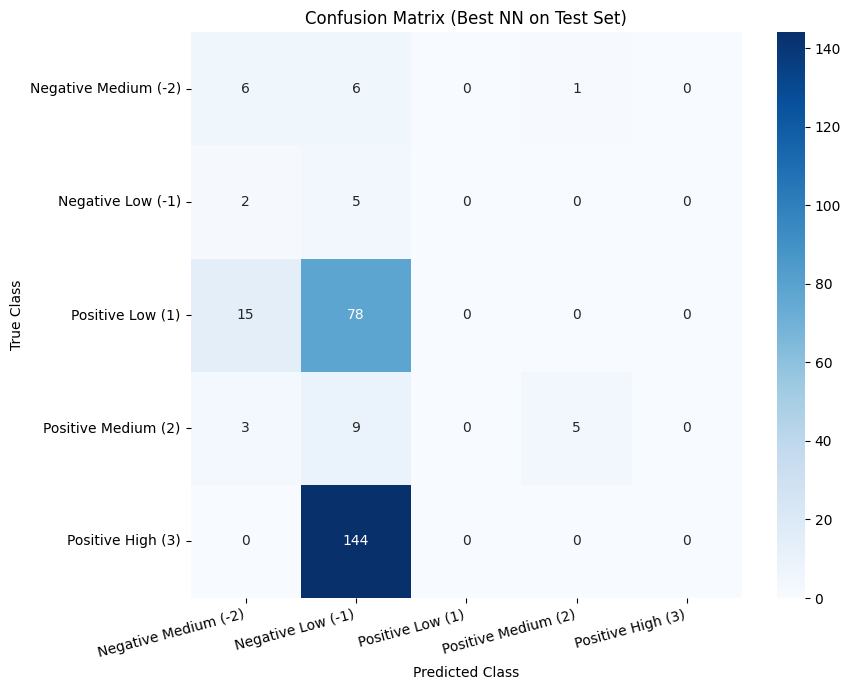

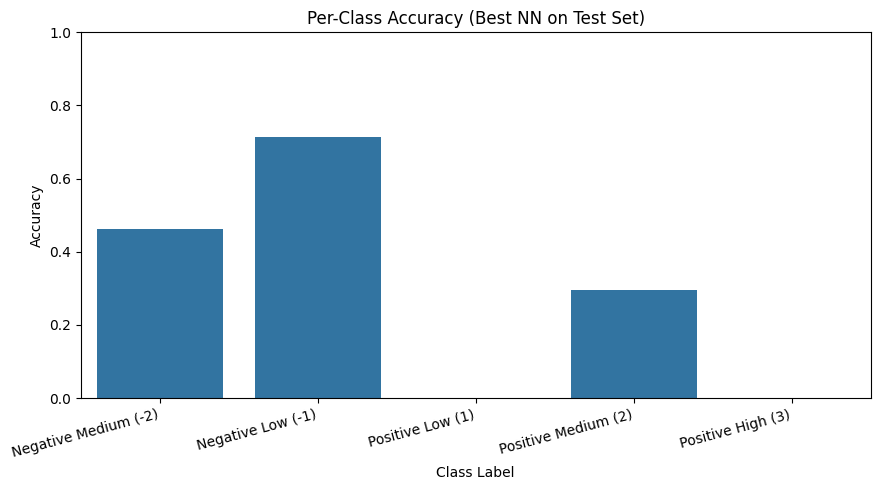

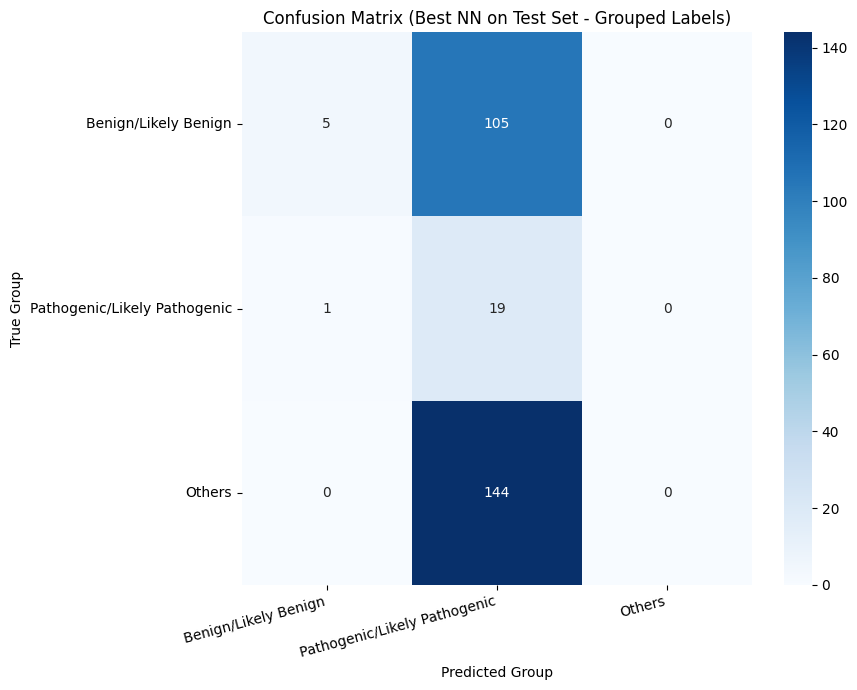

In [31]:
# Import necessary libraries for hyperparameter tuning and advanced techniques
from sklearn.model_selection import ParameterGrid
from torch.utils.data import WeightedRandomSampler
import torch.nn.functional as F
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

# --- Focal Loss Implementation ---
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        self.weight = weight

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight)
        pt = torch.exp(-ce_loss)
        
        if isinstance(self.alpha, torch.Tensor):
            alpha_t = self.alpha.gather(0, targets.data.view(-1)).to(inputs.device)
        elif isinstance(self.alpha, (float, int)):
            alpha_t = self.alpha
        else:
            raise TypeError("alpha must be a float or a Tensor")
        
        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

# --- Ensure X_nn and y_nn_original are properly set ---
# X_nn should already be loaded from the embeddings file.
# y_nn_original needs to be derived from df_processed if it doesn't exist or has wrong size.
if 'X_nn' not in locals() and 'X_nn' not in globals():
    raise NameError("X_nn is not defined. Please run the embedding loading cell first.")

if 'df_processed' not in locals() and 'df_processed' not in globals():
    raise NameError("df_processed is not defined. Please run the data preprocessing cells first.")

# Derive y_nn_original from df_processed to ensure it matches X_nn
if 'y_nn_original' not in locals() and 'y_nn_original' not in globals():
    print("y_nn_original not found. Deriving from df_processed['ContinuousLabel']...")
    y_nn_original = df_processed['ContinuousLabel'].values.astype(np.float64)
elif len(y_nn_original) != X_nn.shape[0]:
    print(f"y_nn_original has {len(y_nn_original)} samples but X_nn has {X_nn.shape[0]}. Re-deriving from df_processed...")
    y_nn_original = df_processed['ContinuousLabel'].values.astype(np.float64)

# Final verification
assert X_nn.shape[0] == len(y_nn_original), \
    f"FATAL: X_nn ({X_nn.shape[0]}) and y_nn_original ({len(y_nn_original)}) still don't match. " \
    f"df_processed has {len(df_processed)} rows. Check that df_processed matches the saved embeddings."

print(f"X_nn shape: {X_nn.shape}")
print(f"y_nn_original shape: {y_nn_original.shape}")
print(f"Label distribution: {dict(zip(*np.unique(y_nn_original, return_counts=True)))}")

if X_nn.shape[0] > 0:
    # --- 2. Prepare Data for PyTorch ---
    print("\nPreparing data for PyTorch...")
    
    # Filter out samples with label 0
    non_zero_indices = y_nn_original != 0
    X_nn_filtered = X_nn[non_zero_indices]
    y_nn_filtered = y_nn_original[non_zero_indices]
    
    if X_nn_filtered.shape[0] == 0:
        raise ValueError("No samples remaining after filtering out label 0. Cannot proceed.")
    
    print(f"Filtered out {len(X_nn) - len(X_nn_filtered)} samples with label 0.")
    print(f"Remaining samples: {len(X_nn_filtered)}")
    
    # Encode the labels (excluding 0)
    le = LabelEncoder()
    y_nn_encoded = le.fit_transform(y_nn_filtered)
    num_classes = len(le.classes_)
    
    # Define meaningful names for the classes
    class_names = {
        -3: 'Negative High (-3)',
        -2: 'Negative Medium (-2)',
        -1: 'Negative Low (-1)',
        1: 'Positive Low (1)',
        2: 'Positive Medium (2)',
        3: 'Positive High (3)'
    }
    target_names = [class_names.get(i, f'Class {i}') for i in le.classes_]
    
    print(f"Original labels encoded to {num_classes} classes.")
    print(f"Labels (encoded): {np.unique(y_nn_encoded)}")
    print("Class mapping (Encoded Value: Class Name):")
    for i, name in enumerate(target_names):
        print(f"  {i}: {name}")
    
    # Split data into training, validation, and testing sets
    X_train_val, X_test_nn, y_train_val, y_test_nn = train_test_split(
        X_nn_filtered, y_nn_encoded, test_size=0.15, random_state=42,
        stratify=y_nn_encoded if num_classes > 1 and len(y_nn_encoded) > num_classes else None
    )
    
    val_split_size = 0.1765
    if len(X_train_val) * val_split_size < 1 or len(np.unique(y_train_val)) < 2:
        print(f"Warning: Not enough samples or classes for stratified validation split. Using unstratified split.")
        X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
            X_train_val, y_train_val,
            test_size=min(val_split_size, 0.5 if len(X_train_val) > 1 else 0.0),
            random_state=42
        )
    else:
        X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
            X_train_val, y_train_val, test_size=val_split_size,
            random_state=42, stratify=y_train_val
        )
    
    print(f"\nData split: Train={X_train_nn.shape[0]}, Val={X_val_nn.shape[0]}, Test={X_test_nn.shape[0]}")
    
    # Convert NumPy arrays to PyTorch tensors
    X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train_nn, dtype=torch.long)
    X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32) if X_val_nn.shape[0] > 0 else torch.empty(0, X_train_nn.shape[1], dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val_nn, dtype=torch.long) if y_val_nn.shape[0] > 0 else torch.empty(0, dtype=torch.long)
    X_test_tensor = torch.tensor(X_test_nn, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test_nn, dtype=torch.long)
    
    # --- Address Class Imbalance with Weighted Sampling ---
    print("\nAddressing class imbalance...")
    if len(y_train_nn) > 0:
        class_counts_train = np.bincount(y_train_nn, minlength=num_classes)
        print(f"Training set class counts (encoded): {class_counts_train}")
        for i, count in enumerate(class_counts_train):
            if i < len(target_names):
                print(f"  Class {i} ({target_names[i]}): {count} samples")
        
        if np.any(class_counts_train == 0):
            print("Warning: Some classes have zero samples. Weighted sampling disabled.")
            use_weighted_sampler = False
            sampler = None
        else:
            class_weights_sample = 1. / torch.tensor(class_counts_train, dtype=torch.float32)
            sample_weights = class_weights_sample[y_train_nn]
            sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
            print("Using WeightedRandomSampler for training data.")
            use_weighted_sampler = True
    else:
        use_weighted_sampler = False
        sampler = None
        class_counts_train = np.zeros(num_classes, dtype=int)
    
    # Create TensorDatasets
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    
    # Create DataLoaders
    batch_size = 32
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size,
        sampler=sampler if use_weighted_sampler and len(train_dataset) > 0 else None,
        shuffle=not (use_weighted_sampler and len(train_dataset) > 0) and len(train_dataset) > 0
    )
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False) if len(val_dataset) > 0 else None
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    # --- 3. Define the Neural Network ---
    print("\nDefining the Neural Network...")
    
    class ResidualBlock(nn.Module):
        def __init__(self, in_dim, out_dim, dropout_rate):
            super(ResidualBlock, self).__init__()
            self.block = nn.Sequential(
                nn.Linear(in_dim, out_dim),
                nn.BatchNorm1d(out_dim),
                nn.ReLU(),
                nn.Dropout(dropout_rate),
                nn.Linear(out_dim, out_dim),
                nn.BatchNorm1d(out_dim),
            )
            self.shortcut = nn.Sequential()
            if in_dim != out_dim:
                self.shortcut = nn.Sequential(
                    nn.Linear(in_dim, out_dim),
                    nn.BatchNorm1d(out_dim)
                )
            self.final_relu = nn.ReLU()
            self.final_dropout = nn.Dropout(dropout_rate)
        
        def forward(self, x):
            out = self.block(x)
            shortcut_out = self.shortcut(x)
            out += shortcut_out
            out = self.final_relu(out)
            out = self.final_dropout(out)
            return out
    
    class DNABERTClassifier(nn.Module):
        def __init__(self, input_dim, hidden_dims=[512, 256, 128], output_dim=6, dropout_rate=0.4):
            super(DNABERTClassifier, self).__init__()
            if not hidden_dims:
                raise ValueError("hidden_dims list cannot be empty")
            
            self.input_layer = nn.Sequential(
                nn.Linear(input_dim, hidden_dims[0]),
                nn.BatchNorm1d(hidden_dims[0]),
                nn.ReLU(),
                nn.Dropout(dropout_rate)
            )
            self.hidden_layers = nn.ModuleList()
            current_dim = hidden_dims[0]
            if len(hidden_dims) > 1:
                for hidden_dim in hidden_dims[1:]:
                    self.hidden_layers.append(ResidualBlock(current_dim, hidden_dim, dropout_rate))
                    current_dim = hidden_dim
            self.output_layer = nn.Linear(current_dim, output_dim)
        
        def forward(self, x):
            out = self.input_layer(x)
            for layer in self.hidden_layers:
                out = layer(out)
            out = self.output_layer(out)
            return out
    
    # --- 4. Hyperparameter Setup ---
    param_grid = {
        'lr': [0.001],
        'weight_decay': [0.1],
        'dropout_rate': [0.3],
        'loss_fn': ['FocalLoss'],
        'hidden_dims': [[128]],
        'optimizer': ['AdamW']
    }
    
    grid = ParameterGrid(param_grid)
    best_val_acc = 0.0
    best_params = None
    best_model_state_grid = None
    results = []
    
    print(f"\nStarting Training (Grid Size: {len(grid)} combination)...")
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    input_dim = X_train_nn.shape[1]
    
    # --- Training Loop ---
    for i, params in enumerate(grid):
        print(f"\n--- Combination {i+1}/{len(grid)} ---")
        print(f"Parameters: {params}")
        
        current_dropout = params['dropout_rate']
        current_hidden_dims = params['hidden_dims']
        nn_model = DNABERTClassifier(input_dim, current_hidden_dims, num_classes, dropout_rate=current_dropout)
        nn_model.to(device)
        
        if len(y_train_nn) > 0 and np.any(class_counts_train == 0):
            class_weights_loss = None
            print("Warning: Cannot calculate class weights for loss due to missing classes.")
        elif len(y_train_nn) == 0:
            class_weights_loss = None
            print("Warning: Training set is empty. Cannot calculate class weights for loss.")
        else:
            class_weights_tensor = 1. / torch.tensor(class_counts_train.astype(np.float32) + 1e-9)
            class_weights_loss = class_weights_tensor.to(device)
            print(f"Calculated class weights for loss: {class_weights_loss.cpu().numpy()}")
        
        if params['loss_fn'] == 'FocalLoss':
            criterion = FocalLoss(alpha=class_weights_loss if class_weights_loss is not None else 1.0, gamma=2.0, reduction='mean')
            print("Using FocalLoss.")
        else:
            criterion = nn.CrossEntropyLoss(weight=class_weights_loss)
            print("Using CrossEntropyLoss.")
        
        optimizer_type = params.get('optimizer', 'AdamW')
        if optimizer_type == 'Adam':
            optimizer = optim.Adam(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        else:
            optimizer = optim.AdamW(nn_model.parameters(), lr=params['lr'], weight_decay=params['weight_decay'])
        print(f"Using Optimizer: {optimizer_type}")
        
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=15, verbose=False)
        
        num_epochs = 267
        train_losses_hist = []
        train_accuracies_hist = []
        val_accuracies_hist = []
        val_losses_hist = []
        current_best_val_acc = 0.0
        best_model_state_current = None
        patience_early_stopping = 200
        epochs_no_improve = 0
        
        print(f"Training with lr={params['lr']}, wd={params['weight_decay']}, dropout={current_dropout}...")
        
        if len(train_loader.dataset) == 0:
            print("Skipping training loop as training dataset is empty.")
        else:
            for epoch in range(num_epochs):
                nn_model.train()
                running_loss = 0.0
                correct_train = 0
                total_train = 0
                
                progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} Train", leave=False)
                for inputs, labels in progress_bar:
                    inputs, labels = inputs.to(device), labels.to(device)
                    optimizer.zero_grad()
                    outputs = nn_model(inputs)
                    loss = criterion(outputs, labels)
                    loss.backward()
                    optimizer.step()
                    
                    running_loss += loss.item() * inputs.size(0)
                    _, predicted = torch.max(outputs.data, 1)
                    total_train += labels.size(0)
                    correct_train += (predicted == labels).sum().item()
                    progress_bar.set_postfix({'loss': loss.item()})
                
                epoch_train_loss = running_loss / len(train_loader.dataset) if len(train_loader.dataset) > 0 else 0.0
                epoch_train_acc = correct_train / total_train if total_train > 0 else 0.0
                train_losses_hist.append(epoch_train_loss)
                train_accuracies_hist.append(epoch_train_acc)
                
                # Validation Step
                if val_loader is not None and len(val_loader.dataset) > 0:
                    nn_model.eval()
                    correct_val = 0
                    total_val = 0
                    running_val_loss = 0.0
                    with torch.no_grad():
                        for inputs_val, labels_val in val_loader:
                            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
                            outputs_val = nn_model(inputs_val)
                            loss_val = criterion(outputs_val, labels_val)
                            running_val_loss += loss_val.item() * inputs_val.size(0)
                            _, predicted_val = torch.max(outputs_val.data, 1)
                            total_val += labels_val.size(0)
                            correct_val += (predicted_val == labels_val).sum().item()
                    
                    epoch_val_loss = running_val_loss / len(val_loader.dataset) if len(val_loader.dataset) > 0 else 0.0
                    epoch_val_acc = correct_val / total_val if total_val > 0 else 0.0
                    val_losses_hist.append(epoch_val_loss)
                    val_accuracies_hist.append(epoch_val_acc)
                    
                    if (epoch + 1) % 10 == 0 or epoch == 0:
                        print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")
                    
                    scheduler.step(epoch_val_acc)
                    
                    if epoch_val_acc > current_best_val_acc:
                        current_best_val_acc = epoch_val_acc
                        epochs_no_improve = 0
                        best_model_state_current = nn_model.state_dict()
                    else:
                        epochs_no_improve += 1
                    
                    if epochs_no_improve >= patience_early_stopping and patience_early_stopping < num_epochs:
                        print(f"  Early stopping triggered after {epoch + 1} epochs.")
                        break
                else:
                    epoch_val_loss = float('nan')
                    epoch_val_acc = float('nan')
                    val_losses_hist.append(epoch_val_loss)
                    val_accuracies_hist.append(epoch_val_acc)
                    if (epoch + 1) % 10 == 0 or epoch == 0:
                        print(f"  Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
                              f"Val Loss: N/A, Val Acc: N/A (No validation data)")
                    if epoch_train_acc > current_best_val_acc:
                        current_best_val_acc = epoch_train_acc
                        best_model_state_current = nn_model.state_dict()
        
        print(f"Combination {i+1} finished. Best Val/Train Acc: {current_best_val_acc:.4f}")
        results.append({'params': params, 'best_val_acc': current_best_val_acc, 'epochs': epoch + 1 if 'epoch' in locals() else 0})
        
        if current_best_val_acc > best_val_acc:
            print(f"!!! Found new overall best accuracy: {current_best_val_acc:.4f} !!!")
            best_val_acc = current_best_val_acc
            best_params = params
            best_model_state_grid = best_model_state_current
    
    print("\n--- Training Complete ---")
    results.sort(key=lambda x: x['best_val_acc'], reverse=True)
    print("Training Results:")
    for res in results:
        print(f"  Params: {res['params']}, Val/Train Acc: {res['best_val_acc']:.4f}, Epochs: {res['epochs']}")
    
    if best_params is None:
        print("\nError: No best model found.")
    else:
        print(f"\nBest hyperparameters: {best_params}")
        print(f"Best accuracy achieved: {best_val_acc:.4f}")
        
        print("\nLoading the best model configuration...")
        best_dropout = best_params['dropout_rate']
        best_hidden_dims = best_params['hidden_dims']
        nn_model_best = DNABERTClassifier(input_dim, best_hidden_dims, num_classes, dropout_rate=best_dropout)
        if best_model_state_grid:
            nn_model_best.load_state_dict(best_model_state_grid)
            print("Loaded best model state from training.")
        else:
            print("Warning: Could not load best model state.")
        nn_model_best.to(device)
        
        print("\nSkipping training curve plots for simplicity.")
        
        # --- 6. Evaluate on Test Set ---
        if len(test_loader.dataset) > 0:
            print("\nEvaluating the Best Neural Network on the Test Set...")
            
            nn_model_best.eval()
            y_pred_list = []
            y_true_list = []
            test_probs_list = []
            
            with torch.no_grad():
                for inputs, labels in tqdm(test_loader, desc="Evaluating Best Model"):
                    inputs, labels = inputs.to(device), labels.to(device)
                    outputs = nn_model_best(inputs)
                    probabilities = torch.softmax(outputs, dim=1)
                    _, predicted = torch.max(outputs.data, 1)
                    
                    y_pred_list.extend(predicted.cpu().numpy())
                    y_true_list.extend(labels.cpu().numpy())
                    test_probs_list.extend(probabilities.cpu().numpy())
            
            y_pred_nn = np.array(y_pred_list)
            y_test_nn_eval = np.array(y_true_list)
            y_test_probs = np.array(test_probs_list)
            
            accuracy_nn = accuracy_score(y_test_nn_eval, y_pred_nn)
            print(f"\nTest Accuracy (Best NN): {accuracy_nn:.4f}")
            
            print("\nClassification Report (Best NN):")
            print(classification_report(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes), target_names=target_names, zero_division=0))
            
            print("\nConfusion Matrix (Best NN):")
            cm = confusion_matrix(y_test_nn_eval, y_pred_nn, labels=np.arange(num_classes))
            
            cm_sum_axis1 = cm.sum(axis=1)
            per_class_acc = np.divide(cm.diagonal(), cm_sum_axis1, out=np.zeros_like(cm.diagonal(), dtype=float), where=cm_sum_axis1!=0)
            
            print("\nPer-Class Accuracy (Best NN):")
            for i, class_name in enumerate(target_names):
                if i < len(per_class_acc):
                    if cm.sum(axis=1)[i] > 0:
                        print(f"  Class {class_name}: {per_class_acc[i]:.4f}")
                    else:
                        print(f"  Class {class_name}: N/A (no true samples)")
            
            # --- Group Evaluation ---
            print("\n--- Group Evaluation ---")
            original_class_indices = {val: idx for idx, val in enumerate(le.classes_)}
            group_mapping = {}
            for encoded_idx, original_class_val in enumerate(le.classes_):
                if original_class_val in [1, 2]:
                    group_mapping[encoded_idx] = 0
                elif original_class_val in [-1, -2]:
                    group_mapping[encoded_idx] = 1
                else:
                    group_mapping[encoded_idx] = 2
            
            y_true_grouped = np.array([group_mapping.get(label, 2) for label in y_test_nn_eval])
            y_pred_grouped = np.array([group_mapping.get(pred, 2) for pred in y_pred_nn])
            
            group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
            unique_groups_present = np.unique(np.concatenate((y_true_grouped, y_pred_grouped)))
            target_names_grouped = [group_names[g] for g in unique_groups_present if g < len(group_names)]
            
            if len(y_true_grouped) > 0:
                accuracy_grouped = accuracy_score(y_true_grouped, y_pred_grouped)
                print(f"\nGrouped Test Accuracy: {accuracy_grouped:.4f}")
                print("\nGrouped Classification Report:")
                print(classification_report(y_true_grouped, y_pred_grouped,
                                          labels=unique_groups_present,
                                          target_names=target_names_grouped,
                                          zero_division=0))
                
                cm_grouped = confusion_matrix(y_true_grouped, y_pred_grouped, labels=unique_groups_present)
                cm_grouped_sum_axis1 = cm_grouped.sum(axis=1)
                per_group_acc = np.divide(cm_grouped.diagonal(), cm_grouped_sum_axis1,
                                        out=np.zeros_like(cm_grouped.diagonal(), dtype=float),
                                        where=cm_grouped_sum_axis1!=0)
                
                print("\nPer-Group Accuracy:")
                for i, group_idx in enumerate(unique_groups_present):
                    group_name = group_names[group_idx] if group_idx < len(group_names) else f"Group {group_idx}"
                    if cm_grouped_sum_axis1[i] > 0:
                        print(f"  Group {group_name}: {per_group_acc[i]:.4f}")
                    else:
                        print(f"  Group {group_name}: N/A (no true samples)")
            
            try:
                import seaborn as sns
                plt.figure(figsize=(9, 7))
                sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                           xticklabels=target_names, yticklabels=target_names)
                plt.xlabel('Predicted Class')
                plt.ylabel('True Class')
                plt.title('Confusion Matrix (Best NN on Test Set)')
                plt.xticks(rotation=15, ha='right')
                plt.yticks(rotation=0)
                plt.tight_layout()
                plt.show()
                
                plt.figure(figsize=(9, 5))
                if len(target_names) == len(per_class_acc):
                    sns.barplot(x=target_names, y=per_class_acc)
                    plt.xlabel('Class Label')
                    plt.ylabel('Accuracy')
                    plt.title('Per-Class Accuracy (Best NN on Test Set)')
                    plt.ylim(0, 1)
                    plt.xticks(rotation=15, ha='right')
                    plt.tight_layout()
                    plt.show()
                
                if 'cm_grouped' in locals() and len(target_names_grouped) > 0:
                    plt.figure(figsize=(9, 7))
                    sns.heatmap(cm_grouped, annot=True, fmt='d', cmap='Blues',
                               xticklabels=target_names_grouped, yticklabels=target_names_grouped)
                    plt.xlabel('Predicted Group')
                    plt.ylabel('True Group')
                    plt.title('Confusion Matrix (Best NN on Test Set - Grouped Labels)')
                    plt.xticks(rotation=15, ha='right')
                    plt.yticks(rotation=0)
                    plt.tight_layout()
                    plt.show()
            except ImportError:
                print("Seaborn not installed. Skipping visualizations.")
                print(cm)
        else:
            print("\nTest set is empty. Skipping evaluation.")

else:
    print("\nNo embeddings were generated. Cannot proceed with training.")

### Esm-2 Only

Using ESM-2 embeddings with shape: (990, 2560)

Preparing data for PyTorch (Using only ESM-2 embeddings)...
Filtered out 268 samples with label 0.
Remaining samples: 722
Labels encoded into 5 classes.
Class mapping (Encoded Value: Original Label | Name):
  0: -2 | Neg Med (-2)
  1: -1 | Neg Low (-1)
  2: 1 | Pos Low (1)
  3: 2 | Pos Med (2)
  4: 3 | Pos High (3)

Splitting data...
Data split: Train=504, Val=109, Test=109

Scaling features (StandardScaler)...

Setting up sampling and class weights...
Training set class counts (encoded): [ 28  10  95  60 311]
Using WeightedRandomSampler. Calculated Loss Weights: [ 3.6        10.08        1.0610526   1.6800001   0.32411575]

Defining Simple Neural Network Architecture...

--- Using Best Hyperparameters ---
Best hyperparameters: {'dropout_rate': 0.3, 'hidden_dims': [512, 256, 128], 'loss_fn': 'CrossEntropyLoss', 'lr': 5e-05, 'model_type': 'Simple', 'optimizer': 'AdamW', 'weight_decay': 0.001}
Best validation accuracy from previous grid sea

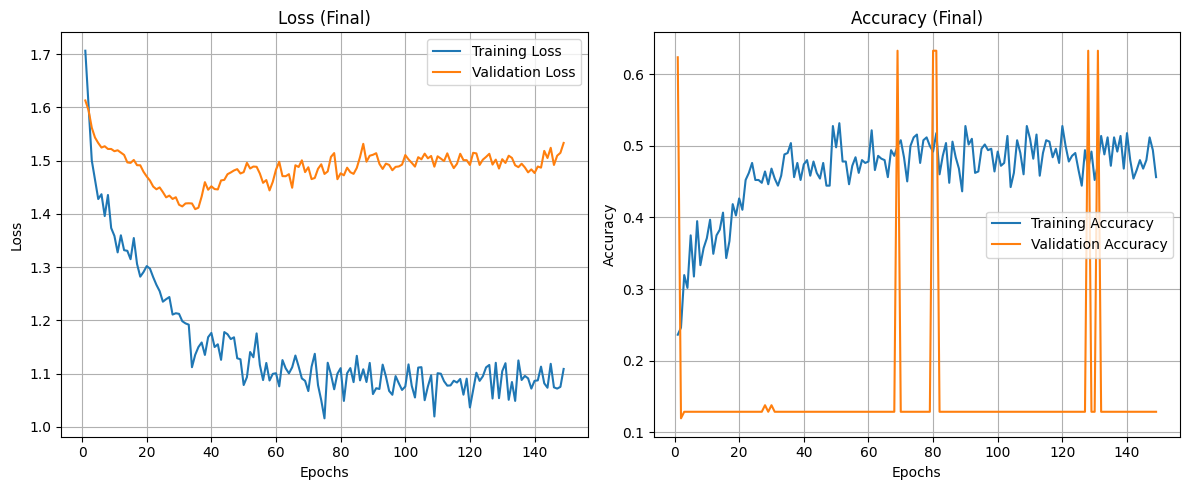


--- Evaluating Final Best Model on Test Set ---


Final Test Evaluation: 100%|██████████| 1/1 [00:00<00:00, 638.21it/s]


FINAL Test Accuracy: 0.6330
SUCCESS: Final test accuracy is above 50%!

FINAL Classification Report:
              precision    recall  f1-score   support

Neg Med (-2)       1.00      0.17      0.29         6
Neg Low (-1)       0.33      0.50      0.40         2
 Pos Low (1)       0.00      0.00      0.00        21
 Pos Med (2)       0.00      0.00      0.00        13
Pos High (3)       0.65      1.00      0.79        67

    accuracy                           0.63       109
   macro avg       0.40      0.33      0.29       109
weighted avg       0.46      0.63      0.51       109


FINAL Confusion Matrix:


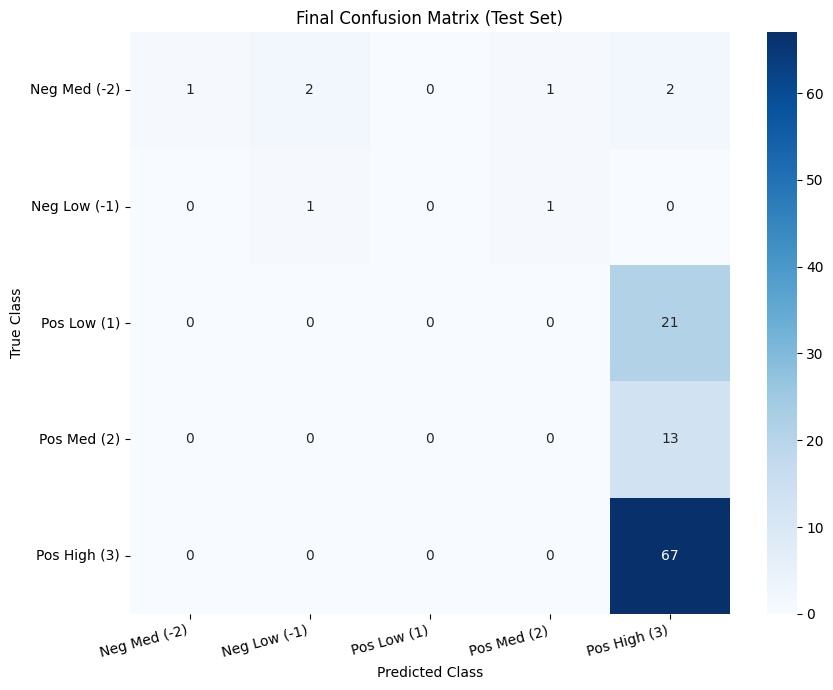


--- End of Training and Evaluation Script ---


In [30]:
# Cell for Refined Grid Search and Training (ESM-2 Embeddings Only)

# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler # Added StandardScaler
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import copy # To store best model state
import time # For timing

# --- Ensure necessary variables exist from previous cells ---
# Check if X_nn_esm2 (ESM2 embeddings) exist
if 'X_nn_esm2' not in locals():
    raise NameError("X_nn_esm2 not defined. Please run the ESM-2 embedding generation cell.")
# Check if labels exist
if 'y_nn_esm2' not in locals():
     raise NameError("Labels y_nn_esm2 not defined.")

# Check shape consistency
if X_nn_esm2.shape[0] != y_nn_esm2.shape[0]:
    raise ValueError(f"Mismatch in number of samples: ESM2 shape {X_nn_esm2.shape}, Labels shape {y_nn_esm2.shape}")

print(f"Using ESM-2 embeddings with shape: {X_nn_esm2.shape}")

# --- Prepare Data for PyTorch (ESM-2 Only) ---
# (Same data prep as before: Filter, Encode, Split, Scale)
print("\nPreparing data for PyTorch (Using only ESM-2 embeddings)...")
non_zero_indices = y_nn_esm2 != 0
X_filtered = X_nn_esm2[non_zero_indices]
y_filtered = y_nn_esm2[non_zero_indices]
print(f"Filtered out {len(y_nn_esm2) - len(y_filtered)} samples with label 0.")
print(f"Remaining samples: {len(y_filtered)}")
if len(y_filtered) == 0: raise ValueError("No samples remaining after filtering.")

le = LabelEncoder(); y_encoded = le.fit_transform(y_filtered); num_classes = len(le.classes_)
print(f"Labels encoded into {num_classes} classes.")
class_names = {-3: 'Neg High (-3)', -2: 'Neg Med (-2)', -1: 'Neg Low (-1)', 1: 'Pos Low (1)', 2: 'Pos Med (2)', 3: 'Pos High (3)'}
target_names = [class_names.get(i, f'Unknown({i})') for i in le.classes_]
print("Class mapping (Encoded Value: Original Label | Name):")
for i, orig_label in enumerate(le.classes_): print(f"  {i}: {orig_label} | {target_names[i]}")

print("\nSplitting data...")
X_train_val, X_test, y_train_val, y_test = train_test_split(X_filtered, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val)
print(f"Data split: Train={len(y_train)}, Val={len(y_val)}, Test={len(y_test)}")

print("\nScaling features (StandardScaler)...")
scaler = StandardScaler(); X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val); X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("\nSetting up sampling and class weights...")
class_counts_train = np.bincount(y_train, minlength=num_classes)
print(f"Training set class counts (encoded): {class_counts_train}")
if np.any(class_counts_train == 0):
    print("Warning: Zero samples for some classes in train set. Weighted sampling/loss disabled.")
    use_weighted_sampler = False; sampler = None; class_weights_loss = None
else:
    class_weights_sample = 1. / torch.tensor(class_counts_train, dtype=torch.float32)
    sample_weights = class_weights_sample[y_train]
    sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)
    use_weighted_sampler = True
    class_weights_loss = (len(y_train) / (num_classes * torch.tensor(class_counts_train, dtype=torch.float32)))
    print(f"Using WeightedRandomSampler. Calculated Loss Weights: {class_weights_loss.numpy()}")

batch_size = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler if use_weighted_sampler else None, shuffle=not use_weighted_sampler)
val_loader = DataLoader(val_dataset, batch_size=batch_size * 2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size * 2, shuffle=False)

# --- Define Simple Neural Network Architecture ---
print("\nDefining Simple Neural Network Architecture...")
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512, 256, 128], output_dim=6, dropout_rate=0.3):
        super(SimpleClassifier, self).__init__()
        layers = []
        current_dim = input_dim
        # Add layers dynamically based on hidden_dims list
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(current_dim, h_dim),
                nn.BatchNorm1d(h_dim), # BatchNorm helps stabilize
                nn.ReLU(),
                nn.Dropout(dropout_rate)
            ])
            current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim)) # Final output layer
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# --- Using Best Hyperparameters ---
print("\n--- Using Best Hyperparameters ---")
best_params = {
    'dropout_rate': 0.3, 
    'hidden_dims': [512, 256, 128], 
    'loss_fn': 'CrossEntropyLoss', 
    'lr': 5e-05, 
    'model_type': 'Simple', 
    'optimizer': 'AdamW', 
    'weight_decay': 0.001
}
print(f"Best hyperparameters: {best_params}")
print(f"Best validation accuracy from previous grid search: 0.6602")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
input_dim = X_train_tensor.shape[1] # Should be 2560 for ESM-2
print(f"Input dimension: {input_dim}")

# --- Training the Model with Best Parameters ---
print("\n--- Training Model with Best Parameters ---")
# Instantiate the model with best parameters
final_model = SimpleClassifier(
    input_dim=input_dim,
    hidden_dims=best_params['hidden_dims'],
    output_dim=num_classes,
    dropout_rate=best_params['dropout_rate']
)
final_model.to(device)

# Define Loss and Optimizer
final_ce_weights = class_weights_loss if not use_weighted_sampler and class_weights_loss is not None else None
final_criterion = nn.CrossEntropyLoss(weight=final_ce_weights.to(device) if final_ce_weights is not None else None)
final_optimizer = optim.AdamW(final_model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
print(f"Using Optimizer: {best_params['optimizer']}, LR: {best_params['lr']}, WD: {best_params['weight_decay']}")
final_scheduler = optim.lr_scheduler.ReduceLROnPlateau(final_optimizer, mode='max', factor=0.2, patience=30, verbose=True)

# --- Final Training Loop ---
final_num_epochs = 600 # Increased max epochs for final training
final_patience_early_stopping = 80 # Increased patience for final training
final_epochs_no_improve = 0
final_best_val_acc = 0.0
final_best_model_state = None
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
print(f"Starting final training for up to {final_num_epochs} epochs...")
start_time_final = time.time()

for epoch in range(final_num_epochs):
    # --- Training Epoch ---
    final_model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        final_optimizer.zero_grad()
        outputs = final_model(inputs)
        loss = final_criterion(outputs, labels)
        loss.backward()
        final_optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    epoch_train_loss = running_loss / len(train_loader.dataset) if len(train_loader.dataset) > 0 else 0.0
    epoch_train_acc = correct_train / total_train if total_train > 0 else 0.0
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)

    # --- Validation Epoch ---
    final_model.eval()
    correct_val = 0
    total_val = 0
    running_val_loss = 0.0
    
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
            outputs_val = final_model(inputs_val)
            loss_val = final_criterion(outputs_val, labels_val)
            running_val_loss += loss_val.item() * inputs_val.size(0)
            _, predicted_val = torch.max(outputs_val.data, 1)
            total_val += labels_val.size(0)
            correct_val += (predicted_val == labels_val).sum().item()
    
    epoch_val_loss = running_val_loss / len(val_loader.dataset) if len(val_loader.dataset) > 0 else 0.0
    epoch_val_acc = correct_val / total_val if total_val > 0 else 0.0
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)

    print(f"  Epoch {epoch+1}/{final_num_epochs} - Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")
    final_scheduler.step(epoch_val_acc)

    # --- Early Stopping ---
    if epoch_val_acc > final_best_val_acc:
        print(f"  -> Validation accuracy improved ({final_best_val_acc:.4f} --> {epoch_val_acc:.4f}). Saving model...")
        final_best_val_acc = epoch_val_acc
        final_epochs_no_improve = 0
        final_best_model_state = copy.deepcopy(final_model.state_dict())
    else:
        final_epochs_no_improve += 1
    
    if final_epochs_no_improve >= final_patience_early_stopping:
        print(f"  Early stopping triggered after {epoch + 1} epochs.")
        break

end_time_final = time.time()
print(f"\n--- Final Training Complete ---")
print(f"Time taken: {(end_time_final - start_time_final)/60:.2f} minutes")
print(f"Best validation accuracy during final training: {final_best_val_acc:.4f}")

if final_best_model_state:
    print("Loading best model state from final training run...")
    final_model.load_state_dict(final_best_model_state)
else:
    print("Warning: No improvement? Using model state from last epoch.")

# --- Plot Final Curves ---
print("\nPlotting final training curves...")
epochs_ran = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history['train_loss'], label='Training Loss')
plt.plot(epochs_ran, history['val_loss'], label='Validation Loss')
plt.title('Loss (Final)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history['train_acc'], label='Training Accuracy')
plt.plot(epochs_ran, history['val_acc'], label='Validation Accuracy')
plt.title('Accuracy (Final)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Final Evaluation on Test Set ---
print("\n--- Evaluating Final Best Model on Test Set ---")
final_model.eval()
y_pred_list = []
y_true_list = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Final Test Evaluation"):
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = final_model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        y_pred_list.extend(predicted.cpu().numpy())
        y_true_list.extend(labels.cpu().numpy())

y_pred_final = np.array(y_pred_list)
y_test_final = np.array(y_true_list)
accuracy_final = accuracy_score(y_test_final, y_pred_final)
print(f"\nFINAL Test Accuracy: {accuracy_final:.4f}")

if accuracy_final > 0.50:
    print("SUCCESS: Final test accuracy is above 50%!")
else:
    print("NOTE: Final test accuracy did not exceed 50%.")

print("\nFINAL Classification Report:")
eval_labels = np.arange(num_classes)
eval_target_names = target_names
print(classification_report(y_test_final, y_pred_final, labels=eval_labels, target_names=eval_target_names, zero_division=0))

print("\nFINAL Confusion Matrix:")
cm_final = confusion_matrix(y_test_final, y_pred_final, labels=eval_labels)
try:
    import seaborn as sns
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', xticklabels=eval_target_names, yticklabels=eval_target_names)
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.title('Final Confusion Matrix (Test Set)')
    plt.xticks(rotation=15, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Seaborn not installed.")
    print(cm_final)

print("\n--- End of Training and Evaluation Script ---")


--- Evaluating Final Best Model on Test Set (for Grouping) ---


Getting Test Predictions: 100%|██████████| 1/1 [00:00<00:00, 184.66it/s]


--- Group Evaluation (Benign/Pathogenic/Others) ---

Grouped Test Accuracy: 0.6514

Grouped Classification Report:
                              precision    recall  f1-score   support

        Benign/Likely Benign       0.00      0.00      0.00        34
Pathogenic/Likely Pathogenic       1.00      0.50      0.67         8
                      Others       0.65      1.00      0.79        67

                    accuracy                           0.65       109
                   macro avg       0.55      0.50      0.48       109
                weighted avg       0.47      0.65      0.53       109


Per-Group Accuracy:
  Group Benign/Likely Benign (Idx 0): 0.0000
  Group Pathogenic/Likely Pathogenic (Idx 1): 0.5000
  Group Others (Idx 2): 1.0000


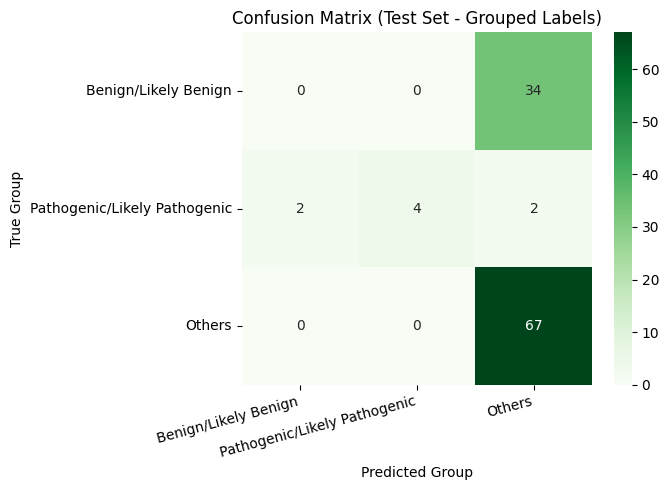


--- Grouped Evaluation Complete ---


In [31]:
# Cell for Grouped Evaluation of the Best Model

import torch
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd

# --- Ensure required variables and libraries exist ---
required_vars_eval = ['final_model', 'test_loader', 'device', 'le', 'target_names', 'num_classes']
for var in required_vars_eval:
    if var not in locals():
        raise NameError(f"Variable '{var}' not found. Please ensure the previous training cell was run successfully.")

try:
    import seaborn as sns
    seaborn_available = True
except ImportError:
    print("Seaborn not installed. Confusion matrix heatmap will not be plotted.")
    seaborn_available = False

# --- Get Predictions from the Final Model ---
print("\n--- Evaluating Final Best Model on Test Set (for Grouping) ---")
final_model.eval() # Set model to evaluation mode
y_pred_list = []
y_true_list = []
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Getting Test Predictions"):
        # Move data to device
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = final_model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        y_pred_list.extend(predicted.cpu().numpy())
        y_true_list.extend(labels.cpu().numpy())

y_pred_final = np.array(y_pred_list)
y_test_final = np.array(y_true_list) # These are the encoded test labels

# --- Group Evaluation Logic ---
print("\n--- Group Evaluation (Benign/Pathogenic/Others) ---")
try:
    # Define the grouping mapping based on the LabelEncoder's learned classes
    # Group 0: Benign or Likely Benign (original classes 1 and 2)
    # Group 1: Pathogenic or Likely Pathogenic (original classes -1 and -2)
    # Group 2: Others (original classes -3, 3, etc.)
    group_mapping = {}
    benign_labels = {1, 2}
    pathogenic_labels = {-1, -2}

    for encoded_idx, original_class in enumerate(le.classes_):
        if original_class in benign_labels:
            group_mapping[encoded_idx] = 0 # Group 0
        elif original_class in pathogenic_labels:
            group_mapping[encoded_idx] = 1 # Group 1
        else:
            group_mapping[encoded_idx] = 2 # Group 2

    group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']

    # Map predictions and true labels to groups
    y_true_grouped = np.array([group_mapping[label] for label in y_test_final])
    y_pred_grouped = np.array([group_mapping[pred] for pred in y_pred_final])

    # Filter to only include groups that exist in the data AND have defined names
    unique_groups = sorted(list(set(y_true_grouped) | set(y_pred_grouped))) # Get all unique group indices present
    target_names_grouped = [group_names[g] for g in unique_groups if g < len(group_names)]

    # Adjust labels if only a subset of groups (0, 1, 2) is present
    if len(target_names_grouped) != len(unique_groups):
         print("Warning: Some predicted/true groups are outside the defined group_names indices. Filtering results.")
         # Filter out data points belonging to undefined groups if necessary (or adjust mapping)
         # For simplicity here, we'll proceed but the report/CM might look odd if group '2' exists but has no name.
         valid_indices = [i for i, g in enumerate(unique_groups) if g < len(group_names)]
         unique_groups = [unique_groups[i] for i in valid_indices]


    # Calculate metrics for grouped evaluation
    accuracy_grouped = accuracy_score(y_true_grouped, y_pred_grouped)
    print(f"\nGrouped Test Accuracy: {accuracy_grouped:.4f}")

    print("\nGrouped Classification Report:")
    # Ensure labels used match the target names provided
    print(classification_report(y_true_grouped, y_pred_grouped,
                                labels=unique_groups,
                                target_names=target_names_grouped,
                                zero_division=0))

    # Confusion matrix for grouped evaluation
    cm_grouped = confusion_matrix(y_true_grouped, y_pred_grouped, labels=unique_groups)

    # Calculate per-group accuracy
    cm_grouped_sum_axis1 = cm_grouped.sum(axis=1)
    per_group_acc = np.divide(cm_grouped.diagonal(), cm_grouped_sum_axis1,
                              out=np.zeros_like(cm_grouped.diagonal(), dtype=float),
                              where=cm_grouped_sum_axis1!=0)

    print("\nPer-Group Accuracy:")
    for i, group_name in enumerate(target_names_grouped):
         true_group_idx = unique_groups[i] # Get the actual group index
         if cm_grouped_sum_axis1[i] > 0:
             print(f"  Group {group_name} (Idx {true_group_idx}): {per_group_acc[i]:.4f}")
         else:
             print(f"  Group {group_name} (Idx {true_group_idx}): N/A (no true samples in test set)")

    # Display grouped confusion matrix with labels using seaborn
    if seaborn_available:
        plt.figure(figsize=(7, 5)) # Adjusted size
        sns.heatmap(cm_grouped, annot=True, fmt='d', cmap='Greens', # Changed color map
                    xticklabels=target_names_grouped, yticklabels=target_names_grouped)
        plt.xlabel('Predicted Group')
        plt.ylabel('True Group')
        plt.title('Confusion Matrix (Test Set - Grouped Labels)')
        plt.xticks(rotation=15, ha='right') # Improve label readability
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()
    else:
        print("\nGrouped Confusion Matrix (row=True, col=Predicted):")
        try:
             print(pd.DataFrame(cm_grouped, index=target_names_grouped, columns=target_names_grouped))
        except NameError: # If pandas wasn't imported
             print(cm_grouped)

except NameError as e:
    print(f"Skipping grouped evaluation due to NameError: {e}. Was 'le' (LabelEncoder) defined?")
except KeyError as e:
     print(f"Skipping grouped evaluation due to KeyError: {e}. Check if all predicted/true labels exist in group_mapping.")
except Exception as e:
     print(f"Error during grouped evaluation: {e}")

print("\n--- Grouped Evaluation Complete ---")

### Combined

#### GRID SEARCH

Fused data shape: (2333, 6471)

Preparing data for PyTorch...
Filtered out 507 samples with label 0. Remaining: 1826
Labels encoded into 5 classes.
Data split: Train=1278, Val=274, Test=274

Scaling features SEPARATELY...
Scaled & Fused Input dim: 6471

Calculating class counts...
Training set class counts (encoded): [ 59  34 432  79 674]

Defining Simple Neural Network Architecture...

--- Setting up Grid Search for FUSED Embeddings ---
Filtering parameter grid...
Initial grid size: 192
Filtered grid size: 192 combinations
Using device: cuda
Fused Input dimension: 6471

--- Grid Search Combination 1/192 ---
Parameters: {'activation_fn': 'ReLU', 'batch_size': 64, 'cb_beta': 0.999, 'dropout_rate': 0.3, 'hidden_dims': [2048, 1024, 512], 'imbalance_strategy': 'WeightedSampler', 'label_smoothing': 0.0, 'lr': 0.0005, 'model_type': 'Simple', 'optimizer': 'AdamW', 'weight_decay': 0.01}
 E1 - TrL:1.310, Vl L:1.204, Vl A:0.4088
 E50 - TrL:0.248, Vl L:0.314, Vl A:0.9015
 E100 - TrL:0.125, Vl L:0

 Ep 1 - TrL:0.5406, TrA:0.9476 | VlL:0.5981, VlA:0.9088


 Ep 2 - TrL:0.5206, TrA:0.9491 | VlL:0.5847, VlA:0.9197


 Ep 3 - TrL:0.5057, TrA:0.9609 | VlL:0.5877, VlA:0.9161


 Ep 4 - TrL:0.5039, TrA:0.9577 | VlL:0.6082, VlA:0.8942


...

 Ep 76 - TrL:0.4518, TrA:0.9781 | VlL:0.5819, VlA:0.9124


 Ep 77 - TrL:0.4476, TrA:0.9789 | VlL:0.5809, VlA:0.9234


 Ep 78 - TrL:0.4477, TrA:0.9844 | VlL:0.5758, VlA:0.9234


 Ep 79 - TrL:0.4670, TrA:0.9710 | VlL:0.5757, VlA:0.9234


 Ep 80 - TrL:0.4529, TrA:0.9789 | VlL:0.5724, VlA:0.9161
  Early stopping @ epoch 80

--- Final Training Complete ---
Time: 0.14 min
Loading best model state from RETRAINING (Val Acc: 0.9343)...

Plotting final training curves...


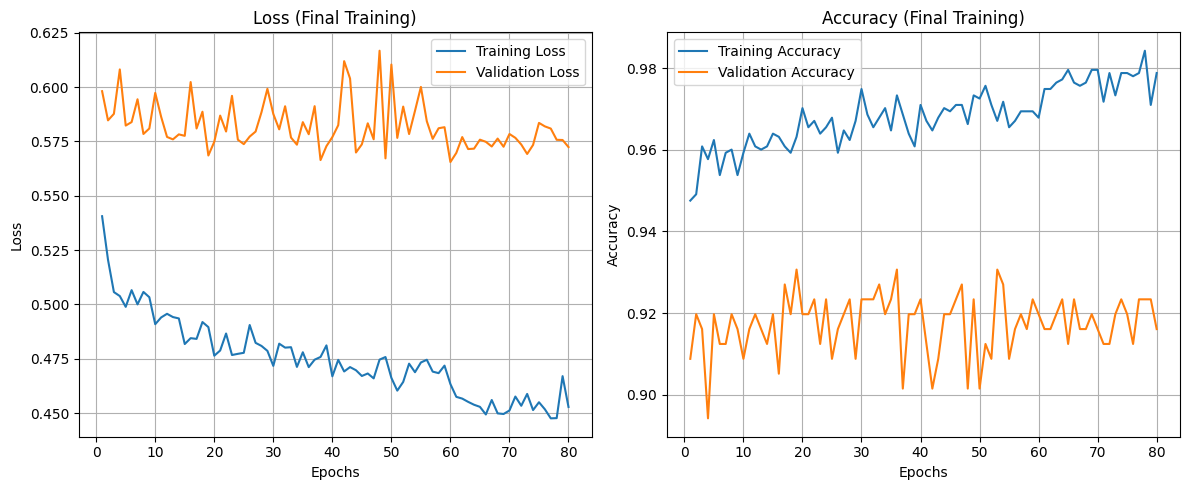


--- Evaluating Final Best Model on Test Set ---


Final Test Evaluation: 100%|██████████| 2/2 [00:00<00:00, 129.07it/s]



FINAL Test Accuracy: 0.9380
SUCCESS: Final test accuracy is above 50%!

FINAL Classification Report (Individual Classes):


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:465                                                                                  │
│                                                                                                  │
│   462 if accuracy_final > 0.50: print("SUCCESS: Final test accuracy is above 50%!")              │
│   463 else: print("NOTE: Final test accuracy did not exceed 50%.")                               │
│   464 print("\nFINAL Classification Report (Individual Classes):")                               │
│ ❱ 465 eval_labels = np.arange(num_classes); eval_target_names = target_names                     │
│   466 print(classification_report(y_test_final, y_pred_final, labels=eval_labels, target_names   │
│   467 print("\nFINAL Confusion Matrix (Individual Classes):")                                    │
│   468 cm_final = confusion_matrix(y_test_final, y_pred_final, labels=eval_labels)                │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
NameError: name 'target_names' is not defined

In [173]:
# Cell for Grid Search and Training (Fused DNA-BERT + ESM-2 Embeddings)

# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import copy
import time
import gc # Garbage collector

required_vars = ['X_nn', 'X_nn_esm2', 'y_nn_esm2', 'x_3']
for var in required_vars:
    if var not in locals():
        raise NameError(f"Variable '{var}' not defined. Please ensure base embeddings are loaded.")

if not isinstance(y_nn_esm2, np.ndarray):
    print("Warning: y_nn_esm2 is not a numpy array. Attempting to convert.")
    try:
        y_nn_esm2 = np.array(y_nn_esm2)
    except Exception as e:
        raise TypeError(f"Could not convert y_nn_esm2 to numpy array: {e}")

if X_nn.shape[0] != X_nn_esm2.shape[0] or X_nn.shape[0] != y_nn_esm2.shape[0] or X_nn.shape[0] != x_3.shape[0]:
    raise ValueError("Mismatch in number of samples between DNA, ESM2, x_3, and labels.")

dna_embedding_dim = X_nn.shape[1]
esm2_embedding_dim = X_nn_esm2.shape[1]
x3_dim = x_3.shape[1]
# fused_input_dim calculated later

# --- Fuse Embeddings ---
X_nn_np = X_nn if isinstance(X_nn, np.ndarray) else X_nn.numpy()
X_nn_esm2_np = X_nn_esm2 if isinstance(X_nn_esm2, np.ndarray) else X_nn_esm2.numpy()
x_3_np = x_3 if isinstance(x_3, np.ndarray) else x_3.numpy()

X_fused = np.concatenate((X_nn_np, X_nn_esm2_np, x_3_np), axis=1)
print(f"Fused data shape: {X_fused.shape}")

# --- Prepare Data ---
print("\nPreparing data for PyTorch...")
non_zero_indices = y_nn_esm2 != 0
X_filtered = X_fused[non_zero_indices]
y_filtered = y_nn_esm2[non_zero_indices]
print(f"Filtered out {len(y_nn_esm2) - len(y_filtered)} samples with label 0. Remaining: {len(y_filtered)}")
if len(y_filtered) == 0: raise ValueError("No samples remaining after filtering.")

le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)
num_classes = len(le.classes_)
print(f"Labels encoded into {num_classes} classes.")
class_names_map = {-3: 'Neg High (-3)', -2: 'Neg Med (-2)', -1: 'Neg Low (-1)', 1: 'Pos Low (1)', 2: 'Pos Med (2)', 3: 'Pos High (3)'}
target_names_display = [class_names_map.get(i, f'Unknown({i})') for i in le.classes_]

X_train_val, X_test, y_train_val, y_test = train_test_split(X_filtered, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val)
print(f"Data split: Train={len(y_train)}, Val={len(y_val)}, Test={len(y_test)}")

print("\nScaling features SEPARATELY...")
scaler_dna = StandardScaler().fit(X_train[:, :dna_embedding_dim])
scaler_esm2 = StandardScaler().fit(X_train[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim])
scaler_x3 = StandardScaler().fit(X_train[:, dna_embedding_dim+esm2_embedding_dim:])

X_train_fused_scaled = np.concatenate((
    scaler_dna.transform(X_train[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_train[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_train[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
X_val_fused_scaled = np.concatenate((
    scaler_dna.transform(X_val[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_val[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_val[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
X_test_fused_scaled = np.concatenate((
    scaler_dna.transform(X_test[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_test[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_test[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
fused_input_dim = X_train_fused_scaled.shape[1]
print(f"Scaled & Fused Input dim: {fused_input_dim}")

X_train_tensor = torch.tensor(X_train_fused_scaled, dtype=torch.float32); y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_fused_scaled, dtype=torch.float32); y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_fused_scaled, dtype=torch.float32); y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("\nCalculating class counts...")
class_counts_train = np.bincount(y_train, minlength=num_classes)
print(f"Training set class counts (encoded): {class_counts_train}")
use_sampler_or_weighted_loss = not np.any(class_counts_train == 0)
if not use_sampler_or_weighted_loss:
    print("Warning: Zero samples for some classes. Weighted strategies might not be effective or error out.")

# === NEW: define weighting variables used later ===
use_weights = True  # enable class weighting strategies

eps = 1e-6
class_freq = class_counts_train.astype(np.float32)

# For CrossEntropy weighted loss: inverse-frequency class weights, normalized
loss_weights_base = torch.tensor(1.0 / (class_freq + eps), dtype=torch.float32)
loss_weights_base = loss_weights_base / loss_weights_base.sum() * len(class_freq)

# For WeightedRandomSampler: per-sample weights (inverse of class frequency for each sample)
sampler_weights_base = torch.tensor(1.0 / (class_freq[y_train] + eps), dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


# Loss Function Implementations (CB Loss, Focal Loss) - Keep as defined previously
class ClassBalancedLoss(nn.Module):
    # ... (keep implementation from previous script) ...
    def __init__(self, loss_type, samples_per_cls, beta=0.999, gamma=2.0):
        super(ClassBalancedLoss, self).__init__();
        if isinstance(samples_per_cls, np.ndarray): samples_per_cls = torch.from_numpy(samples_per_cls)
        self.samples_per_cls = samples_per_cls.float(); self.beta = beta; self.gamma = gamma
        self.num_classes = len(samples_per_cls)
        effective_num = 1.0 - torch.pow(self.beta, self.samples_per_cls)
        weights = (1.0 - self.beta) / (effective_num + 1e-8)
        self.register_buffer('cb_weights', weights / weights.sum() * self.num_classes)
        # print(f"CB Loss Init Weights (CPU): {self.cb_weights.numpy()}") # Verbose
        if loss_type == 'CrossEntropy': self.base_loss = nn.CrossEntropyLoss(weight=None, reduction='none')
        elif loss_type == 'Focal': self.base_loss = FocalLoss(alpha=1.0, gamma=self.gamma, reduction='none')
        else: raise ValueError(f"Unsupported loss_type: {loss_type}")
        self.reduction = 'mean'
    def forward(self, inputs, targets):
        cb_weights_dev = self.cb_weights.to(inputs.device)
        if isinstance(self.base_loss, nn.CrossEntropyLoss): self.base_loss.weight = cb_weights_dev
        elif isinstance(self.base_loss, FocalLoss): self.base_loss.alpha = cb_weights_dev
        per_sample_loss = self.base_loss(inputs, targets)
        if self.reduction == 'mean': return per_sample_loss.mean()
        elif self.reduction == 'sum': return per_sample_loss.sum()
        else: return per_sample_loss

class FocalLoss(nn.Module):
    # ... (keep implementation from previous script) ...
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__(); self.gamma = gamma; self.reduction = reduction
        self.alpha = alpha if alpha is not None else 1.0; self.weight = weight
    def forward(self, inputs, targets):
        current_device = inputs.device; current_ce_weight = self.weight
        if isinstance(current_ce_weight, torch.Tensor): current_ce_weight = current_ce_weight.to(current_device)
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=current_ce_weight)
        pt = torch.exp(-ce_loss); alpha_t = self.alpha
        if isinstance(alpha_t, torch.Tensor): alpha_t = alpha_t.to(current_device).gather(0, targets.data.view(-1))
        elif not isinstance(alpha_t, (float, int)): alpha_t = 1.0
        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss
        if self.reduction == 'mean': return focal_loss.mean()
        elif self.reduction == 'sum': return focal_loss.sum()
        else: return focal_loss

# --- Define Simple MLP Architecture ---
print("\nDefining Simple Neural Network Architecture...")
class SimpleClassifier(nn.Module):
    # ... (keep implementation from previous script) ...
    def __init__(self, input_dim, hidden_dims=[512, 256], output_dim=6, dropout_rate=0.4, activation_fn=nn.ReLU):
        super(SimpleClassifier, self).__init__(); layers = []; current_dim = input_dim
        for h_dim in hidden_dims: layers.extend([nn.Linear(current_dim, h_dim), nn.BatchNorm1d(h_dim), activation_fn(), nn.Dropout(dropout_rate)]); current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim)); self.network = nn.Sequential(*layers)
    def forward(self, x): return self.network(x)

# --- Grid Search Setup for FUSED Data ---
print("\n--- Setting up Grid Search for FUSED Embeddings ---")
param_grid = {
    'model_type': ['Simple'],
    'lr': [5e-4, 5e-5],
    'weight_decay': [0.01, 0.0],
    'dropout_rate': [0.3], # Reduced options slightly
    'optimizer': ['AdamW', 'RMSprop'], # Focused based on last search
    'batch_size': [64],
    'activation_fn': ['ReLU', 'LeakyReLU'], # Focused based on last search
    # Adjusted hidden dims for larger input size
    'hidden_dims': [[2048, 1024, 512], [4096, 2048, 1024, 512]],
    # Focused imbalance strategies
    'imbalance_strategy': ['WeightedSampler', 'WeightedLossCE', 'ClassBalancedCE'],
    'cb_beta': [0.999,], # Only for ClassBalancedCE
    'label_smoothing': [0.0, 0.1] # Only for CE strategies
}

# Filter grid
print("Filtering parameter grid...")
filtered_grid = []; count = 0; original_grid = ParameterGrid(param_grid); total_combinations = len(original_grid)
print(f"Initial grid size: {total_combinations}")
for params in original_grid:
    count += 1; valid_combo = True
    if "ClassBalanced" not in params['imbalance_strategy'] and params['cb_beta'] != param_grid['cb_beta'][0]: valid_combo = False
    if "CE" not in params['imbalance_strategy'] and "WeightedSampler" != params['imbalance_strategy'] and params['label_smoothing'] != param_grid['label_smoothing'][0]: valid_combo = False
    if valid_combo: filtered_grid.append(params)
print(f"Filtered grid size: {len(filtered_grid)} combinations")

# Grid search parameters
grid_search_epochs = 150
grid_search_patience = 35 # Slightly more patience

# Tracking variables
best_overall_val_acc = 0.0; best_overall_params = None
best_overall_model_state = None; best_overall_optimizer_state = None # ADDED
grid_results = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print(f"Using device: {device}")
input_dim = X_train_tensor.shape[1]; print(f"Fused Input dimension: {input_dim}") # Should be larger now

# --- Grid Search Loop for FUSED Data ---
start_time_grid = time.time()
for i, params in enumerate(filtered_grid):
    print(f"\n--- Grid Search Combination {i+1}/{len(filtered_grid)} ---")
    print(f"Parameters: {params}")
    gc.collect(); torch.cuda.empty_cache() if device == 'cuda' else None

    try:
        # Setup Dataloaders
        current_batch_size = params['batch_size']; current_imbalance_strategy = params['imbalance_strategy']
        current_sampler = None; use_sampler_flag = False
        if current_imbalance_strategy == 'WeightedSampler':
            if sampler_weights_base is not None:
                sample_weights = sampler_weights_base[y_train]
                current_sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True); use_sampler_flag = True
        current_train_loader = DataLoader(train_dataset, batch_size=current_batch_size, sampler=current_sampler, shuffle=not use_sampler_flag, num_workers=0)
        current_val_loader = DataLoader(val_dataset, batch_size=current_batch_size * 2, shuffle=False, num_workers=0)

        # Activation
        activation = nn.LeakyReLU if params['activation_fn'] == 'LeakyReLU' else nn.ReLU

        # Model
        nn_model = SimpleClassifier(input_dim, params['hidden_dims'], num_classes, params['dropout_rate'], activation)
        nn_model.to(device)

        # Loss
        loss_weights = None
        if current_imbalance_strategy == 'WeightedLossCE' or current_imbalance_strategy == 'ClassBalancedCE':
            if loss_weights_base is not None: loss_weights = loss_weights_base.to(device)

        if current_imbalance_strategy == 'ClassBalancedCE':
             if use_weights: final_criterion = ClassBalancedLoss(loss_type='CrossEntropy', samples_per_cls=class_counts_train, beta=params['cb_beta']).to(device)
             else: final_criterion = nn.CrossEntropyLoss() # Fallback
        else: # WeightedSampler or WeightedLossCE use CrossEntropy
             ls_eps = params.get('label_smoothing', 0.0)
             ce_weight_param = loss_weights if current_imbalance_strategy == 'WeightedLossCE' else None
             final_criterion = nn.CrossEntropyLoss(weight=ce_weight_param, label_smoothing=ls_eps)

        # Optimizer
        optimizer_type = params['optimizer']; lr=params['lr']; wd=params['weight_decay']
        if optimizer_type == 'Adam': optimizer = optim.Adam(nn_model.parameters(), lr=lr, weight_decay=wd)
        elif optimizer_type == 'RMSprop': optimizer = optim.RMSprop(nn_model.parameters(), lr=lr, weight_decay=wd)
        else: optimizer = optim.AdamW(nn_model.parameters(), lr=lr, weight_decay=wd)

        # Scheduler
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=15, verbose=False)

        # Training Loop
        current_best_val_acc = 0.0; best_model_state_current = None; best_optimizer_state_current = None; epochs_no_improve = 0
        for epoch in range(grid_search_epochs):
            nn_model.train(); running_loss = 0.0; total_train=0
            for inputs, labels in current_train_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad(); outputs = nn_model(inputs); loss = final_criterion(outputs, labels)
                if torch.isnan(loss) or torch.isinf(loss): print(f"NaN/Inf loss"); current_best_val_acc = -1; break
                loss.backward(); optimizer.step(); running_loss += loss.item() * inputs.size(0); total_train += inputs.size(0)
            if current_best_val_acc == -1: break
            epoch_train_loss = running_loss / total_train if total_train > 0 else 0

            nn_model.eval(); correct_val = 0; total_val = 0; running_val_loss = 0.0; epoch_val_acc = 0.0
            with torch.no_grad():
                for inputs_val, labels_val in current_val_loader:
                    inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
                    outputs_val = nn_model(inputs_val); loss_val = final_criterion(outputs_val, labels_val)
                    if torch.isnan(loss_val) or torch.isinf(loss_val): epoch_val_acc = -1; break
                    running_val_loss += loss_val.item() * inputs_val.size(0)
                    _, predicted_val = torch.max(outputs_val.data, 1); total_val += labels_val.size(0); correct_val += (predicted_val == labels_val).sum().item()
                if epoch_val_acc == -1: current_best_val_acc = -1; break
                epoch_val_loss = running_val_loss / total_val if total_val > 0 else 0
                epoch_val_acc = correct_val / total_val if total_val > 0 else 0

            if (epoch + 1) % 50 == 0 or epoch == 0 or (epoch + 1) == grid_search_epochs: print(f" E{epoch+1} - TrL:{epoch_train_loss:.3f}, Vl L:{epoch_val_loss:.3f}, Vl A:{epoch_val_acc:.4f}")
            scheduler.step(epoch_val_acc)
            if epoch_val_acc > current_best_val_acc:
                current_best_val_acc = epoch_val_acc; epochs_no_improve = 0
                best_model_state_current = copy.deepcopy(nn_model.state_dict())
                best_optimizer_state_current = copy.deepcopy(optimizer.state_dict()) # SAVE OPTIMIZER STATE
            else: epochs_no_improve += 1
            if epochs_no_improve >= grid_search_patience: print(f" EStop@{epoch+1}"); break
        # End epoch loop

        if current_best_val_acc <= 0: current_best_val_acc = 0.0
        print(f"Combo {i+1} Best Val Acc: {current_best_val_acc:.4f}")
        grid_results.append({'params': params, 'best_val_acc': current_best_val_acc, 'epochs_run': epoch + 1})
        if current_best_val_acc > best_overall_val_acc:
            print(f"!!! New Best Overall: {current_best_val_acc:.4f} !!!")
            best_overall_val_acc = current_best_val_acc; best_overall_params = params
            best_overall_model_state = best_model_state_current
            best_overall_optimizer_state = best_optimizer_state_current # SAVE BEST OPTIMIZER STATE

    except Exception as e:
        print(f"ERROR processing Combination {i+1}: {e}")
        grid_results.append({'params': params, 'best_val_acc': 0.0, 'epochs_run': 0, 'error': str(e)})

# --- End Grid Search ---
end_time_grid = time.time(); print(f"\n--- Fused Grid Search Complete ---"); print(f"Time: {(end_time_grid - start_time_grid)/60:.2f} min")
grid_results.sort(key=lambda x: x['best_val_acc'], reverse=True); print("\nTop 10 Fused Grid Search Results (Validation Accuracy):")
for res in grid_results[:10]: print(f"  Val Acc: {res['best_val_acc']:.4f}, Ep: {res['epochs_run']}, P: {res['params']}")

if best_overall_params is None or best_overall_val_acc <= 0: raise SystemExit("Error: Fused Grid search failed.")

print(f"\nBest hyperparameters found: {best_overall_params}")
print(f"Best validation accuracy: {best_overall_val_acc:.4f}")
if best_overall_val_acc > 0.50: print("Convergence Goal (>50%) MET!")
else: print("WARNING: Convergence Goal (>50%) NOT MET.")


# --- Retrain Best Fused Model Fully ---
print("\n--- Retraining Best Fused Model Configuration Fully ---")
final_best_params = best_overall_params
# Instantiate Activation
final_activation = nn.LeakyReLU if final_best_params['activation_fn'] == 'LeakyReLU' else (nn.GELU if final_best_params['activation_fn'] == 'GELU' else nn.ReLU)
# Instantiate Model
final_model = SimpleClassifier(input_dim, final_best_params['hidden_dims'], num_classes, final_best_params['dropout_rate'], final_activation)
# Load Best Model State
if best_overall_model_state:
     print("Loading best model state found during grid search...")
     final_model.load_state_dict(best_overall_model_state)
else: print("Warning: No best model state saved from grid search!"); exit() # Should not happen if grid search ran
final_model.to(device)

# Define Final Loss Function (matching best strategy)
final_imbalance_strategy = final_best_params['imbalance_strategy']
if final_imbalance_strategy == 'ClassBalancedCE':
    if use_weights: final_criterion = ClassBalancedLoss(loss_type='CrossEntropy', samples_per_cls=class_counts_train, beta=final_best_params['cb_beta']).to(device)
    else: final_criterion = nn.CrossEntropyLoss() # Fallback
elif final_imbalance_strategy == 'WeightedLossCE':
     final_ce_weights = loss_weights_base.to(device) if use_weights else None
     final_criterion = nn.CrossEntropyLoss(weight=final_ce_weights, label_smoothing=final_best_params['label_smoothing'])
else: # Default WeightedSampler uses standard CE
     final_criterion = nn.CrossEntropyLoss(label_smoothing=final_best_params['label_smoothing'])
print(f"Using final loss strategy: {final_imbalance_strategy}")

# Define Final Optimizer
# Use a slightly lower LR for fine-tuning, or the original one if loading optimizer state
# final_lr_retrain = final_best_params['lr'] * 0.1 # Option 1: Lower LR
final_lr_retrain = final_best_params['lr'] # Option 2: Use original LR (since we load optimizer state)
print(f"Using Final Retraining LR: {final_lr_retrain}")
final_wd = final_best_params['weight_decay']; final_optimizer_type = final_best_params['optimizer']
if final_optimizer_type == 'Adam': final_optimizer = optim.Adam(final_model.parameters(), lr=final_lr_retrain, weight_decay=final_wd)
elif final_optimizer_type == 'RMSprop': final_optimizer = optim.RMSprop(final_model.parameters(), lr=final_lr_retrain, weight_decay=final_wd)
else: final_optimizer = optim.AdamW(final_model.parameters(), lr=final_lr_retrain, weight_decay=final_wd)
print(f"Using Optimizer: {final_optimizer_type}")

# --- LOAD OPTIMIZER STATE ---
if best_overall_optimizer_state:
    print("Loading best optimizer state found during grid search...")
    final_optimizer.load_state_dict(best_overall_optimizer_state)
    print("Optimizer state loaded.")
else:
    print("Warning: No optimizer state saved from grid search. Starting optimizer from scratch.")

# Scheduler
final_scheduler = optim.lr_scheduler.ReduceLROnPlateau(final_optimizer, mode='max', factor=0.2, patience=40, verbose=True) # Increased patience

# --- Final Training Loop ---
final_num_epochs = 500; final_patience_early_stopping = 80
final_epochs_no_improve = 0; final_best_val_acc = 0.0; final_best_model_state_retrain = None
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
print(f"Starting final training for up to {final_num_epochs} epochs...")
start_time_final = time.time()

# Get initial validation accuracy with loaded model state
final_model.eval(); correct_val = 0; total_val = 0
with torch.no_grad():
    for inputs_val, labels_val in val_loader:
        inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
        outputs_val = final_model(inputs_val)
        _, predicted_val = torch.max(outputs_val.data, 1); total_val += labels_val.size(0); correct_val += (predicted_val == labels_val).sum().item()
initial_val_acc = correct_val / total_val if total_val > 0 else 0.0
final_best_val_acc = initial_val_acc # Start tracking from loaded model's accuracy
final_best_model_state_retrain = copy.deepcopy(final_model.state_dict()) # Save initial state
print(f"Initial Validation Accuracy with loaded state: {initial_val_acc:.4f}")

for epoch in range(final_num_epochs):
    final_model.train(); running_loss = 0.0; correct_train = 0; total_train = 0
    progress_bar_final = tqdm(train_loader, desc=f"Retrain Epoch {epoch+1}/{final_num_epochs}", leave=False)
    for inputs, labels in progress_bar_final:
        inputs, labels = inputs.to(device), labels.to(device)
        final_optimizer.zero_grad(); outputs = final_model(inputs); loss = final_criterion(outputs, labels)
        if torch.isnan(loss) or torch.isinf(loss): print(f"NaN/Inf loss"); final_best_val_acc = -1; break
        loss.backward(); final_optimizer.step(); running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1); total_train += labels.size(0); correct_train += (predicted == labels).sum().item()
        progress_bar_final.set_postfix({'loss': loss.item(), 'lr': final_optimizer.param_groups[0]['lr']})
    if final_best_val_acc <= -1 : break
    epoch_train_loss = running_loss / total_train if total_train > 0 else 0
    epoch_train_acc = correct_train / total_train if total_train > 0 else 0
    history['train_loss'].append(epoch_train_loss); history['train_acc'].append(epoch_train_acc)

    # Validation
    final_model.eval(); correct_val = 0; total_val = 0; running_val_loss = 0.0; epoch_val_acc = 0.0
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
            outputs_val = final_model(inputs_val); loss_val = final_criterion(outputs_val, labels_val)
            if torch.isnan(loss_val) or torch.isinf(loss_val): epoch_val_acc = -1; break
            running_val_loss += loss_val.item() * inputs_val.size(0)
            _, predicted_val = torch.max(outputs_val.data, 1); total_val += labels_val.size(0); correct_val += (predicted_val == labels_val).sum().item()
        if epoch_val_acc == -1: final_best_val_acc = -1; break
        epoch_val_loss = running_val_loss / total_val if total_val > 0 else 0
        epoch_val_acc = correct_val / total_val if total_val > 0 else 0
        history['val_loss'].append(epoch_val_loss); history['val_acc'].append(epoch_val_acc)

    print(f" Ep {epoch+1} - TrL:{epoch_train_loss:.4f}, TrA:{epoch_train_acc:.4f} | VlL:{epoch_val_loss:.4f}, VlA:{epoch_val_acc:.4f}")
    final_scheduler.step(epoch_val_acc)

    # Early Stopping
    if epoch_val_acc > final_best_val_acc:
        print(f"  -> Val Acc improved ({final_best_val_acc:.4f} --> {epoch_val_acc:.4f})")
        final_best_val_acc = epoch_val_acc; final_epochs_no_improve = 0
        final_best_model_state_retrain = copy.deepcopy(final_model.state_dict())
    else:
        final_epochs_no_improve += 1
    if final_epochs_no_improve >= final_patience_early_stopping:
        print(f"  Early stopping @ epoch {epoch + 1}"); break
# --- End Final Training Loop ---

end_time_final = time.time()
print(f"\n--- Final Training Complete ---"); print(f"Time: {(end_time_final - start_time_final)/60:.2f} min")

if final_best_model_state_retrain:
     print(f"Loading best model state from RETRAINING (Val Acc: {final_best_val_acc:.4f})...")
     final_model.load_state_dict(final_best_model_state_retrain)
elif best_overall_model_state: # Fallback to grid search best if retraining failed entirely
     print(f"WARNING: Retraining did not improve or failed. Loading best state from GRID SEARCH (Val Acc: {best_overall_val_acc:.4f})...")
     final_model.load_state_dict(best_overall_model_state)
else:
     raise SystemExit("ERROR: No valid model state found after training. Cannot evaluate.")


# --- Plot Final Training Curves ---
# ... (Plotting code - same as before) ...
print("\nPlotting final training curves...")
epochs_ran = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(epochs_ran, history['train_loss'], label='Training Loss'); plt.plot(epochs_ran, history['val_loss'], label='Validation Loss'); plt.title('Loss (Final Training)'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)
plt.subplot(1, 2, 2); plt.plot(epochs_ran, history['train_acc'], label='Training Accuracy'); plt.plot(epochs_ran, history['val_acc'], label='Validation Accuracy'); plt.title('Accuracy (Final Training)'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

# --- Final Evaluation on Test Set (Including Grouped) ---
print("\n--- Evaluating Final Best Model on Test Set ---")
# ... (Evaluation code including grouped analysis and plots - same as previous script) ...
final_model.eval(); y_pred_list = []; y_true_list = []
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Final Test Evaluation"):
        inputs, labels = inputs.to(device), labels.to(device); outputs = final_model(inputs)
        _, predicted = torch.max(outputs.data, 1); y_pred_list.extend(predicted.cpu().numpy()); y_true_list.extend(labels.cpu().numpy())
y_pred_final = np.array(y_pred_list); y_test_final = np.array(y_true_list)
accuracy_final = accuracy_score(y_test_final, y_pred_final)
print(f"\nFINAL Test Accuracy: {accuracy_final:.4f}")
if accuracy_final > 0.50: print("SUCCESS: Final test accuracy is above 50%!")
else: print("NOTE: Final test accuracy did not exceed 50%.")
print("\nFINAL Classification Report (Individual Classes):")
eval_labels = np.arange(num_classes); eval_target_names = target_names
print(classification_report(y_test_final, y_pred_final, labels=eval_labels, target_names=eval_target_names, zero_division=0))
print("\nFINAL Confusion Matrix (Individual Classes):")
cm_final = confusion_matrix(y_test_final, y_pred_final, labels=eval_labels)
try:
    import seaborn as sns; sns_available_final = True
    plt.figure(figsize=(8, 6)); sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', xticklabels=eval_target_names, yticklabels=eval_target_names)
    plt.xlabel('Predicted Class'); plt.ylabel('True Class'); plt.title('Confusion Matrix (Test Set - Individual Classes)'); plt.xticks(rotation=15, ha='right'); plt.yticks(rotation=0); plt.tight_layout(); plt.show()
except ImportError: sns_available_final = False; print("Seaborn not installed."); print(pd.DataFrame(cm_final, index=eval_target_names, columns=eval_target_names) if 'pd' in locals() else cm_final)

print("\n--- Final Group Evaluation ---")
try:
    group_mapping = {}; benign_labels = {1, 2}; pathogenic_labels = {-1, -2}
    for encoded_idx, original_class in enumerate(le.classes_):
        if original_class in benign_labels: group_mapping[encoded_idx] = 0
        elif original_class in pathogenic_labels: group_mapping[encoded_idx] = 1
        else: group_mapping[encoded_idx] = 2
    group_names = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
    y_true_grouped_final = np.array([group_mapping[label] for label in y_test_final])
    y_pred_grouped_final = np.array([group_mapping[pred] for pred in y_pred_final])
    unique_groups_final = sorted(list(set(y_true_grouped_final) | set(y_pred_grouped_final)))
    target_names_grouped = [group_names[g] for g in unique_groups_final if g < len(group_names)]
    if len(target_names_grouped) != len(unique_groups_final): print("Warning: Mismatch between unique groups and group names!")
    accuracy_grouped = accuracy_score(y_true_grouped_final, y_pred_grouped_final)
    print(f"\nFinal Grouped Test Accuracy: {accuracy_grouped:.4f}")
    print("\nFinal Grouped Classification Report:")
    print(classification_report(y_true_grouped_final, y_pred_grouped_final, labels=unique_groups_final, target_names=target_names_grouped, zero_division=0))
    cm_grouped_final = confusion_matrix(y_true_grouped_final, y_pred_grouped_final, labels=unique_groups_final)
    if sns_available_final:
        plt.figure(figsize=(7, 5)); sns.heatmap(cm_grouped_final, annot=True, fmt='d', cmap='Greens', xticklabels=target_names_grouped, yticklabels=target_names_grouped)
        plt.xlabel('Predicted Group'); plt.ylabel('True Group'); plt.title('Confusion Matrix (Test Set - Grouped)'); plt.xticks(rotation=15, ha='right'); plt.yticks(rotation=0); plt.tight_layout(); plt.show()
    else: print("\nGrouped Confusion Matrix:\n", pd.DataFrame(cm_grouped_final, index=target_names_grouped, columns=target_names_grouped) if 'pd' in locals() else cm_grouped_final)
except Exception as e: print(f"Error during grouped evaluation: {e}")

print("\n--- End of Fused Embedding Grid Search and Evaluation Script ---")



#### Old Model

In [174]:
# Cell 1: Setup, Training, and Evaluation (No Plots)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler # WeightedRandomSampler kept for completeness
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tqdm.auto import tqdm
import copy
import time
import gc

required_vars = ['X_nn', 'X_nn_esm2', 'y_nn_esm2', 'x_3']
for var in required_vars:
    if var not in locals():
        raise NameError(f"Variable '{var}' not defined. Please ensure base embeddings are loaded.")

if not isinstance(y_nn_esm2, np.ndarray):
    print("Warning: y_nn_esm2 is not a numpy array. Attempting to convert.")
    try:
        y_nn_esm2 = np.array(y_nn_esm2)
    except Exception as e:
        raise TypeError(f"Could not convert y_nn_esm2 to numpy array: {e}")

if X_nn.shape[0] != X_nn_esm2.shape[0] or X_nn.shape[0] != y_nn_esm2.shape[0] or X_nn.shape[0] != x_3.shape[0]:
    raise ValueError("Mismatch in number of samples between DNA, ESM2, x_3, and labels.")

dna_embedding_dim = X_nn.shape[1]
esm2_embedding_dim = X_nn_esm2.shape[1]
x3_dim = x_3.shape[1]
# fused_input_dim calculated later

# --- Fuse Embeddings ---
X_nn_np = X_nn if isinstance(X_nn, np.ndarray) else X_nn.numpy()
X_nn_esm2_np = X_nn_esm2 if isinstance(X_nn_esm2, np.ndarray) else X_nn_esm2.numpy()
x_3_np = x_3 if isinstance(x_3, np.ndarray) else x_3.numpy()

X_fused = np.concatenate((X_nn_np, X_nn_esm2_np, x_3_np), axis=1)
print(f"Fused data shape: {X_fused.shape}")

# --- Prepare Data ---
print("\nPreparing data for PyTorch...")
non_zero_indices = y_nn_esm2 != 0
X_filtered = X_fused[non_zero_indices]
y_filtered = y_nn_esm2[non_zero_indices]
print(f"Filtered out {len(y_nn_esm2) - len(y_filtered)} samples with label 0. Remaining: {len(y_filtered)}")
if len(y_filtered) == 0: raise ValueError("No samples remaining after filtering.")

le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)
num_classes = len(le.classes_)
print(f"Labels encoded into {num_classes} classes.")
class_names_map = {-3: 'Neg High (-3)', -2: 'Neg Med (-2)', -1: 'Neg Low (-1)', 1: 'Pos Low (1)', 2: 'Pos Med (2)', 3: 'Pos High (3)'}
target_names_display = [class_names_map.get(i, f'Unknown({i})') for i in le.classes_]

X_train_val, X_test, y_train_val, y_test = train_test_split(X_filtered, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val)
print(f"Data split: Train={len(y_train)}, Val={len(y_val)}, Test={len(y_test)}")

print("\nScaling features SEPARATELY...")
scaler_dna = StandardScaler().fit(X_train[:, :dna_embedding_dim])
scaler_esm2 = StandardScaler().fit(X_train[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim])
scaler_x3 = StandardScaler().fit(X_train[:, dna_embedding_dim+esm2_embedding_dim:])

X_train_fused_scaled = np.concatenate((
    scaler_dna.transform(X_train[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_train[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_train[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
X_val_fused_scaled = np.concatenate((
    scaler_dna.transform(X_val[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_val[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_val[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
X_test_fused_scaled = np.concatenate((
    scaler_dna.transform(X_test[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_test[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_test[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
fused_input_dim = X_train_fused_scaled.shape[1]
print(f"Scaled & Fused Input dim: {fused_input_dim}")

X_train_tensor = torch.tensor(X_train_fused_scaled, dtype=torch.float32); y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_fused_scaled, dtype=torch.float32); y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_fused_scaled, dtype=torch.float32); y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("\nCalculating class counts...")
class_counts_train = np.bincount(y_train, minlength=num_classes)
print(f"Training set class counts (encoded): {class_counts_train}")
use_sampler_or_weighted_loss = not np.any(class_counts_train == 0)
if not use_sampler_or_weighted_loss:
    print("Warning: Zero samples for some classes. Weighted strategies might not be effective or error out.")

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Loss Function Implementations (from inspirational script)
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__(); self.gamma = gamma; self.reduction = reduction
        self.alpha = alpha if alpha is not None else 1.0; self.weight = weight
    def forward(self, inputs, targets):
        current_device = inputs.device; current_ce_weight = self.weight
        if isinstance(current_ce_weight, torch.Tensor): current_ce_weight = current_ce_weight.to(current_device)
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=current_ce_weight)
        pt = torch.exp(-ce_loss); alpha_t = self.alpha
        if isinstance(alpha_t, torch.Tensor): alpha_t = alpha_t.to(current_device).gather(0, targets.data.view(-1))
        elif not isinstance(alpha_t, (float, int)): alpha_t = 1.0
        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss
        if self.reduction == 'mean': return focal_loss.mean()
        elif self.reduction == 'sum': return focal_loss.sum()
        else: return focal_loss

class ClassBalancedLoss(nn.Module):
    def __init__(self, loss_type, samples_per_cls, beta=0.999, gamma=2.0):
        super(ClassBalancedLoss, self).__init__();
        if isinstance(samples_per_cls, np.ndarray): samples_per_cls = torch.from_numpy(samples_per_cls).float()
        elif isinstance(samples_per_cls, list): samples_per_cls = torch.tensor(samples_per_cls, dtype=torch.float32)
        
        self.samples_per_cls = samples_per_cls; self.beta = beta; self.gamma = gamma
        self.num_classes = len(samples_per_cls)
        effective_num = 1.0 - torch.pow(self.beta, self.samples_per_cls)
        weights = (1.0 - self.beta) / (effective_num + 1e-8)
        self.register_buffer('cb_weights', weights / (weights.sum() + 1e-8) * self.num_classes)
        
        if loss_type == 'CrossEntropy': self.base_loss = nn.CrossEntropyLoss(weight=None, reduction='none')
        elif loss_type == 'Focal': self.base_loss = FocalLoss(alpha=1.0, gamma=self.gamma, reduction='none')
        else: raise ValueError(f"Unsupported loss_type: {loss_type}")
        self.reduction = 'mean'

    def forward(self, inputs, targets):
        cb_weights_dev = self.cb_weights.to(inputs.device)
        if isinstance(self.base_loss, nn.CrossEntropyLoss):
            self.base_loss.weight = cb_weights_dev
        elif isinstance(self.base_loss, FocalLoss):
            self.base_loss.alpha = cb_weights_dev
        per_sample_loss = self.base_loss(inputs, targets)
        if self.reduction == 'mean': return per_sample_loss.mean()
        elif self.reduction == 'sum': return per_sample_loss.sum()
        else: return per_sample_loss

class SimpleClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512, 256], output_dim=6, dropout_rate=0.4, activation_fn=nn.ReLU):
        super(SimpleClassifier, self).__init__(); layers = []; current_dim = input_dim
        for h_dim in hidden_dims: layers.extend([nn.Linear(current_dim, h_dim), nn.BatchNorm1d(h_dim), activation_fn(), nn.Dropout(dropout_rate)]); current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim)); self.network = nn.Sequential(*layers)
    def forward(self, x): return self.network(x)

# --- Proposed Best Bet Hyperparameters ---
best_params = {
    'activation_fn': 'ReLU',
    'batch_size': 64,
    'cb_beta': 0.9999, # From top performers with ClassBalancedCE
    'dropout_rate': 0.3,
    'hidden_dims': [4096, 2048, 1024, 512], # Most frequent in 0.9683 results
    'imbalance_strategy': 'WeightedSampler',
    'label_smoothing': 0.1, # Consistent in 0.9683 results
    'lr': 0.0005,
    'optimizer': 'RMSprop',
    'weight_decay': 0.01 # Most frequent in 0.9683 results
}
print(f"\n--- Training with PROPOSED BEST Configuration ---\nParameters: {best_params}")

# --- Dataloaders ---
train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=best_params['batch_size'] * 2, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=best_params['batch_size'] * 2, shuffle=False, num_workers=0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- Model, Loss, Optimizer Setup ---
act_fn_map = {'ReLU': nn.ReLU, 'LeakyReLU': nn.LeakyReLU, 'GELU': nn.GELU}
final_activation = act_fn_map.get(best_params['activation_fn'], nn.ReLU)

final_model = SimpleClassifier(
    input_dim=fused_input_dim, hidden_dims=best_params['hidden_dims'],
    output_dim=num_classes, dropout_rate=best_params['dropout_rate'],
    activation_fn=final_activation
).to(device)

# Loss Function
if best_params['imbalance_strategy'] == 'ClassBalancedCE':
    if use_sampler_or_weighted_loss:
        final_criterion = ClassBalancedLoss(
            loss_type='CrossEntropy',
            samples_per_cls=class_counts_train,
            beta=best_params['cb_beta']
        ).to(device)
        print(f"Using ClassBalancedCE Loss (beta={best_params['cb_beta']})")
    else:
        print("Warning: ClassBalancedCE chosen, but class counts invalid. Using standard CE.")
        final_criterion = nn.CrossEntropyLoss().to(device)
else:
    print(f"Warning: Imbalance strategy '{best_params['imbalance_strategy']}' not explicitly set up for this focused run. Defaulting to CE.")
    final_criterion = nn.CrossEntropyLoss().to(device)

# Optimizer
opt_map = {'Adam': optim.Adam, 'AdamW': optim.AdamW, 'RMSprop': optim.RMSprop}
optimizer_class = opt_map.get(best_params['optimizer'], optim.AdamW)
final_optimizer = optimizer_class(final_model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
print(f"Using Optimizer: {best_params['optimizer']}")

# Scheduler
final_scheduler = optim.lr_scheduler.ReduceLROnPlateau(final_optimizer, mode='max', factor=0.2, patience=40, verbose=False)

# --- Training Loop ---
final_num_epochs = 500 # Max epochs; early stopping will likely trigger sooner
final_patience_early_stopping = 80
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
final_best_val_acc = 0.0; final_epochs_no_improve = 0; final_best_model_state_retrain = None
print(f"\nStarting training for up to {final_num_epochs} epochs...")
start_time_final = time.time()

for epoch in range(final_num_epochs):
    final_model.train(); running_loss = 0.0; correct_train = 0; total_train = 0
    progress_bar_final = tqdm(train_loader, desc=f"Train Epoch {epoch+1}/{final_num_epochs}", leave=False, ncols=100)
    for inputs, labels in progress_bar_final:
        inputs, labels = inputs.to(device), labels.to(device)
        final_optimizer.zero_grad(); outputs = final_model(inputs); loss = final_criterion(outputs, labels)
        if torch.isnan(loss) or torch.isinf(loss):
            print(f"  FATAL: NaN/Inf loss detected at epoch {epoch+1}. Stopping training."); final_best_val_acc = -1; break
        loss.backward(); final_optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1); total_train += labels.size(0); correct_train += (predicted == labels).sum().item()
        progress_bar_final.set_postfix({'loss': f"{loss.item():.4f}", 'lr': f"{final_optimizer.param_groups[0]['lr']:.1e}"})
    if final_best_val_acc <= -1: break
    
    epoch_train_loss = running_loss / total_train if total_train > 0 else 0
    epoch_train_acc = correct_train / total_train if total_train > 0 else 0
    history['train_loss'].append(epoch_train_loss); history['train_acc'].append(epoch_train_acc)

    final_model.eval(); correct_val = 0; total_val = 0; running_val_loss = 0.0
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
            outputs_val = final_model(inputs_val); loss_val = final_criterion(outputs_val, labels_val)
            if torch.isnan(loss_val) or torch.isinf(loss_val):
                 print(f"  Warning: NaN/Inf validation loss at epoch {epoch+1}."); final_best_val_acc = -1; break
            running_val_loss += loss_val.item() * inputs_val.size(0)
            _, predicted_val = torch.max(outputs_val.data, 1); total_val += labels_val.size(0); correct_val += (predicted_val == labels_val).sum().item()
    if final_best_val_acc <= -1: break
    
    epoch_val_loss = running_val_loss / total_val if total_val > 0 else 0
    epoch_val_acc = correct_val / total_val if total_val > 0 else 0
    history['val_loss'].append(epoch_val_loss); history['val_acc'].append(epoch_val_acc)
    current_lr = final_optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1} - TrL: {epoch_train_loss:.4f}, TrA: {epoch_train_acc:.4f} | VlL: {epoch_val_loss:.4f}, VlA: {epoch_val_acc:.4f} | LR: {current_lr:.1e}")
    final_scheduler.step(epoch_val_acc)

    if epoch_val_acc > final_best_val_acc:
        final_best_val_acc = epoch_val_acc; final_epochs_no_improve = 0
        final_best_model_state_retrain = copy.deepcopy(final_model.state_dict())
        print(f"  -> Val Acc improved to {final_best_val_acc:.4f}")
    else: final_epochs_no_improve += 1
    
    if final_epochs_no_improve >= final_patience_early_stopping:
        print(f"Early stopping @ epoch {epoch + 1} due to no improvement for {final_patience_early_stopping} epochs.")
        break

print(f"--- Training Complete --- Time: {(time.time() - start_time_final)/60:.2f} min")

y_pred_eval, y_test_eval = None, None
cm_final_data, cm_grouped_data = None, None
y_true_grouped_final_data, y_pred_grouped_final_data = None, None
unique_groups_final_data = None
target_names_grouped_display = None
eval_labels_display = np.arange(num_classes)

if final_best_model_state_retrain:
    print(f"Loading best model state from this run (Val Acc: {final_best_val_acc:.4f})...")
    final_model.load_state_dict(final_best_model_state_retrain)
elif final_best_val_acc <= 0 and not final_best_model_state_retrain :
    print("ERROR: Training failed or no valid model state obtained. Evaluation will be skipped.")
else:
    print("Warning: No improvement in validation accuracy beyond initial state or training ended. Using model state from the last epoch if no better state was found.")

if final_best_val_acc > 0 or final_best_model_state_retrain:
    print("\n--- Evaluating Final Best Model on Test Set ---")
    final_model.eval(); y_pred_list = []; y_true_list = []
    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Final Test Evaluation", ncols=100):
            inputs, labels = inputs.to(device), labels.to(device); outputs = final_model(inputs)
            _, predicted = torch.max(outputs.data, 1); y_pred_list.extend(predicted.cpu().numpy()); y_true_list.extend(labels.cpu().numpy())
    
    y_pred_eval = np.array(y_pred_list)
    y_test_eval = np.array(y_true_list)

    accuracy_final = accuracy_score(y_test_eval, y_pred_eval)
    print(f"\nFINAL Test Accuracy: {accuracy_final:.4f}")
    print("\nFINAL Classification Report (Individual Classes):")
    print(classification_report(y_test_eval, y_pred_eval, labels=eval_labels_display, target_names=target_names_display, zero_division=0))
    cm_final_data = confusion_matrix(y_test_eval, y_pred_eval, labels=eval_labels_display)

    print("\n--- Final Group Evaluation ---")
    group_mapping_from_encoded = {}; benign_original_labels = {1, 2}; pathogenic_original_labels = {-1, -2}
    for encoded_idx, original_class_label in enumerate(le.classes_):
        if original_class_label in benign_original_labels: group_mapping_from_encoded[encoded_idx] = 0
        elif original_class_label in pathogenic_original_labels: group_mapping_from_encoded[encoded_idx] = 1
        else: group_mapping_from_encoded[encoded_idx] = 2
    
    y_true_grouped_final_data = np.array([group_mapping_from_encoded.get(label, 2) for label in y_test_eval])
    y_pred_grouped_final_data = np.array([group_mapping_from_encoded.get(pred, 2) for pred in y_pred_eval])

    group_names_display = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
    unique_groups_final_data = sorted(list(set(y_true_grouped_final_data) | set(y_pred_grouped_final_data)))
    target_names_grouped_display = [group_names_display[g] for g in unique_groups_final_data if g < len(group_names_display)]
    if not target_names_grouped_display and unique_groups_final_data:
        target_names_grouped_display = [f"Group {g}" for g in unique_groups_final_data]

    accuracy_grouped = accuracy_score(y_true_grouped_final_data, y_pred_grouped_final_data)
    print(f"\nFinal Grouped Test Accuracy: {accuracy_grouped:.4f}")
    print("\nFinal Grouped Classification Report:")
    print(classification_report(y_true_grouped_final_data, y_pred_grouped_final_data, labels=unique_groups_final_data, target_names=target_names_grouped_display, zero_division=0))
    cm_grouped_data = confusion_matrix(y_true_grouped_final_data, y_pred_grouped_final_data, labels=unique_groups_final_data)
else:
    print("Evaluation skipped due to training issues or no valid model state.")

print("\n--- End of Model Training and Non-Plot Evaluation Script ---")
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

Fused data shape: (2333, 6471)

Preparing data for PyTorch...
Filtered out 507 samples with label 0. Remaining: 1826
Labels encoded into 5 classes.
Data split: Train=1278, Val=274, Test=274

Scaling features SEPARATELY...
Scaled & Fused Input dim: 6471

Calculating class counts...
Training set class counts (encoded): [ 59  34 432  79 674]

--- Training with PROPOSED BEST Configuration ---
Parameters: {'activation_fn': 'ReLU', 'batch_size': 64, 'cb_beta': 0.9999, 'dropout_rate': 0.3, 'hidden_dims': [4096, 2048, 1024, 512], 'imbalance_strategy': 'WeightedSampler', 'label_smoothing': 0.1, 'lr': 0.0005, 'optimizer': 'RMSprop', 'weight_decay': 0.01}
Using device: cuda
Using Optimizer: RMSprop

Starting training for up to 500 epochs...


Epoch 1 - TrL: 1.2095, TrA: 0.5164 | VlL: 1.2976, VlA: 0.3394 | LR: 5.0e-04
  -> Val Acc improved to 0.3394


Epoch 2 - TrL: 0.8854, TrA: 0.6933 | VlL: 1.1051, VlA: 0.4088 | LR: 5.0e-04
  -> Val Acc improved to 0.4088


Epoch 3 - TrL: 0.7777, TrA: 0.7504 | VlL: 0.8970, VlA: 0.8394 | LR: 5.0e-04
  -> Val Acc improved to 0.8394


Epoch 4 - TrL: 0.7076, TrA: 0.7598 | VlL: 1.0990, VlA: 0.5292 | LR: 5.0e-04


...

Epoch 389 - TrL: 0.0699, TrA: 0.9898 | VlL: 0.2473, VlA: 0.9197 | LR: 8.0e-07


Epoch 390 - TrL: 0.0761, TrA: 0.9883 | VlL: 0.2432, VlA: 0.9270 | LR: 8.0e-07


Epoch 391 - TrL: 0.0753, TrA: 0.9867 | VlL: 0.2363, VlA: 0.9343 | LR: 8.0e-07
Early stopping @ epoch 391 due to no improvement for 80 epochs.
--- Training Complete --- Time: 1.07 min
Loading best model state from this run (Val Acc: 0.9416)...

--- Evaluating Final Best Model on Test Set ---


Final Test Evaluation: 100%|█████████████████████████████████████████| 3/3 [00:00<00:00, 683.45it/s]



FINAL Test Accuracy: 0.9526

FINAL Classification Report (Individual Classes):
              precision    recall  f1-score   support

Neg Med (-2)       0.86      0.92      0.89        13
Neg Low (-1)       1.00      0.14      0.25         7
 Pos Low (1)       0.90      1.00      0.95        93
 Pos Med (2)       1.00      0.65      0.79        17
Pos High (3)       0.99      1.00      1.00       144

    accuracy                           0.95       274
   macro avg       0.95      0.74      0.77       274
weighted avg       0.96      0.95      0.94       274


--- Final Group Evaluation ---

Final Grouped Test Accuracy: 0.9781

Final Grouped Classification Report:
                              precision    recall  f1-score   support

        Benign/Likely Benign       0.96      0.99      0.97       110
Pathogenic/Likely Pathogenic       1.00      0.75      0.86        20
                      Others       0.99      1.00      1.00       144

                    accuracy              

#### New Model

In [58]:
# Cell 1: Setup, Training, and Evaluation (No Plots)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler # WeightedRandomSampler kept for completeness
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tqdm.auto import tqdm
import copy
import time
import gc

required_vars = ['X_nn', 'X_nn_esm2', 'y_nn_esm2', 'x_3']
for var in required_vars:
    if var not in locals():
        raise NameError(f"Variable '{var}' not defined. Please ensure base embeddings are loaded.")

if not isinstance(y_nn_esm2, np.ndarray):
    print("Warning: y_nn_esm2 is not a numpy array. Attempting to convert.")
    try:
        y_nn_esm2 = np.array(y_nn_esm2)
    except Exception as e:
        raise TypeError(f"Could not convert y_nn_esm2 to numpy array: {e}")

if X_nn.shape[0] != X_nn_esm2.shape[0] or X_nn.shape[0] != y_nn_esm2.shape[0] or X_nn.shape[0] != x_3.shape[0]:
    raise ValueError("Mismatch in number of samples between DNA, ESM2, x_3, and labels.")

dna_embedding_dim = X_nn.shape[1]
esm2_embedding_dim = X_nn_esm2.shape[1]
x3_dim = x_3.shape[1]
# fused_input_dim calculated later

# --- Fuse Embeddings ---
X_nn_np = X_nn if isinstance(X_nn, np.ndarray) else X_nn.numpy()
X_nn_esm2_np = X_nn_esm2 if isinstance(X_nn_esm2, np.ndarray) else X_nn_esm2.numpy()
x_3_np = x_3 if isinstance(x_3, np.ndarray) else x_3.numpy()

X_fused = np.concatenate((X_nn_np, X_nn_esm2_np, x_3_np), axis=1)
print(f"Fused data shape: {X_fused.shape}")

# --- Prepare Data ---
print("\nPreparing data for PyTorch...")
non_zero_indices = y_nn_esm2 != 0
X_filtered = X_fused[non_zero_indices]
y_filtered = y_nn_esm2[non_zero_indices]
print(f"Filtered out {len(y_nn_esm2) - len(y_filtered)} samples with label 0. Remaining: {len(y_filtered)}")
if len(y_filtered) == 0: raise ValueError("No samples remaining after filtering.")

le = LabelEncoder()
y_encoded = le.fit_transform(y_filtered)
num_classes = len(le.classes_)
print(f"Labels encoded into {num_classes} classes.")
class_names_map = {-3: 'Neg High (-3)', -2: 'Neg Med (-2)', -1: 'Neg Low (-1)', 1: 'Pos Low (1)', 2: 'Pos Med (2)', 3: 'Pos High (3)'}
target_names_display = [class_names_map.get(i, f'Unknown({i})') for i in le.classes_]

X_train_val, X_test, y_train_val, y_test = train_test_split(X_filtered, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42, stratify=y_train_val)
print(f"Data split: Train={len(y_train)}, Val={len(y_val)}, Test={len(y_test)}")

print("\nScaling features SEPARATELY...")
scaler_dna = StandardScaler().fit(X_train[:, :dna_embedding_dim])
scaler_esm2 = StandardScaler().fit(X_train[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim])
scaler_x3 = StandardScaler().fit(X_train[:, dna_embedding_dim+esm2_embedding_dim:])

X_train_fused_scaled = np.concatenate((
    scaler_dna.transform(X_train[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_train[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_train[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
X_val_fused_scaled = np.concatenate((
    scaler_dna.transform(X_val[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_val[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_val[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
X_test_fused_scaled = np.concatenate((
    scaler_dna.transform(X_test[:, :dna_embedding_dim]),
    scaler_esm2.transform(X_test[:, dna_embedding_dim:dna_embedding_dim+esm2_embedding_dim]),
    scaler_x3.transform(X_test[:, dna_embedding_dim+esm2_embedding_dim:])
), axis=1)
fused_input_dim = X_train_fused_scaled.shape[1]
print(f"Scaled & Fused Input dim: {fused_input_dim}")

X_train_tensor = torch.tensor(X_train_fused_scaled, dtype=torch.float32); y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_fused_scaled, dtype=torch.float32); y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_fused_scaled, dtype=torch.float32); y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("\nCalculating class counts...")
class_counts_train = np.bincount(y_train, minlength=num_classes)
print(f"Training set class counts (encoded): {class_counts_train}")
use_sampler_or_weighted_loss = not np.any(class_counts_train == 0)
if not use_sampler_or_weighted_loss:
    print("Warning: Zero samples for some classes. Weighted strategies might not be effective or error out.")

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Loss Function Implementations (from inspirational script)
class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean', weight=None):
        super(FocalLoss, self).__init__(); self.gamma = gamma; self.reduction = reduction
        self.alpha = alpha if alpha is not None else 1.0; self.weight = weight
    def forward(self, inputs, targets):
        current_device = inputs.device; current_ce_weight = self.weight
        if isinstance(current_ce_weight, torch.Tensor): current_ce_weight = current_ce_weight.to(current_device)
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=current_ce_weight)
        pt = torch.exp(-ce_loss); alpha_t = self.alpha
        if isinstance(alpha_t, torch.Tensor): alpha_t = alpha_t.to(current_device).gather(0, targets.data.view(-1))
        elif not isinstance(alpha_t, (float, int)): alpha_t = 1.0
        focal_loss = alpha_t * (1 - pt)**self.gamma * ce_loss
        if self.reduction == 'mean': return focal_loss.mean()
        elif self.reduction == 'sum': return focal_loss.sum()
        else: return focal_loss

class ClassBalancedLoss(nn.Module):
    def __init__(self, loss_type, samples_per_cls, beta=0.999, gamma=2.0):
        super(ClassBalancedLoss, self).__init__();
        if isinstance(samples_per_cls, np.ndarray): samples_per_cls = torch.from_numpy(samples_per_cls).float()
        elif isinstance(samples_per_cls, list): samples_per_cls = torch.tensor(samples_per_cls, dtype=torch.float32)
        
        self.samples_per_cls = samples_per_cls; self.beta = beta; self.gamma = gamma
        self.num_classes = len(samples_per_cls)
        effective_num = 1.0 - torch.pow(self.beta, self.samples_per_cls)
        weights = (1.0 - self.beta) / (effective_num + 1e-8)
        self.register_buffer('cb_weights', weights / (weights.sum() + 1e-8) * self.num_classes)
        
        if loss_type == 'CrossEntropy': self.base_loss = nn.CrossEntropyLoss(weight=None, reduction='none')
        elif loss_type == 'Focal': self.base_loss = FocalLoss(alpha=1.0, gamma=self.gamma, reduction='none')
        else: raise ValueError(f"Unsupported loss_type: {loss_type}")
        self.reduction = 'mean'

    def forward(self, inputs, targets):
        cb_weights_dev = self.cb_weights.to(inputs.device)
        if isinstance(self.base_loss, nn.CrossEntropyLoss):
            self.base_loss.weight = cb_weights_dev
        elif isinstance(self.base_loss, FocalLoss):
            self.base_loss.alpha = cb_weights_dev
        per_sample_loss = self.base_loss(inputs, targets)
        if self.reduction == 'mean': return per_sample_loss.mean()
        elif self.reduction == 'sum': return per_sample_loss.sum()
        else: return per_sample_loss

class SimpleClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512, 256], output_dim=6, dropout_rate=0.4, activation_fn=nn.ReLU):
        super(SimpleClassifier, self).__init__(); layers = []; current_dim = input_dim
        for h_dim in hidden_dims: layers.extend([nn.Linear(current_dim, h_dim), nn.BatchNorm1d(h_dim), activation_fn(), nn.Dropout(dropout_rate)]); current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim)); self.network = nn.Sequential(*layers)
    def forward(self, x): return self.network(x)

# --- Proposed Best Bet Hyperparameters ---
best_params = {
    'activation_fn': 'LeakyReLU',
    'batch_size': 64,
    'cb_beta': 0.999, # From top performers with ClassBalancedCE
    'dropout_rate': 0.3,
    'hidden_dims': [2048, 1024, 512, 256], # Most frequent in 0.9683 results 
    'imbalance_strategy': 'WeightedSampler',
    'label_smoothing': 0.1, # Consistent in 0.9683 results
    'lr': 0.0005,
    'optimizer': 'RMSprop',
    'weight_decay': 0.00 # Most frequent in 0.9683 results
}
print(f"\n--- Training with PROPOSED BEST Configuration ---\nParameters: {best_params}")

# --- Dataloaders ---
train_loader = DataLoader(train_dataset, batch_size=best_params['batch_size'], shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=best_params['batch_size'] * 2, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=best_params['batch_size'] * 2, shuffle=False, num_workers=0)

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- Model, Loss, Optimizer Setup ---
act_fn_map = {'ReLU': nn.ReLU, 'LeakyReLU': nn.LeakyReLU, 'GELU': nn.GELU}
final_activation = act_fn_map.get(best_params['activation_fn'], nn.ReLU)

final_model = SimpleClassifier(
    input_dim=fused_input_dim, hidden_dims=best_params['hidden_dims'],
    output_dim=num_classes, dropout_rate=best_params['dropout_rate'],
    activation_fn=final_activation
).to(device)

# Loss Function
if best_params['imbalance_strategy'] == 'ClassBalancedCE':
    if use_sampler_or_weighted_loss:
        final_criterion = ClassBalancedLoss(
            loss_type='CrossEntropy',
            samples_per_cls=class_counts_train,
            beta=best_params['cb_beta']
        ).to(device)
        print(f"Using ClassBalancedCE Loss (beta={best_params['cb_beta']})")
    else:
        print("Warning: ClassBalancedCE chosen, but class counts invalid. Using standard CE.")
        final_criterion = nn.CrossEntropyLoss().to(device)
else:
    print(f"Warning: Imbalance strategy '{best_params['imbalance_strategy']}' not explicitly set up for this focused run. Defaulting to CE.")
    final_criterion = nn.CrossEntropyLoss().to(device)

# Optimizer
opt_map = {'Adam': optim.Adam, 'AdamW': optim.AdamW, 'RMSprop': optim.RMSprop}
optimizer_class = opt_map.get(best_params['optimizer'], optim.AdamW)
final_optimizer = optimizer_class(final_model.parameters(), lr=best_params['lr'], weight_decay=best_params['weight_decay'])
print(f"Using Optimizer: {best_params['optimizer']}")

# Scheduler
final_scheduler = optim.lr_scheduler.ReduceLROnPlateau(final_optimizer, mode='max', factor=0.2, patience=40)

# --- Training Loop ---
final_num_epochs = 500 # Max epochs; early stopping will likely trigger sooner
final_patience_early_stopping = 80
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
final_best_val_acc = 0.0; final_epochs_no_improve = 0; final_best_model_state_retrain = None
print(f"\nStarting training for up to {final_num_epochs} epochs...")
start_time_final = time.time()

for epoch in range(final_num_epochs):
    final_model.train(); running_loss = 0.0; correct_train = 0; total_train = 0
    progress_bar_final = tqdm(train_loader, desc=f"Train Epoch {epoch+1}/{final_num_epochs}", leave=False, ncols=100)
    for inputs, labels in progress_bar_final:
        inputs, labels = inputs.to(device), labels.to(device)
        final_optimizer.zero_grad(); outputs = final_model(inputs); loss = final_criterion(outputs, labels)
        if torch.isnan(loss) or torch.isinf(loss):
            print(f"  FATAL: NaN/Inf loss detected at epoch {epoch+1}. Stopping training."); final_best_val_acc = -1; break
        loss.backward(); final_optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1); total_train += labels.size(0); correct_train += (predicted == labels).sum().item()
        progress_bar_final.set_postfix({'loss': f"{loss.item():.4f}", 'lr': f"{final_optimizer.param_groups[0]['lr']:.1e}"})
    if final_best_val_acc <= -1: break
    
    epoch_train_loss = running_loss / total_train if total_train > 0 else 0
    epoch_train_acc = correct_train / total_train if total_train > 0 else 0
    history['train_loss'].append(epoch_train_loss); history['train_acc'].append(epoch_train_acc)

    final_model.eval(); correct_val = 0; total_val = 0; running_val_loss = 0.0
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            inputs_val, labels_val = inputs_val.to(device), labels_val.to(device)
            outputs_val = final_model(inputs_val); loss_val = final_criterion(outputs_val, labels_val)
            if torch.isnan(loss_val) or torch.isinf(loss_val):
                 print(f"  Warning: NaN/Inf validation loss at epoch {epoch+1}."); final_best_val_acc = -1; break
            running_val_loss += loss_val.item() * inputs_val.size(0)
            _, predicted_val = torch.max(outputs_val.data, 1); total_val += labels_val.size(0); correct_val += (predicted_val == labels_val).sum().item()
    if final_best_val_acc <= -1: break
    
    epoch_val_loss = running_val_loss / total_val if total_val > 0 else 0
    epoch_val_acc = correct_val / total_val if total_val > 0 else 0
    history['val_loss'].append(epoch_val_loss); history['val_acc'].append(epoch_val_acc)
    current_lr = final_optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1} - TrL: {epoch_train_loss:.4f}, TrA: {epoch_train_acc:.4f} | VlL: {epoch_val_loss:.4f}, VlA: {epoch_val_acc:.4f} | LR: {current_lr:.1e}")
    final_scheduler.step(epoch_val_acc)

    if epoch_val_acc > final_best_val_acc:
        final_best_val_acc = epoch_val_acc; final_epochs_no_improve = 0
        final_best_model_state_retrain = copy.deepcopy(final_model.state_dict())
        print(f"  -> Val Acc improved to {final_best_val_acc:.4f}")
    else: final_epochs_no_improve += 1
    
    if final_epochs_no_improve >= final_patience_early_stopping:
        print(f"Early stopping @ epoch {epoch + 1} due to no improvement for {final_patience_early_stopping} epochs.")
        break

print(f"--- Training Complete --- Time: {(time.time() - start_time_final)/60:.2f} min")

y_pred_eval, y_test_eval = None, None
cm_final_data, cm_grouped_data = None, None
y_true_grouped_final_data, y_pred_grouped_final_data = None, None
unique_groups_final_data = None
target_names_grouped_display = None
eval_labels_display = np.arange(num_classes)

if final_best_model_state_retrain:
    print(f"Loading best model state from this run (Val Acc: {final_best_val_acc:.4f})...")
    final_model.load_state_dict(final_best_model_state_retrain)
elif final_best_val_acc <= 0 and not final_best_model_state_retrain :
    print("ERROR: Training failed or no valid model state obtained. Evaluation will be skipped.")
else:
    print("Warning: No improvement in validation accuracy beyond initial state or training ended. Using model state from the last epoch if no better state was found.")

if final_best_val_acc > 0 or final_best_model_state_retrain:
    print("\n--- Evaluating Final Best Model on Test Set ---")
    final_model.eval(); y_pred_list = []; y_true_list = []
    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Final Test Evaluation", ncols=100):
            inputs, labels = inputs.to(device), labels.to(device); outputs = final_model(inputs)
            _, predicted = torch.max(outputs.data, 1); y_pred_list.extend(predicted.cpu().numpy()); y_true_list.extend(labels.cpu().numpy())
    
    y_pred_eval = np.array(y_pred_list)
    y_test_eval = np.array(y_true_list)

    accuracy_final = accuracy_score(y_test_eval, y_pred_eval)
    print(f"\nFINAL Test Accuracy: {accuracy_final:.4f}")
    print("\nFINAL Classification Report (Individual Classes):")
    print(classification_report(y_test_eval, y_pred_eval, labels=eval_labels_display, target_names=target_names_display, zero_division=0))
    cm_final_data = confusion_matrix(y_test_eval, y_pred_eval, labels=eval_labels_display)

    print("\n--- Final Group Evaluation ---")
    group_mapping_from_encoded = {}; benign_original_labels = {1, 2}; pathogenic_original_labels = {-1, -2}
    for encoded_idx, original_class_label in enumerate(le.classes_):
        if original_class_label in benign_original_labels: group_mapping_from_encoded[encoded_idx] = 0
        elif original_class_label in pathogenic_original_labels: group_mapping_from_encoded[encoded_idx] = 1
        else: group_mapping_from_encoded[encoded_idx] = 2
    
    y_true_grouped_final_data = np.array([group_mapping_from_encoded.get(label, 2) for label in y_test_eval])
    y_pred_grouped_final_data = np.array([group_mapping_from_encoded.get(pred, 2) for pred in y_pred_eval])

    group_names_display = ['Benign/Likely Benign', 'Pathogenic/Likely Pathogenic', 'Others']
    unique_groups_final_data = sorted(list(set(y_true_grouped_final_data) | set(y_pred_grouped_final_data)))
    target_names_grouped_display = [group_names_display[g] for g in unique_groups_final_data if g < len(group_names_display)]
    if not target_names_grouped_display and unique_groups_final_data:
        target_names_grouped_display = [f"Group {g}" for g in unique_groups_final_data]

    accuracy_grouped = accuracy_score(y_true_grouped_final_data, y_pred_grouped_final_data)
    print(f"\nFinal Grouped Test Accuracy: {accuracy_grouped:.4f}")
    print("\nFinal Grouped Classification Report:")
    print(classification_report(y_true_grouped_final_data, y_pred_grouped_final_data, labels=unique_groups_final_data, target_names=target_names_grouped_display, zero_division=0))
    cm_grouped_data = confusion_matrix(y_true_grouped_final_data, y_pred_grouped_final_data, labels=unique_groups_final_data)
else:
    print("Evaluation skipped due to training issues or no valid model state.")



Fused data shape: (2333, 6471)

Preparing data for PyTorch...
Filtered out 507 samples with label 0. Remaining: 1826
Labels encoded into 5 classes.
Data split: Train=1278, Val=274, Test=274

Scaling features SEPARATELY...
Scaled & Fused Input dim: 6471

Calculating class counts...
Training set class counts (encoded): [ 59  34 432  79 674]

--- Training with PROPOSED BEST Configuration ---
Parameters: {'activation_fn': 'LeakyReLU', 'batch_size': 64, 'cb_beta': 0.999, 'dropout_rate': 0.3, 'hidden_dims': [2048, 1024, 512, 256], 'imbalance_strategy': 'WeightedSampler', 'label_smoothing': 0.1, 'lr': 0.0005, 'optimizer': 'RMSprop', 'weight_decay': 0.0}
Using device: cuda:1
Using Optimizer: RMSprop

Starting training for up to 500 epochs...


Epoch 1 - TrL: 1.1940, TrA: 0.5008 | VlL: 1.0344, VlA: 0.5036 | LR: 5.0e-04
  -> Val Acc improved to 0.5036


Epoch 2 - TrL: 1.0169, TrA: 0.5524 | VlL: 1.0346, VlA: 0.6496 | LR: 5.0e-04
  -> Val Acc improved to 0.6496


Epoch 3 - TrL: 0.9851, TrA: 0.5884 | VlL: 1.1077, VlA: 0.5547 | LR: 5.0e-04


Epoch 4 - TrL: 0.8774, TrA: 0.6628 | VlL: 0.8776, VlA: 0.6788 | LR: 5.0e-04
  -> Val Acc improved to 0.6788


...

Epoch 219 - TrL: 0.0555, TrA: 0.9812 | VlL: 0.3015, VlA: 0.9161 | LR: 2.0e-05


Epoch 220 - TrL: 0.0601, TrA: 0.9797 | VlL: 0.2976, VlA: 0.9124 | LR: 2.0e-05


Epoch 221 - TrL: 0.0546, TrA: 0.9844 | VlL: 0.3001, VlA: 0.9124 | LR: 2.0e-05
Early stopping @ epoch 221 due to no improvement for 80 epochs.
--- Training Complete --- Time: 0.45 min
Loading best model state from this run (Val Acc: 0.9380)...

--- Evaluating Final Best Model on Test Set ---


Final Test Evaluation: 100%|█████████████████████████████████████████| 3/3 [00:00<00:00, 319.48it/s]



FINAL Test Accuracy: 0.9343

FINAL Classification Report (Individual Classes):
              precision    recall  f1-score   support

Neg Med (-2)       1.00      0.85      0.92        13
Neg Low (-1)       0.50      0.43      0.46         7
 Pos Low (1)       0.90      0.94      0.92        93
 Pos Med (2)       0.79      0.65      0.71        17
Pos High (3)       0.99      1.00      0.99       144

    accuracy                           0.93       274
   macro avg       0.83      0.77      0.80       274
weighted avg       0.93      0.93      0.93       274


--- Final Group Evaluation ---

Final Grouped Test Accuracy: 0.9672

Final Grouped Classification Report:
                              precision    recall  f1-score   support

        Benign/Likely Benign       0.95      0.96      0.96       110
Pathogenic/Likely Pathogenic       0.88      0.75      0.81        20
                      Others       0.99      1.00      0.99       144

                    accuracy              


--- Plotting Results ---


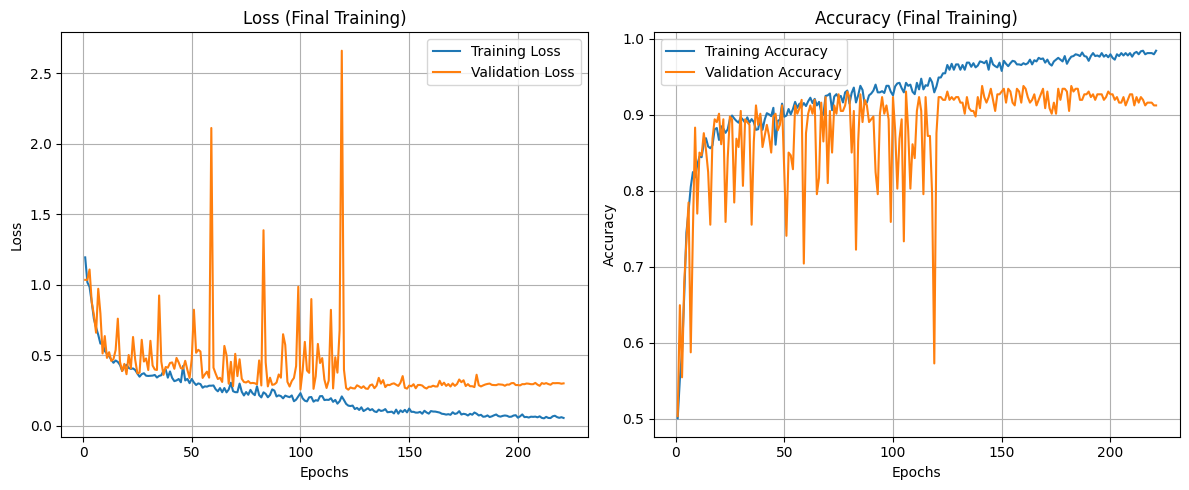


FINAL Confusion Matrix (Individual Classes):


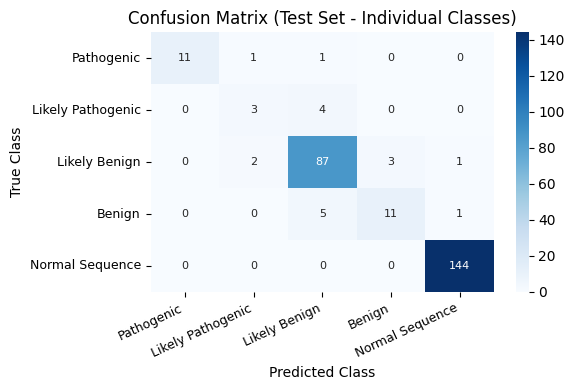


FINAL Confusion Matrix (Grouped Classes):


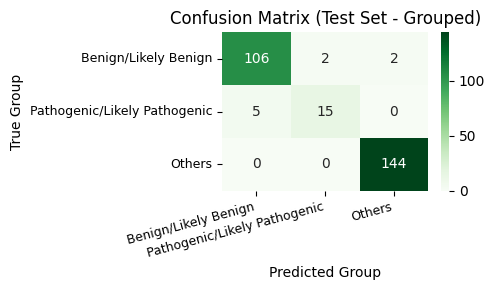


--- End of Plotting Script ---


In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd # For potential DataFrame display if seaborn fails

# Ensure variables from Cell 1 are accessible.
# These variables are:
# history, cm_final_data, target_names_display, eval_labels_display
# cm_grouped_data, target_names_grouped_display, unique_groups_final_data

print("\n--- Plotting Results ---")

# Check if history has data
if 'history' in locals() and history and history.get('train_loss') and history.get('val_loss'): # Check for val_loss too
    epochs_ran = range(1, len(history['train_loss']) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_ran, history['train_loss'], label='Training Loss')
    plt.plot(epochs_ran, history['val_loss'], label='Validation Loss')
    plt.title('Loss (Final Training)')
    plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)

    plt.subplot(1, 2, 2)
    # Check if accuracy data is present, it might not be if training failed very early
    if history.get('train_acc') and history.get('val_acc'):
        plt.plot(epochs_ran, history['train_acc'], label='Training Accuracy')
        plt.plot(epochs_ran, history['val_acc'], label='Validation Accuracy')
    plt.title('Accuracy (Final Training)')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)
    plt.tight_layout(); plt.show()
else:
    print("No complete training history to plot (e.g., training failed or was skipped before first validation).")

# Plot Individual Class Confusion Matrix
if 'cm_final_data' in locals() and cm_final_data is not None and \
   'target_names_display' in locals() and target_names_display is not None and \
   'eval_labels_display' in locals() and eval_labels_display is not None:
    print("\nFINAL Confusion Matrix (Individual Classes):")

    # Define the remapping for plot labels
    label_remapping = {
        'Neg Med (-2)': 'Pathogenic',
        'Neg Low (-1)': 'Likely Pathogenic',
        'Pos Low (1)': 'Likely Benign',
        'Pos Med (2)': 'Benign',
        'Pos High (3)': 'Normal Sequence',
        # Labels not in this map (e.g., 'Neg High (-3)') will remain unchanged
    }
    
    # Apply the remapping to get the desired display names for the plot
    # This creates a new list and does not modify target_names_display in place
    plot_target_names = [label_remapping.get(name, name) for name in target_names_display]

    try:
        plt.figure(figsize=(max(6, len(plot_target_names)), max(4, len(plot_target_names)-2)))
        sns.heatmap(cm_final_data, annot=True, fmt='d', cmap='Blues',
                    xticklabels=plot_target_names, yticklabels=plot_target_names, # Use remapped names
                    annot_kws={"size": 8})
        plt.xlabel('Predicted Class'); plt.ylabel('True Class')
        plt.title('Confusion Matrix (Test Set - Individual Classes)')
        plt.xticks(rotation=25, ha='right', fontsize=9); plt.yticks(rotation=0, fontsize=9)
        plt.tight_layout(); plt.show()
    except ImportError:
        print("Seaborn not installed. Displaying CM as DataFrame or array.")
        if 'pd' in locals(): # Check if pandas (pd) is available
            # Use the remapped plot_target_names for DataFrame display as well
            print(pd.DataFrame(cm_final_data, index=plot_target_names, columns=plot_target_names))
        else:
            # Fallback to printing the raw array if pandas is not available
            print(cm_final_data)
    except Exception as e:
        print(f"Could not plot individual confusion matrix: {e}")
else:
    print("Data for individual confusion matrix is not available (cm_final_data might be None).")


# Plot Grouped Confusion Matrix
if 'cm_grouped_data' in locals() and cm_grouped_data is not None and \
   'target_names_grouped_display' in locals() and target_names_grouped_display is not None and \
   'unique_groups_final_data' in locals() and unique_groups_final_data is not None:
    print("\nFINAL Confusion Matrix (Grouped Classes):")
    try:
        plt.figure(figsize=(max(5, len(target_names_grouped_display)), max(3, len(target_names_grouped_display)-1)))
        sns.heatmap(cm_grouped_data, annot=True, fmt='d', cmap='Greens',
                    xticklabels=target_names_grouped_display, yticklabels=target_names_grouped_display,
                    annot_kws={"size": 10})
        plt.xlabel('Predicted Group'); plt.ylabel('True Group')
        plt.title('Confusion Matrix (Test Set - Grouped)')
        plt.xticks(rotation=15, ha='right', fontsize=9); plt.yticks(rotation=0, fontsize=9)
        plt.tight_layout(); plt.show()
    except ImportError:
        print("Seaborn not installed. Displaying grouped CM as DataFrame or array.")
        print(pd.DataFrame(cm_grouped_data, index=target_names_grouped_display, columns=target_names_grouped_display) if 'pd' in locals() else cm_grouped_data)
    except Exception as e:
        print(f"Could not plot grouped confusion matrix: {e}")
else:
    print("Data for grouped confusion matrix is not available (cm_grouped_data might be None).")

print("\n--- End of Plotting Script ---")

Starting AUC Analysis...
Extracting probabilities from PyTorch model...
Successfully extracted probabilities with shape: (274, 5)
Probability range: [0.0000, 1.0000]
First sample probabilities: [4.4821400e-06 3.1716925e-07 2.5796489e-04 3.0219539e-05 9.9970692e-01]

=== AUC Analysis (Individual Classes) ===
Number of classes: 5
Class distribution in true labels: [ 13   7  93  17 144]
Using prediction probabilities for multi-class AUC


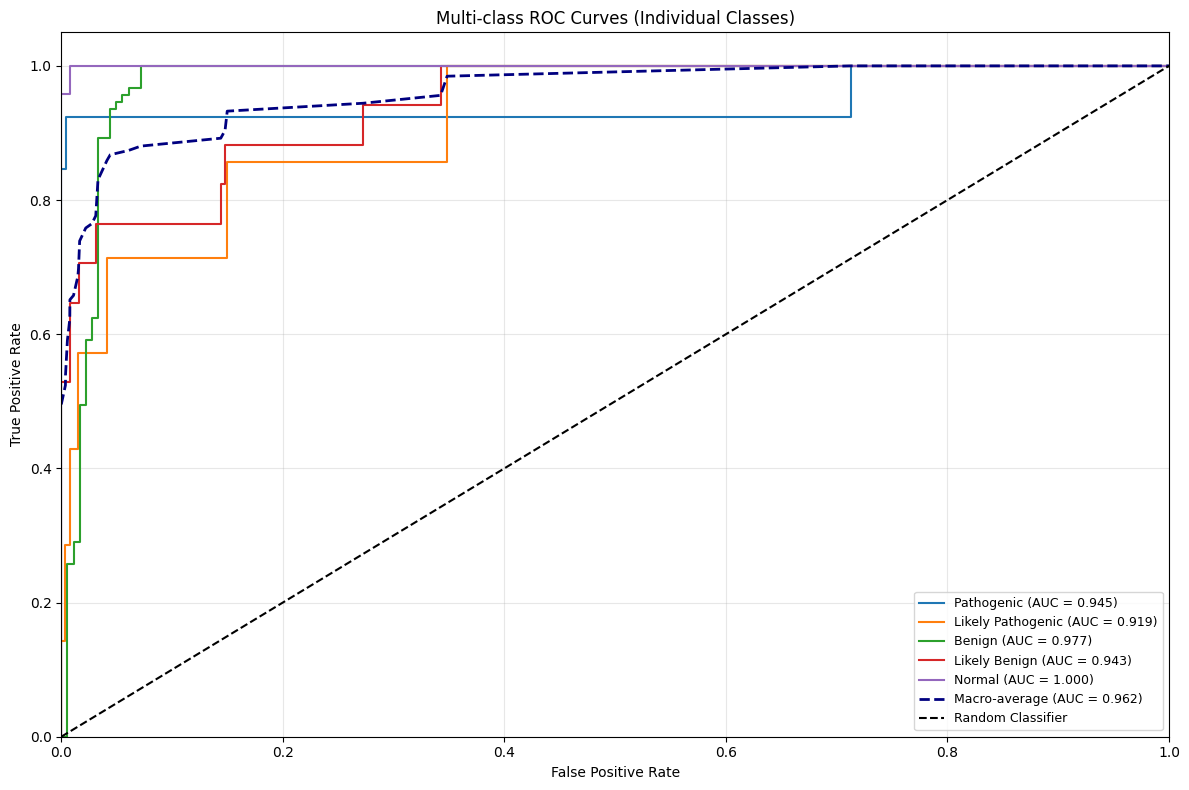

Micro-average AUC: 0.9893

Per-class AUC scores:
  Pathogenic: 0.9449
  Likely Pathogenic: 0.9192
  Benign: 0.9769
  Likely Benign: 0.9430
  Normal: 0.9997

Macro-average AUC: 0.9618
Converting individual class probabilities to grouped class probabilities...
Grouped probabilities shape: (274, 3)
First sample grouped probabilities: [2.88184425e-04 4.79930921e-06 9.99706924e-01]

=== AUC Analysis (Grouped Classes) ===
Number of classes: 3
Class distribution in true labels: [110  20 144]
Using prediction probabilities for multi-class AUC


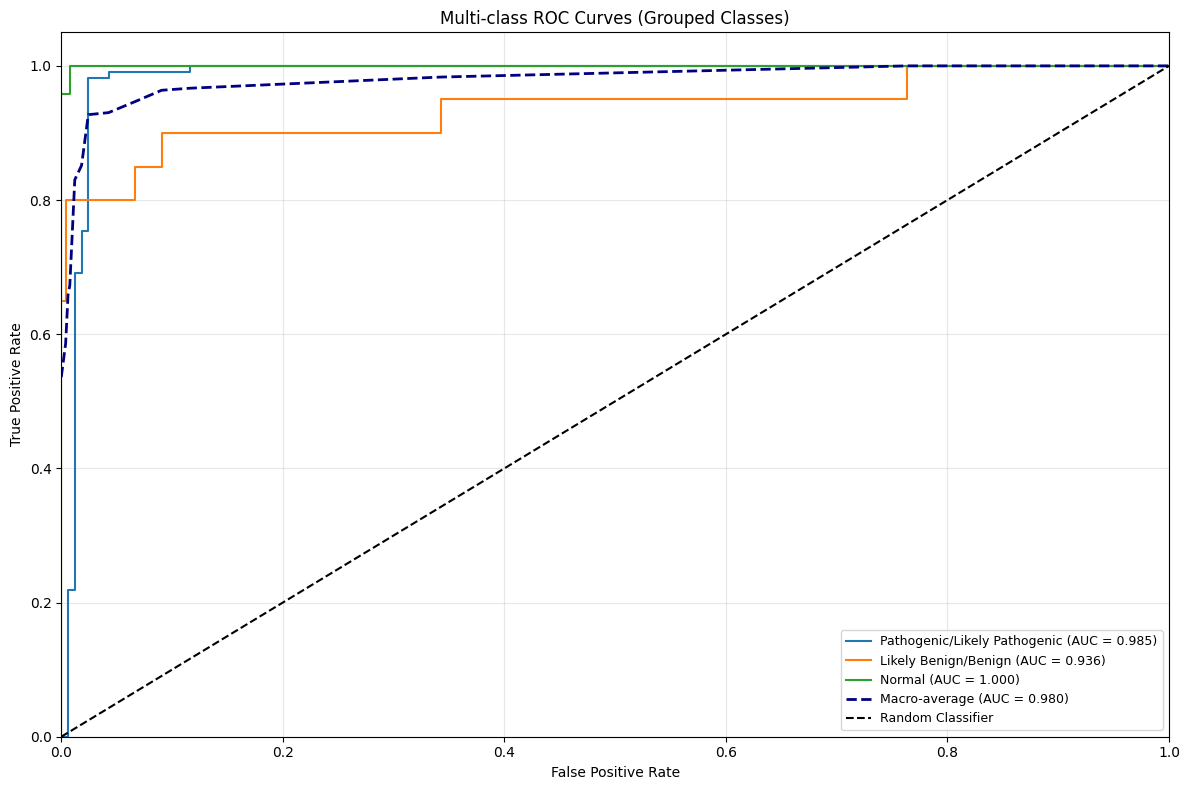

Micro-average AUC: 0.9904

Per-class AUC scores:
  Pathogenic/Likely Pathogenic: 0.9848
  Likely Benign/Benign: 0.9362
  Normal: 0.9997

Macro-average AUC: 0.9803

=== AUC Summary ===
Individual Classes Macro-AUC: 0.9618
Grouped Classes Macro-AUC: 0.9803


In [60]:
def analyze_auc_performance(y_true, y_pred_proba, y_pred_labels, class_names=None, title_suffix=""):
    """
    Comprehensive AUC analysis for multi-class classification.
    
    Args:
        y_true: True labels (encoded)
        y_pred_proba: Prediction probabilities (if available)
        y_pred_labels: Predicted labels (encoded)
        class_names: List of class names for display
        title_suffix: Suffix for plot titles
    
    Returns:
        dict: Dictionary containing AUC scores and metrics
    """
    from sklearn.metrics import roc_auc_score, roc_curve, auc
    from sklearn.preprocessing import label_binarize
    import matplotlib.pyplot as plt
    import numpy as np
    
    results = {}
    
    # Get unique classes
    unique_classes = np.unique(np.concatenate([y_true, y_pred_labels]))
    n_classes = len(unique_classes)
    
    # Set class names if not provided - map encoded labels to descriptive names
    if class_names is None:
        # Create mapping for individual classes (0-4 encoding)
        label_mapping = {
            0: "Pathogenic",
            1: "Likely Pathogenic", 
            2: "Benign",
            3: "Likely Benign",
            4: "Normal"
        }
        class_names = [label_mapping.get(i, f"Class {i}") for i in unique_classes]
    
    print(f"\n=== AUC Analysis {title_suffix} ===")
    print(f"Number of classes: {n_classes}")
    print(f"Class distribution in true labels: {np.bincount(y_true)}")
    
    try:
        if n_classes > 2:
            # Multi-class ROC-AUC using One-vs-Rest
            if y_pred_proba is not None:
                print("Using prediction probabilities for multi-class AUC")
                # Binarize the labels for multi-class ROC
                y_true_bin = label_binarize(y_true, classes=unique_classes)
                
                # Calculate ROC curve and AUC for each class
                fpr = dict()
                tpr = dict()
                roc_auc = dict()
                
                # Ensure y_pred_proba has the right shape
                if y_pred_proba.shape[1] != n_classes:
                    print(f"Warning: Probability shape {y_pred_proba.shape} doesn't match classes {n_classes}")
                    # Try to use available probabilities
                    n_prob_classes = min(y_pred_proba.shape[1], n_classes)
                else:
                    n_prob_classes = n_classes
                
                # Calculate per-class AUC
                for i in range(n_prob_classes):
                    if i < y_true_bin.shape[1] and i < len(unique_classes):  # Make sure we have true labels for this class
                        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
                        roc_auc[i] = auc(fpr[i], tpr[i])
                
                # Calculate macro-average ROC curve and AUC
                if len(fpr) > 1:
                    # First aggregate all false positive rates
                    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(fpr))]))
                    
                    # Then interpolate all ROC curves at this points
                    mean_tpr = np.zeros_like(all_fpr)
                    for i in range(len(fpr)):
                        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
                    
                    # Finally average it and compute AUC
                    mean_tpr /= len(fpr)
                    fpr["macro"] = all_fpr
                    tpr["macro"] = mean_tpr
                    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
                
                # Plot ROC curves
                plt.figure(figsize=(12, 8))
                
                # Plot individual class ROC curves
                for i in roc_auc.keys():
                    if i != "macro" and isinstance(i, int):
                        class_name = class_names[i] if i < len(class_names) else f"Class {unique_classes[i] if i < len(unique_classes) else i}"
                        plt.plot(fpr[i], tpr[i], 
                                label=f'{class_name} (AUC = {roc_auc[i]:.3f})')
                
                # Plot macro-average ROC curve
                if "macro" in roc_auc:
                    plt.plot(fpr["macro"], tpr["macro"],
                            label=f'Macro-average (AUC = {roc_auc["macro"]:.3f})',
                            color='navy', linestyle='--', linewidth=2)
                
                plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
                plt.xlim([0.0, 1.0])
                plt.ylim([0.0, 1.05])
                plt.xlabel('False Positive Rate')
                plt.ylabel('True Positive Rate')
                plt.title(f'Multi-class ROC Curves {title_suffix}')
                plt.legend(loc="lower right", fontsize=9)
                plt.grid(True, alpha=0.3)
                plt.tight_layout()
                plt.show()
                
                # Store results
                results['individual_auc'] = roc_auc
                results['macro_auc'] = roc_auc.get("macro", None)
                
                # Calculate micro-average AUC (for multi-class)
                try:
                    y_true_flat = y_true_bin.ravel()
                    y_pred_flat = y_pred_proba[:, :y_true_bin.shape[1]].ravel()
                    fpr_micro, tpr_micro, _ = roc_curve(y_true_flat, y_pred_flat)
                    results['micro_auc'] = auc(fpr_micro, tpr_micro)
                    print(f"Micro-average AUC: {results['micro_auc']:.4f}")
                except:
                    results['micro_auc'] = None
                    print("Could not calculate micro-average AUC")
                
                # Print individual class AUCs
                print("\nPer-class AUC scores:")
                for i, auc_score in roc_auc.items():
                    if i != "macro" and isinstance(i, int):
                        class_name = class_names[i] if i < len(class_names) else f"Class {unique_classes[i] if i < len(unique_classes) else i}"
                        print(f"  {class_name}: {auc_score:.4f}")
                
                if "macro" in roc_auc:
                    print(f"\nMacro-average AUC: {roc_auc['macro']:.4f}")
            else:
                # Multi-class without probabilities - use One-vs-All approach with label encoding
                print("No probabilities available - using label-based multi-class AUC (One-vs-All)")
                from sklearn.metrics import roc_auc_score as sklearn_auc
                
                try:
                    # Calculate macro and weighted AUC using sklearn's multi-class handling
                    macro_auc = sklearn_auc(y_true, y_pred_labels, multi_class='ovr', average='macro')
                    weighted_auc = sklearn_auc(y_true, y_pred_labels, multi_class='ovr', average='weighted')
                    
                    results['macro_auc'] = macro_auc
                    results['weighted_auc'] = weighted_auc
                    
                    print(f"Macro-average AUC (One-vs-All): {macro_auc:.4f}")
                    print(f"Weighted-average AUC (One-vs-All): {weighted_auc:.4f}")
                    
                    # Calculate per-class AUC using One-vs-All
                    individual_aucs = {}
                    y_true_bin = label_binarize(y_true, classes=unique_classes)
                    y_pred_bin = label_binarize(y_pred_labels, classes=unique_classes)
                    
                    for i, class_label in enumerate(unique_classes):
                        if i < y_true_bin.shape[1] and i < y_pred_bin.shape[1]:
                            try:
                                class_auc = sklearn_auc(y_true_bin[:, i], y_pred_bin[:, i])
                                individual_aucs[i] = class_auc
                                class_name = class_names[i] if i < len(class_names) else f"Class {class_label}"
                                print(f"  {class_name}: {class_auc:.4f}")
                            except:
                                print(f"  {class_names[i] if i < len(class_names) else f'Class {class_label}'}: Could not calculate (constant class)")
                    
                    results['individual_auc'] = individual_aucs
                    
                except Exception as e:
                    print(f"Could not calculate multi-class AUC without probabilities: {str(e)}")
                    results['error'] = f"Multi-class AUC failed: {str(e)}"
        
        elif n_classes == 2:
            # Binary classification
            if y_pred_proba is not None:
                # Use probabilities for positive class
                y_scores = y_pred_proba[:, 1] if y_pred_proba.shape[1] > 1 else y_pred_proba.ravel()
            else:
                # Use predicted labels as scores (less ideal but still valid for binary)
                y_scores = y_pred_labels
            
            fpr, tpr, thresholds = roc_curve(y_true, y_scores)
            roc_auc_score = auc(fpr, tpr)
            
            # Plot binary ROC curve
            plt.figure(figsize=(8, 6))
            plt.plot(fpr, tpr, color='darkorange', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc_score:.3f})')
            plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
            plt.xlim([0.0, 1.0])
            plt.ylim([0.0, 1.05])
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title(f'Binary ROC Curve {title_suffix}')
            plt.legend(loc="lower right")
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
            
            results['binary_auc'] = roc_auc_score
            print(f"Binary AUC: {roc_auc_score:.4f}")
        
        elif n_classes == 1:
            print("Single class detected - AUC analysis not applicable")
            results['error'] = "Single class - AUC not applicable"
        
        else:
            print("No classes detected - AUC analysis not applicable")
            results['error'] = "No classes - AUC not applicable"
    
    except Exception as e:
        print(f"Error in AUC analysis: {str(e)}")
        results['error'] = str(e)
    
    return results

# Run AUC analysis if we have the necessary variables
if 'y_test_eval' in locals() and 'y_pred_eval' in locals():
    print("Starting AUC Analysis...")
    
    # Extract prediction probabilities from the PyTorch model
    y_pred_proba = None
    if 'final_model' in locals() and 'X_test_fused_scaled' in locals():
        try:
            print("Extracting probabilities from PyTorch model...")
            final_model.eval()  # Set to evaluation mode
            
            # Convert test data to tensor if needed
            if not isinstance(X_test_fused_scaled, torch.Tensor):
                X_test_tensor_auc = torch.FloatTensor(X_test_fused_scaled).to(device)
            else:
                X_test_tensor_auc = X_test_fused_scaled.to(device)
            
            # Get predictions with no gradient tracking
            with torch.no_grad():
                # Get raw logits from the model
                logits = final_model(X_test_tensor_auc)
                # Apply softmax to get probabilities
                probabilities = torch.softmax(logits, dim=1)
                # Convert to numpy
                y_pred_proba = probabilities.cpu().numpy()
            
            print(f"Successfully extracted probabilities with shape: {y_pred_proba.shape}")
            print(f"Probability range: [{y_pred_proba.min():.4f}, {y_pred_proba.max():.4f}]")
            print(f"First sample probabilities: {y_pred_proba[0]}")
            
        except Exception as e:
            print(f"Could not extract probabilities from model: {str(e)}")
            y_pred_proba = None
    
    # Create proper class names for individual classes
    individual_class_names = ["Pathogenic", "Likely Pathogenic", "Benign", "Likely Benign", "Normal"]
    
    # Individual classes analysis
    auc_results_individual = analyze_auc_performance(
        y_test_eval, y_pred_proba, y_pred_eval, 
        class_names=individual_class_names, 
        title_suffix="(Individual Classes)"
    )
    
    # Grouped classes analysis
    if 'y_true_grouped_final_data' in locals() and 'y_pred_grouped_final_data' in locals():
        # Extract probabilities for grouped classes from individual class probabilities
        y_pred_proba_grouped = None
        if y_pred_proba is not None and 'group_mapping_from_encoded' in locals():
            try:
                print("Converting individual class probabilities to grouped class probabilities...")
                # Get the number of unique groups
                unique_groups = sorted(list(set(y_true_grouped_final_data)))
                n_groups = len(unique_groups)
                
                # Initialize grouped probabilities
                y_pred_proba_grouped = np.zeros((y_pred_proba.shape[0], n_groups))
                
                # Sum probabilities for classes that belong to each group
                for sample_idx in range(y_pred_proba.shape[0]):
                    for class_idx in range(y_pred_proba.shape[1]):
                        # Get which group this class belongs to
                        group_idx = group_mapping_from_encoded.get(class_idx, 2)  # default to group 2 (Others)
                        if group_idx in unique_groups:
                            group_position = unique_groups.index(group_idx)
                            y_pred_proba_grouped[sample_idx, group_position] += y_pred_proba[sample_idx, class_idx]
                
                print(f"Grouped probabilities shape: {y_pred_proba_grouped.shape}")
                print(f"First sample grouped probabilities: {y_pred_proba_grouped[0]}")
                
            except Exception as e:
                print(f"Could not extract grouped probabilities: {str(e)}")
                y_pred_proba_grouped = None
        
        # Create proper class names for grouped classes
        grouped_class_names = ["Pathogenic/Likely Pathogenic", "Likely Benign/Benign", "Normal"]
        
        auc_results_grouped = analyze_auc_performance(
            y_true_grouped_final_data, y_pred_proba_grouped, y_pred_grouped_final_data,
            class_names=grouped_class_names,
            title_suffix="(Grouped Classes)"
        )
        
        print(f"\n=== AUC Summary ===")
        if 'macro_auc' in auc_results_individual and auc_results_individual['macro_auc']:
            print(f"Individual Classes Macro-AUC: {auc_results_individual['macro_auc']:.4f}")
        if 'binary_auc' in auc_results_grouped:
            print(f"Grouped Classes AUC: {auc_results_grouped['binary_auc']:.4f}")
        elif 'macro_auc' in auc_results_grouped and auc_results_grouped['macro_auc']:
            print(f"Grouped Classes Macro-AUC: {auc_results_grouped['macro_auc']:.4f}")
    
else:
    print("Required variables (y_test_eval, y_pred_eval) not found for AUC analysis.")

Starting AUC Analysis (Excluding Normal Class)...

=== AUC Analysis (Excluding Normal Class) (Individual Classes - No Normal) ===
Excluded normal class (encoded as: 4)
Remaining classes: [0 1 2 3 4]
Number of classes: 5
Number of samples after filtering: 130
Class distribution in filtered true labels: [13  7 93 17]
Using prediction probabilities for multi-class AUC (excluding normal)
Error in AUC analysis: index 4 is out of bounds for axis 1 with size 4

=== Binary Analysis: Pathogenic vs Benign (Excluding Normal) ===

=== AUC Analysis (Binary: Pathogenic vs Benign) ===
Number of classes: 2
Class distribution in true labels: [ 20 110]


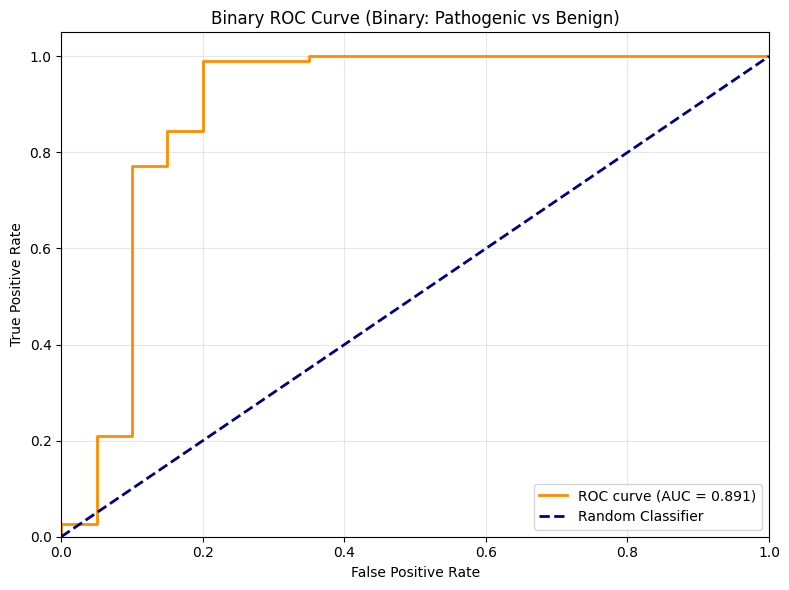

Binary AUC: 0.8914

=== Final AUC Summary (Excluding Normal) ===
Binary AUC (Pathogenic vs Benign): 0.8914


In [61]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
from sklearn.metrics import roc_auc_score as sklearn_auc

def analyze_auc_performance_exclude_normal(y_true, y_pred_proba, y_pred_labels, class_names=None, title_suffix=""):
    """
    Comprehensive AUC analysis for multi-class classification excluding normal class.
    
    Args:
        y_true: True labels (encoded)
        y_pred_proba: Prediction probabilities (if available)
        y_pred_labels: Predicted labels (encoded)
        class_names: List of class names for display
        title_suffix: Suffix for plot titles
    
    Returns:
        dict: Dictionary containing AUC scores and metrics
    """
    import matplotlib.pyplot as plt
    
    results = {}
    
    # Identify the normal class (typically the highest encoded value)
    unique_classes = np.unique(np.concatenate([y_true, y_pred_labels]))
    
    # Assuming normal class has the highest encoded value
    normal_class = max(unique_classes)
    
    # Filter out normal class samples
    non_normal_mask = y_true != normal_class
    y_true_filtered = y_true[non_normal_mask]
    y_pred_labels_filtered = y_pred_labels[non_normal_mask]
    
    if y_pred_proba is not None:
        y_pred_proba_filtered = y_pred_proba[non_normal_mask]
        # Remove the normal class column from probabilities
        non_normal_classes = [i for i, cls in enumerate(unique_classes) if cls != normal_class]
        y_pred_proba_filtered = y_pred_proba_filtered[:, non_normal_classes]
    else:
        y_pred_proba_filtered = None
    
    # Update unique classes and remap labels
    filtered_unique_classes = np.unique(np.concatenate([y_true_filtered, y_pred_labels_filtered]))
    n_classes = len(filtered_unique_classes)
    
    # Create mapping from old to new labels
    label_mapping = {old_label: new_label for new_label, old_label in enumerate(filtered_unique_classes)}
    
    # Remap labels to be consecutive starting from 0
    y_true_remapped = np.array([label_mapping[label] for label in y_true_filtered])
    y_pred_remapped = np.array([label_mapping[label] for label in y_pred_labels_filtered])
    
    # Set class names if not provided
    if class_names is None:
        original_label_mapping = {
            0: "Pathogenic",
            1: "Likely Pathogenic", 
            2: "Benign",
            3: "Likely Benign"
        }
        class_names = [original_label_mapping.get(cls, f"Class {cls}") for cls in filtered_unique_classes]
    else:
        # Filter class names to exclude normal class
        class_names = [class_names[i] for i in range(len(class_names)) if i in non_normal_classes]
    
    print(f"\n=== AUC Analysis (Excluding Normal Class) {title_suffix} ===")
    print(f"Excluded normal class (encoded as: {normal_class})")
    print(f"Remaining classes: {filtered_unique_classes}")
    print(f"Number of classes: {n_classes}")
    print(f"Number of samples after filtering: {len(y_true_filtered)}")
    print(f"Class distribution in filtered true labels: {np.bincount(y_true_remapped)}")
    
    try:
        if n_classes > 2:
            # Multi-class ROC-AUC using One-vs-Rest
            if y_pred_proba_filtered is not None:
                print("Using prediction probabilities for multi-class AUC (excluding normal)")
                
                # Renormalize probabilities after removing normal class
                y_pred_proba_renorm = y_pred_proba_filtered / y_pred_proba_filtered.sum(axis=1, keepdims=True)
                
                # Binarize the remapped labels for multi-class ROC
                y_true_bin = label_binarize(y_true_remapped, classes=range(n_classes))
                
                # Calculate ROC curve and AUC for each class
                fpr = dict()
                tpr = dict()
                roc_auc = dict()
                
                # Calculate per-class AUC
                for i in range(n_classes):
                    if i < y_true_bin.shape[1]:
                        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_proba_renorm[:, i])
                        roc_auc[i] = auc(fpr[i], tpr[i])
                
                # Calculate macro-average ROC curve and AUC
                if len(fpr) > 1:
                    # First aggregate all false positive rates
                    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(fpr))]))
                    
                    # Then interpolate all ROC curves at this points
                    mean_tpr = np.zeros_like(all_fpr)
                    for i in range(len(fpr)):
                        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
                    
                    # Finally average it and compute AUC
                    mean_tpr /= len(fpr)
                    fpr["macro"] = all_fpr
                    tpr["macro"] = mean_tpr
                    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
                
                # Plot ROC curves
                plt.figure(figsize=(12, 8))
                
                # Plot individual class ROC curves
                for i in roc_auc.keys():
                    if i != "macro" and isinstance(i, int):
                        class_name = class_names[i] if i < len(class_names) else f"Class {filtered_unique_classes[i]}"
                        plt.plot(fpr[i], tpr[i], 
                                label=f'{class_name} (AUC = {roc_auc[i]:.3f})')
                
                # Plot macro-average ROC curve
                if "macro" in roc_auc:
                    plt.plot(fpr["macro"], tpr["macro"],
                            label=f'Macro-average (AUC = {roc_auc["macro"]:.3f})',
                            color='navy', linestyle='--', linewidth=2)
                
                plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
                plt.xlim([0.0, 1.0])
                plt.ylim([0.0, 1.05])
                plt.xlabel('False Positive Rate')
                plt.ylabel('True Positive Rate')
                plt.title(f'Multi-class ROC Curves (Excluding Normal) {title_suffix}')
                plt.legend(loc="lower right", fontsize=9)
                plt.grid(True, alpha=0.3)
                plt.tight_layout()
                plt.show()
                
                # Store results
                results['individual_auc'] = roc_auc
                results['macro_auc'] = roc_auc.get("macro", None)
                
                # Calculate micro-average AUC (for multi-class)
                try:
                    y_true_flat = y_true_bin.ravel()
                    y_pred_flat = y_pred_proba_renorm.ravel()
                    fpr_micro, tpr_micro, _ = roc_curve(y_true_flat, y_pred_flat)
                    results['micro_auc'] = auc(fpr_micro, tpr_micro)
                    print(f"Micro-average AUC: {results['micro_auc']:.4f}")
                except:
                    results['micro_auc'] = None
                    print("Could not calculate micro-average AUC")
                
                # Print individual class AUCs
                print("\nPer-class AUC scores (excluding normal):")
                for i, auc_score in roc_auc.items():
                    if i != "macro" and isinstance(i, int):
                        class_name = class_names[i] if i < len(class_names) else f"Class {filtered_unique_classes[i]}"
                        print(f"  {class_name}: {auc_score:.4f}")
                
                if "macro" in roc_auc:
                    print(f"\nMacro-average AUC (excluding normal): {roc_auc['macro']:.4f}")
            else:
                print("No probabilities available - using label-based multi-class AUC")
                
                try:
                    # Calculate macro and weighted AUC using sklearn's multi-class handling
                    macro_auc = sklearn_auc(y_true_remapped, y_pred_remapped, multi_class='ovr', average='macro')
                    weighted_auc = sklearn_auc(y_true_remapped, y_pred_remapped, multi_class='ovr', average='weighted')
                    
                    results['macro_auc'] = macro_auc
                    results['weighted_auc'] = weighted_auc
                    
                    print(f"Macro-average AUC (One-vs-All, excluding normal): {macro_auc:.4f}")
                    print(f"Weighted-average AUC (One-vs-All, excluding normal): {weighted_auc:.4f}")
                    
                except Exception as e:
                    print(f"Could not calculate multi-class AUC without probabilities: {str(e)}")
                    results['error'] = f"Multi-class AUC failed: {str(e)}"
        
        elif n_classes == 2:
            # Binary classification
            if y_pred_proba_filtered is not None:
                # Renormalize probabilities
                y_pred_proba_renorm = y_pred_proba_filtered / y_pred_proba_filtered.sum(axis=1, keepdims=True)
                y_scores = y_pred_proba_renorm[:, 1] if y_pred_proba_renorm.shape[1] > 1 else y_pred_proba_renorm.ravel()
            else:
                y_scores = y_pred_remapped
            
            fpr, tpr, thresholds = roc_curve(y_true_remapped, y_scores)
            roc_auc_score = auc(fpr, tpr)
            
            # Plot binary ROC curve
            plt.figure(figsize=(8, 6))
            plt.plot(fpr, tpr, color='darkorange', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc_score:.3f})')
            plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
            plt.xlim([0.0, 1.0])
            plt.ylim([0.0, 1.05])
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title(f'Binary ROC Curve (Excluding Normal) {title_suffix}')
            plt.legend(loc="lower right")
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
            
            results['binary_auc'] = roc_auc_score
            print(f"Binary AUC (excluding normal): {roc_auc_score:.4f}")
        
        elif n_classes == 1:
            print("Single class detected after filtering - AUC analysis not applicable")
            results['error'] = "Single class after filtering - AUC not applicable"
        
        else:
            print("No classes detected after filtering - AUC analysis not applicable")
            results['error'] = "No classes after filtering - AUC not applicable"
    
    except Exception as e:
        print(f"Error in AUC analysis: {str(e)}")
        results['error'] = str(e)
    
    return results

# Run AUC analysis excluding normal class
if 'y_test_eval' in locals() and 'y_pred_eval' in locals():
    print("Starting AUC Analysis (Excluding Normal Class)...")
    
    # Extract prediction probabilities from the PyTorch model (if not already done)
    if 'y_pred_proba' not in locals() or y_pred_proba is None:
        if 'final_model' in locals() and 'X_test_fused_scaled' in locals():
            try:
                print("Extracting probabilities from PyTorch model...")
                final_model.eval()
                
                if not isinstance(X_test_fused_scaled, torch.Tensor):
                    X_test_tensor_auc = torch.FloatTensor(X_test_fused_scaled).to(device)
                else:
                    X_test_tensor_auc = X_test_fused_scaled.to(device)
                
                with torch.no_grad():
                    logits = final_model(X_test_tensor_auc)
                    probabilities = torch.softmax(logits, dim=1)
                    y_pred_proba = probabilities.cpu().numpy()
                
                print(f"Successfully extracted probabilities with shape: {y_pred_proba.shape}")
                
            except Exception as e:
                print(f"Could not extract probabilities from model: {str(e)}")
                y_pred_proba = None
    
    # Individual classes analysis excluding normal
    individual_class_names = ["Pathogenic", "Likely Pathogenic", "Benign", "Likely Benign", "Normal"]
    
    auc_results_no_normal = analyze_auc_performance_exclude_normal(
        y_test_eval, y_pred_proba, y_pred_eval, 
        class_names=individual_class_names, 
        title_suffix="(Individual Classes - No Normal)"
    )
    
    # Also run binary analysis: Pathogenic/Likely Pathogenic vs Benign/Likely Benign (excluding normal)
    if 'le' in locals():
        print("\n=== Binary Analysis: Pathogenic vs Benign (Excluding Normal) ===")
        
        # Create binary labels: 0 = Pathogenic/Likely Pathogenic, 1 = Benign/Likely Benign
        benign_classes = {1, 2}  # Original classes for Benign/Likely Benign
        pathogenic_classes = {-1, -2}  # Original classes for Pathogenic/Likely Pathogenic
        
        # Filter out normal class and samples we can't classify
        binary_mask = np.array([le.classes_[label] in (benign_classes | pathogenic_classes) for label in y_test_eval])
        
        if np.sum(binary_mask) > 0:
            y_test_binary_filtered = y_test_eval[binary_mask]
            y_pred_binary_filtered = y_pred_eval[binary_mask]
            
            # Create binary labels (0 = pathogenic, 1 = benign)
            y_true_binary = np.array([1 if le.classes_[label] in benign_classes else 0 for label in y_test_binary_filtered])
            y_pred_binary = np.array([1 if le.classes_[label] in benign_classes else 0 for label in y_pred_binary_filtered])
            
            if y_pred_proba is not None:
                y_pred_proba_binary_filtered = y_pred_proba[binary_mask]
                
                # Sum probabilities for benign classes (classes 2, 3 in encoded form)
                benign_encoded = [i for i, orig_class in enumerate(le.classes_) if orig_class in benign_classes]
                pathogenic_encoded = [i for i, orig_class in enumerate(le.classes_) if orig_class in pathogenic_classes]
                
                benign_prob = np.sum(y_pred_proba_binary_filtered[:, benign_encoded], axis=1)
                pathogenic_prob = np.sum(y_pred_proba_binary_filtered[:, pathogenic_encoded], axis=1)
                
                # Normalize to get proper probabilities
                total_prob = benign_prob + pathogenic_prob
                benign_prob_norm = benign_prob / (total_prob + 1e-8)
                
                y_pred_proba_binary = np.column_stack([1 - benign_prob_norm, benign_prob_norm])
            else:
                y_pred_proba_binary = None
            
            binary_class_names = ["Pathogenic/Likely Pathogenic", "Benign/Likely Benign"]
            
            auc_results_binary = analyze_auc_performance(
                y_true_binary, y_pred_proba_binary, y_pred_binary,
                class_names=binary_class_names,
                title_suffix="(Binary: Pathogenic vs Benign)"
            )
            
            print(f"\n=== Final AUC Summary (Excluding Normal) ===")
            if 'macro_auc' in auc_results_no_normal and auc_results_no_normal['macro_auc']:
                print(f"Multi-class Macro-AUC (no normal): {auc_results_no_normal['macro_auc']:.4f}")
            if 'binary_auc' in auc_results_binary:
                print(f"Binary AUC (Pathogenic vs Benign): {auc_results_binary['binary_auc']:.4f}")
        else:
            print("No samples found for binary analysis after filtering.")
    
else:
    print("Required variables (y_test_eval, y_pred_eval) not found for AUC analysis.")

🎯 BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY
✅ Original individual class data available
   Original classes available: [-2 -1  1  2  3]

📋 TARGET CLASSES:
   Class -2: Pathogenic
   Class 2: Benign

📊 SAMPLE DISTRIBUTION:
   Total test samples: 274
   Class -2 samples: 13 (4.7%)
   Class 2 samples: 17 (6.2%)
   Target analysis samples: 30 (10.9%)
   Class -2 encoded index: 0
   Class 2 encoded index: 3
   ✅ Successfully computed binary probabilities
   Probability range: [0.000, 1.000]

📈 BINARY CLASSIFICATION RESULTS (-2 vs 2):
   Filtered samples: 30
   Pathogenic (-2): 13 true, 11 predicted
   Benign (2): 17 true, 19 predicted

📊 PERFORMANCE METRICS:
----------------------------------------
✅ Accuracy:    0.9333 (93.33%)
🎯 Precision:   1.0000 (100.00%) - When model says 'Pathogenic (-2)', how often is it right?
🔍 Recall:      0.8462 (84.62%) - How many actual pathogenic (-2) variants did we catch?
📊 F1-Score:    0.9167 (91.67%) - Balanced measure of precision and recall
🛡️  Spe

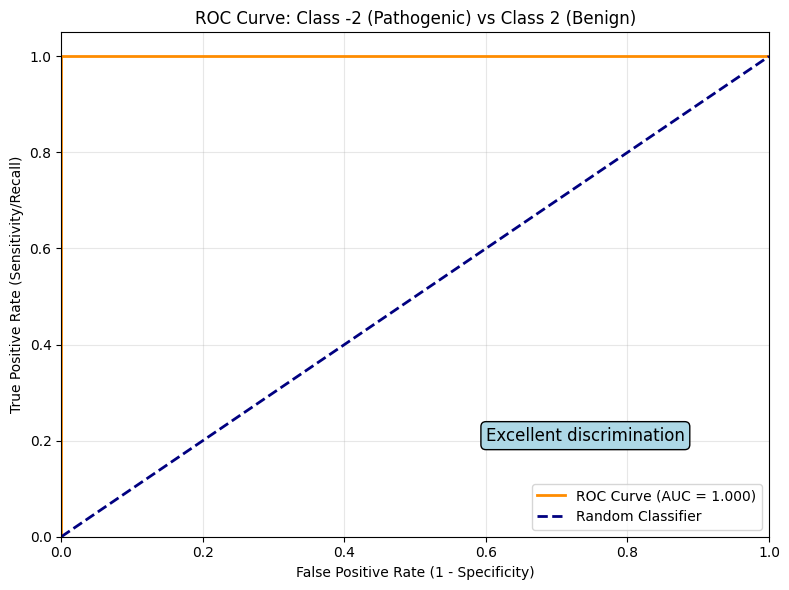


💡 SUMMARY:
   Your model achieves 93.3% accuracy in distinguishing
   between class -2 (Pathogenic) and class 2 (Benign) variants.
   AUC of 1.000 indicates excellent discrimination between these extreme classes.


In [62]:
# Binary Classification Analysis: Class -2 vs Class 2 Only
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

print("🎯 BINARY CLASSIFICATION: CLASS -2 vs CLASS 2 ONLY")
print("="*60)

# Check if we have the required data
if 'y_test_eval' in locals() and 'y_pred_eval' in locals() and 'le' in locals():
    print("✅ Original individual class data available")
    
    # Map encoded classes back to original classes
    y_test_original = le.inverse_transform(y_test_eval)
    y_pred_original = le.inverse_transform(y_pred_eval)
    
    print(f"   Original classes available: {np.unique(y_test_original)}")
    
    # Define target classes: -2 vs 2 only
    target_classes = {-2, 2}
    
    print(f"\n📋 TARGET CLASSES:")
    print(f"   Class -2: Pathogenic")
    print(f"   Class 2: Benign") 
    
    # Create mask for samples that are either -2 or 2
    target_mask = np.isin(y_test_original, list(target_classes))
    
    print(f"\n📊 SAMPLE DISTRIBUTION:")
    print(f"   Total test samples: {len(y_test_original)}")
    print(f"   Class -2 samples: {np.sum(y_test_original == -2)} ({np.sum(y_test_original == -2)/len(y_test_original)*100:.1f}%)")
    print(f"   Class 2 samples: {np.sum(y_test_original == 2)} ({np.sum(y_test_original == 2)/len(y_test_original)*100:.1f}%)")
    print(f"   Target analysis samples: {np.sum(target_mask)} ({np.sum(target_mask)/len(y_test_original)*100:.1f}%)")
    
    if np.sum(target_mask) > 0 and np.sum(y_test_original == -2) > 0 and np.sum(y_test_original == 2) > 0:
        # Filter data for binary analysis (-2 vs 2 only)
        y_test_filtered = y_test_original[target_mask]
        y_pred_filtered = y_pred_original[target_mask]
        
        # Create binary labels: 1 = Pathogenic (-2), 0 = Benign (2)
        y_true_binary_filtered = np.where(y_test_filtered == -2, 1, 0)
        y_pred_binary_filtered = np.where(y_pred_filtered == -2, 1, 0)
        
        # Get probabilities if available
        y_pred_proba_binary_filtered = None
        if 'y_pred_proba' in locals() and y_pred_proba is not None:
            try:
                # Filter probabilities for target samples
                y_pred_proba_target = y_pred_proba[target_mask]
                
                # Get encoded indices for classes -2 and 2
                class_neg2_idx = np.where(le.classes_ == -2)[0][0] if -2 in le.classes_ else None
                class_pos2_idx = np.where(le.classes_ == 2)[0][0] if 2 in le.classes_ else None
                
                if class_neg2_idx is not None and class_pos2_idx is not None:
                    print(f"   Class -2 encoded index: {class_neg2_idx}")
                    print(f"   Class 2 encoded index: {class_pos2_idx}")
                    
                    # Calculate binary probabilities
                    prob_pathogenic = y_pred_proba_target[:, class_neg2_idx]
                    prob_benign = y_pred_proba_target[:, class_pos2_idx]
                    
                    # Normalize to get proper binary probabilities
                    total_prob = prob_pathogenic + prob_benign
                    total_prob = np.where(total_prob == 0, 1e-8, total_prob)  # Avoid division by zero
                    y_pred_proba_binary_filtered = prob_pathogenic / total_prob  # Probability of class -2
                    
                    print(f"   ✅ Successfully computed binary probabilities")
                    print(f"   Probability range: [{y_pred_proba_binary_filtered.min():.3f}, {y_pred_proba_binary_filtered.max():.3f}]")
                else:
                    print(f"   ❌ Could not find encoded indices for classes -2 or 2")
                    
            except Exception as e:
                print(f"   ❌ Could not compute binary probabilities: {str(e)}")
                y_pred_proba_binary_filtered = None
        else:
            print("   ⚠️  No probabilities available")
        
        print(f"\n📈 BINARY CLASSIFICATION RESULTS (-2 vs 2):")
        print(f"   Filtered samples: {len(y_true_binary_filtered)}")
        print(f"   Pathogenic (-2): {np.sum(y_true_binary_filtered == 1)} true, {np.sum(y_pred_binary_filtered == 1)} predicted")
        print(f"   Benign (2): {np.sum(y_true_binary_filtered == 0)} true, {np.sum(y_pred_binary_filtered == 0)} predicted")
        
        if len(np.unique(y_true_binary_filtered)) == 2:  # Ensure we have both classes
            print("\n📊 PERFORMANCE METRICS:")
            print("-" * 40)
            
            # Calculate metrics
            accuracy = accuracy_score(y_true_binary_filtered, y_pred_binary_filtered)
            precision = precision_score(y_true_binary_filtered, y_pred_binary_filtered, pos_label=1, zero_division=0)
            recall = recall_score(y_true_binary_filtered, y_pred_binary_filtered, pos_label=1, zero_division=0)
            f1 = f1_score(y_true_binary_filtered, y_pred_binary_filtered, pos_label=1, zero_division=0)
            
            # Calculate specificity
            cm_binary = confusion_matrix(y_true_binary_filtered, y_pred_binary_filtered)
            tn, fp, fn, tp = cm_binary.ravel()
            specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
            
            print(f"✅ Accuracy:    {accuracy:.4f} ({accuracy*100:.2f}%)")
            print(f"🎯 Precision:   {precision:.4f} ({precision*100:.2f}%) - When model says 'Pathogenic (-2)', how often is it right?")
            print(f"🔍 Recall:      {recall:.4f} ({recall*100:.2f}%) - How many actual pathogenic (-2) variants did we catch?")
            print(f"📊 F1-Score:    {f1:.4f} ({f1*100:.2f}%) - Balanced measure of precision and recall")
            print(f"🛡️  Specificity: {specificity:.4f} ({specificity*100:.2f}%) - How many benign (2) variants did we correctly identify?")
            
            # AUC calculation
            if y_pred_proba_binary_filtered is not None:
                try:
                    auc_binary = roc_auc_score(y_true_binary_filtered, y_pred_proba_binary_filtered)
                    print(f"📈 AUC:         {auc_binary:.4f} ({auc_binary*100:.2f}%) - Discrimination ability between -2 and 2")
                except Exception as e:
                    print(f"📈 AUC:         Could not calculate: {str(e)}")
            else:
                print("📈 AUC:         Not available (no probabilities)")
            
            print("\n🔢 CONFUSION MATRIX:")
            print("-" * 40)
            print("                    Predicted")
            print("                 Benign(2)  Pathogenic(-2)")
            print(f"Actual  Benign(2)    {cm_binary[0,0]:4d}        {cm_binary[0,1]:4d}")
            print(f"     Pathogenic(-2)  {cm_binary[1,0]:4d}        {cm_binary[1,1]:4d}")
            
            # Plot ROC curve if probabilities available
            if y_pred_proba_binary_filtered is not None:
                try:
                    plt.figure(figsize=(8, 6))
                    fpr, tpr, thresholds = roc_curve(y_true_binary_filtered, y_pred_proba_binary_filtered)
                    auc_score = roc_auc_score(y_true_binary_filtered, y_pred_proba_binary_filtered)
                    
                    plt.plot(fpr, tpr, color='darkorange', lw=2, 
                            label=f'ROC Curve (AUC = {auc_score:.3f})')
                    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
                            label='Random Classifier')
                    plt.xlim([0.0, 1.0])
                    plt.ylim([0.0, 1.05])
                    plt.xlabel('False Positive Rate (1 - Specificity)')
                    plt.ylabel('True Positive Rate (Sensitivity/Recall)')
                    plt.title('ROC Curve: Class -2 (Pathogenic) vs Class 2 (Benign)')
                    plt.legend(loc="lower right")
                    plt.grid(True, alpha=0.3)
                    
                    # Add interpretation text
                    if auc_score >= 0.9:
                        interpretation = "Excellent discrimination"
                    elif auc_score >= 0.8:
                        interpretation = "Good discrimination"
                    elif auc_score >= 0.7:
                        interpretation = "Fair discrimination"
                    else:
                        interpretation = "Poor discrimination"
                    
                    plt.text(0.6, 0.2, f'{interpretation}', fontsize=12, 
                            bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
                    
                    plt.tight_layout()
                    plt.show()
                except Exception as e:
                    print(f"   Could not plot ROC curve: {str(e)}")
            
            print(f"\n💡 SUMMARY:")
            print(f"   Your model achieves {accuracy*100:.1f}% accuracy in distinguishing")
            print(f"   between class -2 (Pathogenic) and class 2 (Benign) variants.")
            if y_pred_proba_binary_filtered is not None:
                print(f"   AUC of {auc_binary:.3f} indicates {interpretation.lower()} between these extreme classes.")
            
        else:
            print("❌ Insufficient class diversity for binary classification")
            print(f"   Only found classes: {np.unique(y_true_binary_filtered)}")
    else:
        print("❌ Insufficient samples for -2 vs 2 classification")
        print(f"   Class -2 samples: {np.sum(y_test_original == -2)}")
        print(f"   Class 2 samples: {np.sum(y_test_original == 2)}")
        
else:
    print("❌ Required data not available (y_test_eval, y_pred_eval, le)")


🎯 GROUPED CLASSIFICATION: BENIGN vs PATHOGENIC ANALYSIS Excluding Normal
📊 Dataset Info:
   Total samples (Benign/Likely Benign vs Pathogenic/Likely Pathogenic): 128
   Benign samples: 108
   Pathogenic samples: 20
   Excluded 'Others' samples: 146

📈 PERFORMANCE METRICS:
----------------------------------------
✅ Accuracy:    0.9453 (94.53%)
🎯 Precision:   0.8824 (88.24%) - When model says 'Pathogenic', how often is it right?
🔍 Recall:      0.7500 (75.00%) - How many actual pathogenic variants did we catch?
📊 F1-Score:    0.8108 (81.08%) - Balanced measure of precision and recall
🛡️  Specificity: 0.9815 (98.15%) - How many benign variants did we correctly identify?
📈 AUC:         0.8921 (89.21%) - Overall discrimination ability

🔢 CONFUSION MATRIX:
----------------------------------------
                 Predicted
                 Benign  Pathogenic
Actual  Benign     106        2
     Pathogenic      5       15

🏥 CLINICAL INTERPRETATION:
----------------------------------------
✅ G

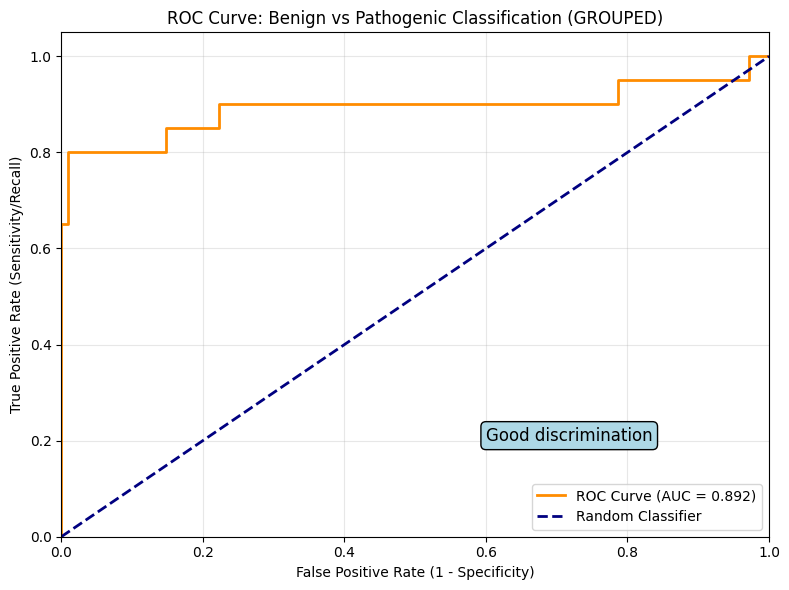


💡 SUMMARY:
   Your model achieves 94.5% accuracy in distinguishing
   between benign and pathogenic variants.
   🎉 This is GOOD performance for clinical genetics!


In [63]:
# Binary Classification Analysis: Benign vs Pathogenic Only
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

print("🎯 GROUPED CLASSIFICATION: BENIGN vs PATHOGENIC ANALYSIS Excluding Normal")
print("="*60)

# Check if we have the grouped data
if 'y_true_grouped_final_data' in locals() and 'y_pred_grouped_final_data' in locals():
    
    # Filter out "Others" category (group 2) - keep only Benign (0) and Pathogenic (1)
    benign_pathogenic_mask = (y_true_grouped_final_data != 2) & (y_pred_grouped_final_data != 2)
    
    # Apply mask to get only Benign vs Pathogenic samples
    y_true_binary = y_true_grouped_final_data[benign_pathogenic_mask]
    y_pred_binary = y_pred_grouped_final_data[benign_pathogenic_mask]
    
    # Get probabilities for binary classification if available
    y_pred_proba_binary = None
    if 'y_pred_proba_grouped' in locals() and y_pred_proba_grouped is not None:
        y_pred_proba_binary_full = y_pred_proba_grouped[benign_pathogenic_mask]
        # Normalize probabilities for just Benign vs Pathogenic (excluding Others)
        prob_sum = y_pred_proba_binary_full[:, 0] + y_pred_proba_binary_full[:, 1]
        # Avoid division by zero
        prob_sum = np.where(prob_sum == 0, 1e-8, prob_sum)
        y_pred_proba_binary = y_pred_proba_binary_full[:, 1] / prob_sum  # Probability of Pathogenic
    
    print(f"📊 Dataset Info:")
    print(f"   Total samples (Benign/Likely Benign vs Pathogenic/Likely Pathogenic): {len(y_true_binary)}")
    print(f"   Benign samples: {np.sum(y_true_binary == 0)}")
    print(f"   Pathogenic samples: {np.sum(y_true_binary == 1)}")
    print(f"   Excluded 'Others' samples: {np.sum(~benign_pathogenic_mask)}")
    
    if len(y_true_binary) > 0 and len(np.unique(y_true_binary)) == 2:
        print("\n📈 PERFORMANCE METRICS:")
        print("-" * 40)
        
        # Calculate core metrics
        accuracy = accuracy_score(y_true_binary, y_pred_binary)
        precision = precision_score(y_true_binary, y_pred_binary, average='binary', pos_label=1)  # Pathogenic as positive
        recall = recall_score(y_true_binary, y_pred_binary, average='binary', pos_label=1)  # Sensitivity
        f1 = f1_score(y_true_binary, y_pred_binary, average='binary', pos_label=1)
        
        # Calculate specificity (True Negative Rate)
        tn, fp, fn, tp = confusion_matrix(y_true_binary, y_pred_binary).ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        
        # Display results
        print(f"✅ Accuracy:    {accuracy:.4f} ({accuracy*100:.2f}%)")
        print(f"🎯 Precision:   {precision:.4f} ({precision*100:.2f}%) - When model says 'Pathogenic', how often is it right?")
        print(f"🔍 Recall:      {recall:.4f} ({recall*100:.2f}%) - How many actual pathogenic variants did we catch?")
        print(f"📊 F1-Score:    {f1:.4f} ({f1*100:.2f}%) - Balanced measure of precision and recall")
        print(f"🛡️  Specificity: {specificity:.4f} ({specificity*100:.2f}%) - How many benign variants did we correctly identify?")
        
        # AUC calculation
        if y_pred_proba_binary is not None:
            try:
                auc_binary = roc_auc_score(y_true_binary, y_pred_proba_binary)
                print(f"📈 AUC:         {auc_binary:.4f} ({auc_binary*100:.2f}%) - Overall discrimination ability")
            except:
                print("📈 AUC:         Could not calculate (insufficient data)")
        
        print("\n🔢 CONFUSION MATRIX:")
        print("-" * 40)
        cm_binary = confusion_matrix(y_true_binary, y_pred_binary)
        print("                 Predicted")
        print("                 Benign  Pathogenic")
        print(f"Actual  Benign    {cm_binary[0,0]:4d}     {cm_binary[0,1]:4d}")
        print(f"     Pathogenic   {cm_binary[1,0]:4d}     {cm_binary[1,1]:4d}")
        
        # Clinical interpretation
        print("\n🏥 CLINICAL INTERPRETATION:")
        print("-" * 40)
        if precision >= 0.90:
            print("🌟 EXCELLENT precision - Very reliable when predicting pathogenic")
        elif precision >= 0.80:
            print("✅ GOOD precision - Reliable for pathogenic predictions")
        elif precision >= 0.70:
            print("⚠️  FAIR precision - Some false positives in pathogenic predictions")
        else:
            print("❌ POOR precision - Many false positives, not reliable for pathogenic calls")
            
        if recall >= 0.90:
            print("🌟 EXCELLENT recall - Catches almost all pathogenic variants")
        elif recall >= 0.80:
            print("✅ GOOD recall - Catches most pathogenic variants")
        elif recall >= 0.70:
            print("⚠️  FAIR recall - Missing some pathogenic variants")
        else:
            print("❌ POOR recall - Missing many pathogenic variants - DANGEROUS for clinical use")
            
        if specificity >= 0.90:
            print("🌟 EXCELLENT specificity - Very good at identifying benign variants")
        elif specificity >= 0.80:
            print("✅ GOOD specificity - Good at identifying benign variants")
        elif specificity >= 0.70:
            print("⚠️  FAIR specificity - Some benign variants misclassified as pathogenic")
        else:
            print("❌ POOR specificity - Many benign variants misclassified as pathogenic")
        
        # Plot ROC curve if probabilities available
        if y_pred_proba_binary is not None:
            plt.figure(figsize=(8, 6))
            fpr, tpr, thresholds = roc_curve(y_true_binary, y_pred_proba_binary)
            auc_score = roc_auc_score(y_true_binary, y_pred_proba_binary)
            
            plt.plot(fpr, tpr, color='darkorange', lw=2, 
                    label=f'ROC Curve (AUC = {auc_score:.3f})')
            plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
                    label='Random Classifier')
            plt.xlim([0.0, 1.0])
            plt.ylim([0.0, 1.05])
            plt.xlabel('False Positive Rate (1 - Specificity)')
            plt.ylabel('True Positive Rate (Sensitivity/Recall)')
            plt.title('ROC Curve: Benign vs Pathogenic Classification (GROUPED)')
            plt.legend(loc="lower right")
            plt.grid(True, alpha=0.3)
            
            # Add interpretation text
            if auc_score >= 0.9:
                interpretation = "Excellent discrimination"
            elif auc_score >= 0.8:
                interpretation = "Good discrimination"
            elif auc_score >= 0.7:
                interpretation = "Fair discrimination"
            else:
                interpretation = "Poor discrimination"
            
            plt.text(0.6, 0.2, f'{interpretation}', fontsize=12, 
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue"))
            
            plt.tight_layout()
            plt.show()
        
        print(f"\n💡 SUMMARY:")
        print(f"   Your model achieves {accuracy*100:.1f}% accuracy in distinguishing")
        print(f"   between benign and pathogenic variants.")
        if f1 >= 0.8:
            print("   🎉 This is GOOD performance for clinical genetics!")
        elif f1 >= 0.7:
            print("   ✅ This is ACCEPTABLE performance for clinical genetics.")
        else:
            print("   ⚠️  This may need improvement for clinical use.")
            
    else:
        print("❌ Insufficient data for binary classification analysis")
        print(f"   Unique classes found: {np.unique(y_true_binary) if len(y_true_binary) > 0 else 'None'}")
        
else:
    print("❌ Required grouped data not available. Please run the grouped analysis first.")

In [114]:
timestamp = time.strftime("_(%Y_%m_%d)_%H|%M")
model_save_path = f"models/model_combined_refined_labels{timestamp}.pt"
torch.save(final_best_model_state_retrain, model_save_path)


### Labeling SNPs that were labeled as uknown signficance!

Loading best model state into final_model...

Isolating and preprocessing samples originally labeled as 0...
Found 507 samples with original label 0.
Identified X3 features (shape: (507, 71)).
Scaling X3 features using 'scaler_x3'.
Shape of preprocessed label 0 tensor: torch.Size([507, 6471])

Classifying the 'label 0' samples...

Plotting classification results for 'label 0' samples...
Applied custom label overrides for plotting and summary.


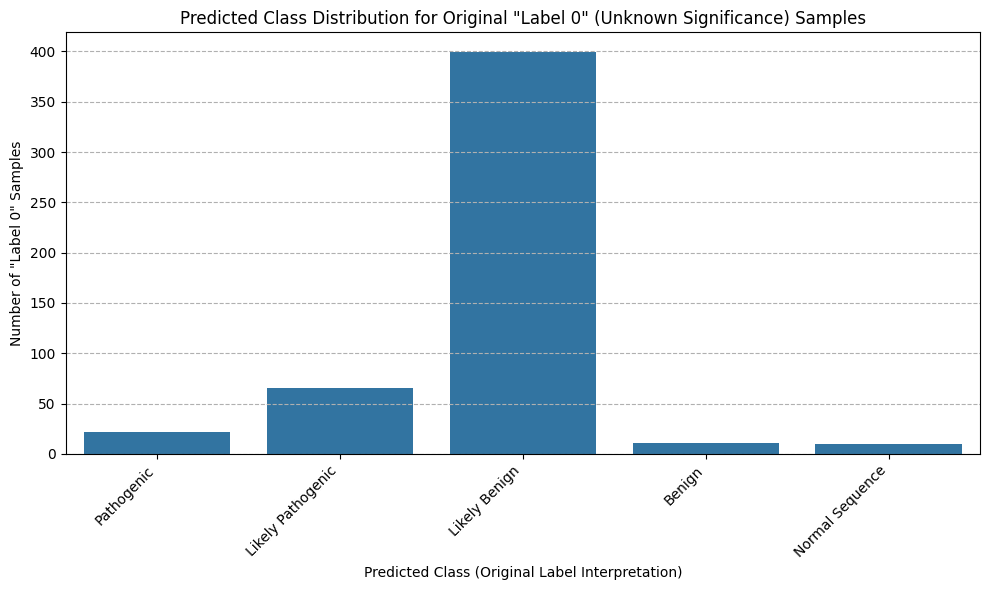


Summary of predictions for 'label 0' samples:
  Predicted as 'Pathogenic' (Original: -2): 22 samples
  Predicted as 'Likely Pathogenic' (Original: -1): 65 samples
  Predicted as 'Likely Benign' (Original: 1): 399 samples
  Predicted as 'Benign' (Original: 2): 11 samples
  Predicted as 'Normal Sequence' (Original: 3): 10 samples


In [64]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm # For progress bar if there are many samples
import gc # Make sure gc is imported for gc.collect()

# --- 1. Ensure Model is Loaded with Best Weights and in Eval Mode ---
if 'final_model' not in locals() or 'final_best_model_state_retrain' not in locals():
    raise NameError("The 'final_model' or 'final_best_model_state_retrain' is not available. Please ensure the model training cell has been run successfully.")

if final_best_model_state_retrain:
    print("Loading best model state into final_model...")
    final_model.load_state_dict(final_best_model_state_retrain)
else:
    print("Warning: final_best_model_state_retrain is None. Using current state of final_model. Ensure it's the desired one.")

if 'device' not in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device not explicitly defined, setting to: {device}")

final_model.to(device)
final_model.eval()

# --- 2. Isolate and Prepare "Label 0" Samples ---
print("\nIsolating and preprocessing samples originally labeled as 0...")

if 'X_fused' not in locals() or 'y_nn_esm2' not in locals():
    raise NameError("Original 'X_fused' or 'y_nn_esm2' data is not available.")
if 'scaler_dna' not in locals() or 'scaler_esm2' not in locals() or 'dna_embedding_dim' not in locals():
    raise NameError("Scalers ('scaler_dna', 'scaler_esm2') or 'dna_embedding_dim' not available.")

label0_indices = np.where(y_nn_esm2 == 0)[0]

if len(label0_indices) == 0:
    print("No samples with original label 0 found.")
else:
    X_label0_original_fused = X_fused[label0_indices]
    print(f"Found {len(X_label0_original_fused)} samples with original label 0.")

    num_esm2_features = scaler_esm2.n_features_in_

    X_label0_dna = X_label0_original_fused[:, :dna_embedding_dim]
    X_label0_esm2 = X_label0_original_fused[:, dna_embedding_dim : dna_embedding_dim + num_esm2_features]

    X_label0_dna_scaled = scaler_dna.transform(X_label0_dna)
    X_label0_esm2_scaled = scaler_esm2.transform(X_label0_esm2)

    scaled_components = [X_label0_dna_scaled, X_label0_esm2_scaled]

    current_features_count = dna_embedding_dim + num_esm2_features
    if 'x3_dim' in locals() and x3_dim > 0:
        expected_total_dim_with_x3 = current_features_count + x3_dim
        if X_label0_original_fused.shape[1] == expected_total_dim_with_x3:
            X_label0_x3 = X_label0_original_fused[:, current_features_count : expected_total_dim_with_x3]
            print(f"Identified X3 features (shape: {X_label0_x3.shape}).")
            if 'scaler_x3' in locals() and scaler_x3 is not None:
                print("Scaling X3 features using 'scaler_x3'.")
                X_label0_x3_scaled = scaler_x3.transform(X_label0_x3)
                scaled_components.append(X_label0_x3_scaled)
            else:
                print("Warning: 'scaler_x3' not found or is None. Using unscaled X3 features. Ensure this is consistent with model training.")
                scaled_components.append(X_label0_x3)
        elif X_label0_original_fused.shape[1] == current_features_count:
            print(f"Warning: x3_dim is {x3_dim}, but X_label0_original_fused only contains DNA and ESM2 features. X3 features will be missing from input if model expects them.")
        else:
            print(f"Warning: Mismatch in feature dimensions for X3. X_label0_original_fused has {X_label0_original_fused.shape[1]} features. Expected DNA ({dna_embedding_dim}) + ESM2 ({num_esm2_features}) and potentially X3 ({x3_dim}).")
    elif X_label0_original_fused.shape[1] > current_features_count:
        print(f"Warning: x3_dim not defined or not positive, but X_label0_original_fused has {X_label0_original_fused.shape[1]} features, more than DNA ({dna_embedding_dim}) + ESM2 ({num_esm2_features}). The additional features are being ignored.")

    X_label0_fused_scaled = np.concatenate(scaled_components, axis=1)
    X_label0_tensor = torch.tensor(X_label0_fused_scaled, dtype=torch.float32).to(device)
    print(f"Shape of preprocessed label 0 tensor: {X_label0_tensor.shape}")

    # --- 3. Perform Classification ---
    print("\nClassifying the 'label 0' samples...")
    predicted_label0_encoded_list = []
    with torch.no_grad():
        outputs_label0 = final_model(X_label0_tensor)
        _, predicted_label0_encoded = torch.max(outputs_label0.data, 1)
        predicted_label0_encoded_list.extend(predicted_label0_encoded.cpu().numpy())

    predicted_label0_encoded_np = np.array(predicted_label0_encoded_list)

    # --- 4. Interpret Predictions ---
    if 'le' not in locals():
        raise NameError("'LabelEncoder' object 'le' is not available.")

    predicted_original_labels_for_label0 = le.inverse_transform(predicted_label0_encoded_np)

    # --- 5. Plot Results ---
    print("\nPlotting classification results for 'label 0' samples...")

    unique_predicted_labels, counts = np.unique(predicted_original_labels_for_label0, return_counts=True)
    predicted_counts_map = dict(zip(unique_predicted_labels, counts))
    known_original_labels = le.classes_

    # Step 1: Establish initial display name map
    if 'target_names_display' in locals() and len(target_names_display) == len(le.classes_):
        current_display_name_map = dict(zip(le.classes_, target_names_display))
    else:
        if 'target_names_display' in locals():
            print("Warning: 'target_names_display' might not be correctly aligned with le.classes_. Using raw original labels as base for display.")
        current_display_name_map = {l: str(l) for l in known_original_labels}

    # Step 2: Define and apply custom overrides
    custom_label_override_map = {
        -2: 'Pathogenic',
        -1: 'Likely Pathogenic',
        1:  'Likely Benign',
        2:  'Benign',
        3:  'Normal Sequence'
    }

    for original_label_val, custom_name in custom_label_override_map.items():
        if original_label_val in current_display_name_map:
            current_display_name_map[original_label_val] = custom_name

    print("Applied custom label overrides for plotting and summary.")

    # Step 3: Generate plot_labels in the correct order from the finalized map
    plot_labels = [current_display_name_map.get(l, str(l)) for l in known_original_labels]
    plot_counts = [predicted_counts_map.get(label, 0) for label in known_original_labels]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=plot_labels, y=plot_counts)
    plt.title('Predicted Class Distribution for Original "Label 0" (Unknown Significance) Samples')
    plt.xlabel('Predicted Class (Original Label Interpretation)')
    plt.ylabel('Number of "Label 0" Samples')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--')
    plt.tight_layout()
    plt.show()

    print("\nSummary of predictions for 'label 0' samples:")
    for i, original_label_val in enumerate(known_original_labels):
        display_name = plot_labels[i]
        count = plot_counts[i]
        print(f"  Predicted as '{display_name}' (Original: {original_label_val}): {count} samples")


In [32]:
import os

import pandas as pd # Ensure pandas is imported if not already
import torch # Ensure torch is imported if not already

# --- 1. Ensure all required variables are available ---
# predictions: predicted_original_labels_for_label0 (array of predicted labels for label 0 samples)
# label0_indices: indices of label 0 samples in the original dataset
# df_processed or the original dataframe: contains snp_id and other columns

if 'predicted_original_labels_for_label0' not in locals():
    raise NameError("predicted_original_labels_for_label0 not found. Run the prediction cell for label 0 samples.")
if 'label0_indices' not in locals():
    raise NameError("label0_indices not found. This should be the indices of label 0 samples in the original data.")
if 'df_processed' not in locals():
    # Attempt to load df_processed if it's a common name for the processed dataframe
    # This is a fallback, ideally it's already loaded and named df_processed
    if 'df' in locals(): # A common default dataframe name
        print("Warning: 'df_processed' not found, using 'df' instead. Ensure this is the correct dataframe.")
        df_processed = df
    else:
        raise NameError("df_processed (or a suitable original dataframe) not found. This should be your original dataframe with snp_id and other columns.")

# --- 2. Extract the relevant rows from the original dataframe ---
# Ensure df_processed is a pandas DataFrame
if not isinstance(df_processed, pd.DataFrame):
    raise TypeError("df_processed is not a pandas DataFrame.")

df_label0 = df_processed.iloc[label0_indices].copy()

# --- 3. Add predictions to the dataframe ---
df_label0['Predicted_Label'] = predicted_original_labels_for_label0

# Define the custom mapping for descriptive names, similar to what's used in other cells
# This map provides the most descriptive terms.
custom_label_override_map = {
    -3: 'Highly Pathogenic', # Example if -3 is used and needs a specific name
    -2: 'Pathogenic',
    -1: 'Likely Pathogenic',
    1:  'Likely Benign',
    2:  'Benign',
    3:  'Normal Sequence'
    # Add other mappings if necessary based on your le.classes_
}

final_label_display_map = {}
if 'le' in locals() and hasattr(le, 'classes_'):
    # Prepare a base map from target_names_display if it's valid
    base_display_map_from_target_names = {}
    if 'target_names_display' in locals() and len(target_names_display) == len(le.classes_):
        base_display_map_from_target_names = dict(zip(le.classes_, target_names_display))
    else:
        if 'target_names_display' in locals(): # It exists but is misaligned
            print("Warning: 'target_names_display' is present but misaligned with 'le.classes_'. It will not be used as the primary source for non-custom mapped labels.")

    for original_label_val in le.classes_:
        if original_label_val in custom_label_override_map:
            final_label_display_map[original_label_val] = custom_label_override_map[original_label_val]
        elif original_label_val in base_display_map_from_target_names: # Fallback to target_names_display
            final_label_display_map[original_label_val] = base_display_map_from_target_names[original_label_val]
        else: # Fallback to string representation of the label
            final_label_display_map[original_label_val] = str(original_label_val)
            
    df_label0['Predicted_Label_Display'] = df_label0['Predicted_Label'].map(final_label_display_map)
    
    
elif len(custom_label_override_map) > 0:
    print("Warning: 'le' or 'le.classes_' not found. Attempting to map 'Predicted_Label' directly using 'custom_label_override_map'.")
    df_label0['Predicted_Label_Display'] = df_label0['Predicted_Label'].map(custom_label_override_map)
    if df_label0['Predicted_Label_Display'].isnull().any():
        unmapped_labels = df_label0[df_label0['Predicted_Label_Display'].isnull()]['Predicted_Label'].unique()
        print(f"Warning: Some predicted labels could not be mapped using only 'custom_label_override_map': {unmapped_labels}.")
        df_label0['Predicted_Label_Display'].fillna(df_label0['Predicted_Label'].astype(str), inplace=True)
else:
    print("Warning: Could not map predicted labels to display names. 'le' (LabelEncoder) is missing or 'custom_label_override_map' is empty. 'Predicted_Label_Display' will contain stringified original labels.")
    df_label0['Predicted_Label_Display'] = df_label0['Predicted_Label'].astype(str)


# --- 4. Add prediction confidence ---
if 'outputs_label0' in locals():
    if isinstance(outputs_label0, torch.Tensor):
        import torch.nn.functional as F
        # Get softmax probabilities
        with torch.no_grad(): # Ensure no gradient calculations
            probs = F.softmax(outputs_label0, dim=1).cpu().numpy()
        max_probs = probs.max(axis=1)
        df_label0['Prediction_Confidence'] = max_probs
    else:
        print("Warning: 'outputs_label0' is not a PyTorch Tensor. Cannot calculate prediction confidence.")
else:
    print("Warning: 'outputs_label0' not found. Cannot calculate prediction confidence.")

# --- 5. Select columns to export ---
# Define a base set of columns you expect from df_processed
# Adjust these based on the actual columns in your df_processed
expected_original_cols = ['snp_id', 'protein_sequence', 'variant_type', 'pos', 'gene','original','mutant'] 
# Filter to only include columns that actually exist in df_label0 (derived from df_processed)
columns_to_export = [col for col in expected_original_cols if col in df_label0.columns]

# Add the newly created prediction columns
columns_to_export.append('Predicted_Label')
if 'Predicted_Label_Display' in df_label0.columns:
    columns_to_export.append('Predicted_Label_Display')
if 'Prediction_Confidence' in df_label0.columns:
    columns_to_export.append('Prediction_Confidence')

# Ensure no duplicate columns and maintain order
final_columns_to_export = []
for col in columns_to_export:
    if col not in final_columns_to_export:
        final_columns_to_export.append(col)

# --- 6. Export to CSV ---
# Ensure the results directory exists
results_dir = "results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)
    print(f"Created directory: {results_dir}")

export_path = os.path.join(results_dir, "predictions_label0_with_details.csv")

try:
    df_label0_export = df_label0[final_columns_to_export]
    df_label0_export.to_csv(export_path, index=False)
    print(f"Exported label 0 predictions with details to: {export_path}")
    print(f"Columns exported: {df_label0_export.columns.tolist()}")
except KeyError as e:
    print(f"KeyError during export: {e}. One or more columns in 'final_columns_to_export' not found in df_label0.")
    print(f"Available columns in df_label0: {df_label0.columns.tolist()}")
    print(f"Attempted to export: {final_columns_to_export}")
    # Fallback: export all columns of df_label0
    fallback_export_path = os.path.join(results_dir, "predictions_label0_ALL_COLUMNS.csv")
    df_label0.to_csv(fallback_export_path, index=False)
    print(f"As a fallback, all columns of df_label0 exported to: {fallback_export_path}")

# Display the first few rows of the dataframe that was prepared for export
if 'df_label0_export' in locals():
    print("\nFirst 5 rows of the exported data:")
    print(df_label0_export.head())
elif 'df_label0' in locals() and final_columns_to_export:
     print("\nFirst 5 rows of the data intended for export (some columns might have been missed due to KeyError):")
     print(df_label0[[col for col in final_columns_to_export if col in df_label0.columns]].head())

Exported label 0 predictions with details to: results/predictions_label0_with_details.csv
Columns exported: ['snp_id', 'protein_sequence', 'variant_type', 'pos', 'gene', 'original', 'mutant', 'Predicted_Label', 'Predicted_Label_Display', 'Prediction_Confidence']

First 5 rows of the exported data:
           snp_id                                   protein_sequence  \
60509   981661701  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
2275   1224037200  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   
58973   928718259  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
35241  1694921931  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
22120   999691354  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   

      variant_type        pos     gene original mutant  Predicted_Label  \
60509          snv  227709289  SLC19A3        C      C                3   
2275        delins  169472362  SLC19A2     AAAG   AAAG                3   
58973          snv  227686832  SLC19A3     

In [33]:

def map_labels_to_descriptive_terms(df, Predicted_Label_Display):
    for index, row in df.iterrows():
        the_thing_to_be_changed = row[Predicted_Label_Display] 
        if the_thing_to_be_changed == 'Neg Med (-2)':
            df.at[index, 'Predicted_Label_Display'] = 'Pathogenic'
        elif the_thing_to_be_changed == 'Neg Low (-1)':
            df.at[index, 'Predicted_Label_Display'] = 'Likely Pathogenic'
        elif the_thing_to_be_changed == 'Pos Low (1)':
            df.at[index, 'Predicted_Label_Display'] = 'Likely Benign'
        elif the_thing_to_be_changed == 'Pos Med (2)':
            df.at[index, 'Predicted_Label_Display'] = 'Benign'
        elif the_thing_to_be_changed == 'Pos High (3)':
            df.at[index, 'Predicted_Label_Display'] = 'Normal'
    return df

df_label0_export = map_labels_to_descriptive_terms(df_label0_export, 'Predicted_Label_Display')
df_label0_export.to_csv(export_path, index=False)


#### It looks like vast majoriy of uknonwn signficance ones are likely benign!

## Predicting

### Loading Final Model

In [62]:
import torch
import torch.nn as nn
import numpy as np # Only if best_params or other necessary vars are numpy types

# --- 1. Define Model Architecture ---
# This MUST be the EXACT same architecture as used during the training
# (defined in cell "6b612d9c" or similar)
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512, 256], output_dim=6, dropout_rate=0.4, activation_fn=nn.ReLU):
        super(SimpleClassifier, self).__init__()
        layers = []
        current_dim = input_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(current_dim, h_dim),
                nn.BatchNorm1d(h_dim), # Assuming BatchNorm was used as per cell 6b612d9c
                activation_fn(),
                nn.Dropout(dropout_rate)
            ])
            current_dim = h_dim
        layers.append(nn.Linear(current_dim, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# --- 2. Ensure Necessary Parameters from Training are Available ---
# These variables MUST be loaded or available in the current scope from your training script (e.g., cell id="6b612d9c").
#
# - fused_input_dim: (integer) The shape[1] of your scaled and fused training data.
#                    This is the input_dim for the model.
# - num_classes: (integer) The number of unique classes the model predicts.
# - best_params: (dict) Dictionary containing hyperparameters:
#   - 'hidden_dims': list of integers
#   - 'dropout_rate': float
#   - 'activation_fn': string (e.g., 'ReLU', 'LeakyReLU')
# - final_best_model_state_retrain: The PyTorch state_dict object of the saved model.
# - device: The torch.device object.

print("Checking for required variables from the training environment...")
required_for_loading = ['fused_input_dim', 'num_classes', 'best_params', 'final_best_model_state_retrain']
for var_name in required_for_loading:
    if var_name not in locals():
        raise NameError(
            f"Variable '{var_name}' is not defined. "
            f"This variable is essential for loading the model and must be available from your "
            f"training script (e.g., from cell '6b612d9c' or loaded from a file)."
        )
if 'device' not in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device not explicitly defined, setting to: {device}")
else:
    print(f"Using existing device: {device}")

print(f"Using fused_input_dim: {fused_input_dim}")
print(f"Using num_classes: {num_classes}")
print(f"Using best_params: {best_params}")


# --- 3. Instantiate the Model with Parameters from Training ---
print("\nInstantiating model with parameters from training...")

# Map activation function string from best_params to nn.Module
act_fn_map = {'ReLU': nn.ReLU, 'LeakyReLU': nn.LeakyReLU, 'GELU': nn.GELU}
loaded_activation_fn_name = best_params.get('activation_fn', 'ReLU') # Default to ReLU if not in best_params
loaded_activation_fn = act_fn_map.get(loaded_activation_fn_name, nn.ReLU)
print(f"Using Activation Function: {loaded_activation_fn_name}")

# Instantiate the model with the same parameters used during the training that produced 'final_best_model_state_retrain'
loaded_model = SimpleClassifier(
    input_dim=fused_input_dim,
    hidden_dims=best_params['hidden_dims'],
    output_dim=num_classes,
    dropout_rate=best_params['dropout_rate'],
    activation_fn=loaded_activation_fn
)
print("Model instantiated.")

# --- 4. Load the Saved State Dictionary ---
print("\nLoading saved model state dictionary (final_best_model_state_retrain)...")
try:
    loaded_model.load_state_dict(final_best_model_state_retrain)
    print("Model state loaded successfully.")
except RuntimeError as e:
    print(f"RuntimeError loading state_dict: {e}")
    print("This often means the model architecture defined here (SimpleClassifier) or the parameters "
          "(fused_input_dim, hidden_dims, num_classes, dropout_rate, activation_fn) "
          "do not EXACTLY match the architecture and parameters used when 'final_best_model_state_retrain' was saved.")
    print("Please double-check these against cell '6b612d9c'.")
    raise
except FileNotFoundError:
    # This case is if final_best_model_state_retrain was a path string and file not found
    print(f"Error: The variable 'final_best_model_state_retrain' might be a path, and the file was not found.")
    print("Ensure 'final_best_model_state_retrain' contains the actual state dictionary, not a path to it, "
          "OR if it's a path, ensure the file exists and load it first (e.g., torch.load(path)).")
    raise
except Exception as e:
    print(f"An unexpected error occurred while loading the model state: {e}")
    raise

# --- 5. Set Model to Evaluation Mode and Move to Device ---
loaded_model.to(device)
loaded_model.eval()
print(f"Model moved to device '{device}' and set to evaluation mode (loaded_model.eval()).")

# The 'loaded_model' is now ready for inference.
# You can use it for predictions. If you want to use the name 'final_model':
# final_model_loaded = loaded_model
# print("\nThe loaded model is now also available as 'final_model_loaded'.")

Checking for required variables from the training environment...
Using existing device: cuda
Using fused_input_dim: 6471
Using num_classes: 5
Using best_params: {'activation_fn': 'ReLU', 'batch_size': 128, 'cb_beta': 0.9999, 'dropout_rate': 0.3, 'hidden_dims': [2048, 1024, 512], 'imbalance_strategy': 'ClassBalancedCE', 'label_smoothing': 0.0, 'lr': 5e-05, 'optimizer': 'AdamW', 'weight_decay': 0.01}

Instantiating model with parameters from training...
Using Activation Function: ReLU
Model instantiated.

Loading saved model state dictionary (final_best_model_state_retrain)...
Model state loaded successfully.
Model moved to device 'cuda' and set to evaluation mode (loaded_model.eval()).


In [89]:
X_fused.shape

(23654, 6471)

In [56]:
import torch
import torch.nn as nn

model_path = "models/final_model_slc19a31748337145.pt"
state_dict = torch.load(model_path, map_location="cpu")
final_model.load_state_dict(state_dict)
final_model.eval()
print(f"Model loaded from {model_path}")

Model loaded from models/final_model_slc19a31748337145.pt


### Predicting

Loading best model state into final_model...

Preprocessing all samples from X_fused for prediction...
Found 31199 samples in X_fused to process.
Processed DNA part with 3840 features for all samples.
Processed ESM-2 part with 2560 features for all samples.
Processed X3 part with 71 features for all samples.
Shape of preprocessed tensor for prediction: torch.Size([31199, 6471])

Classifying samples and calculating probabilities...

Plotting predicted class distribution for all processed samples...
Applied custom label overrides for plotting.


/tmp/ipykernel_46872/3123390383.py:163: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plot_labels_display_names, y=plot_counts, palette="viridis")


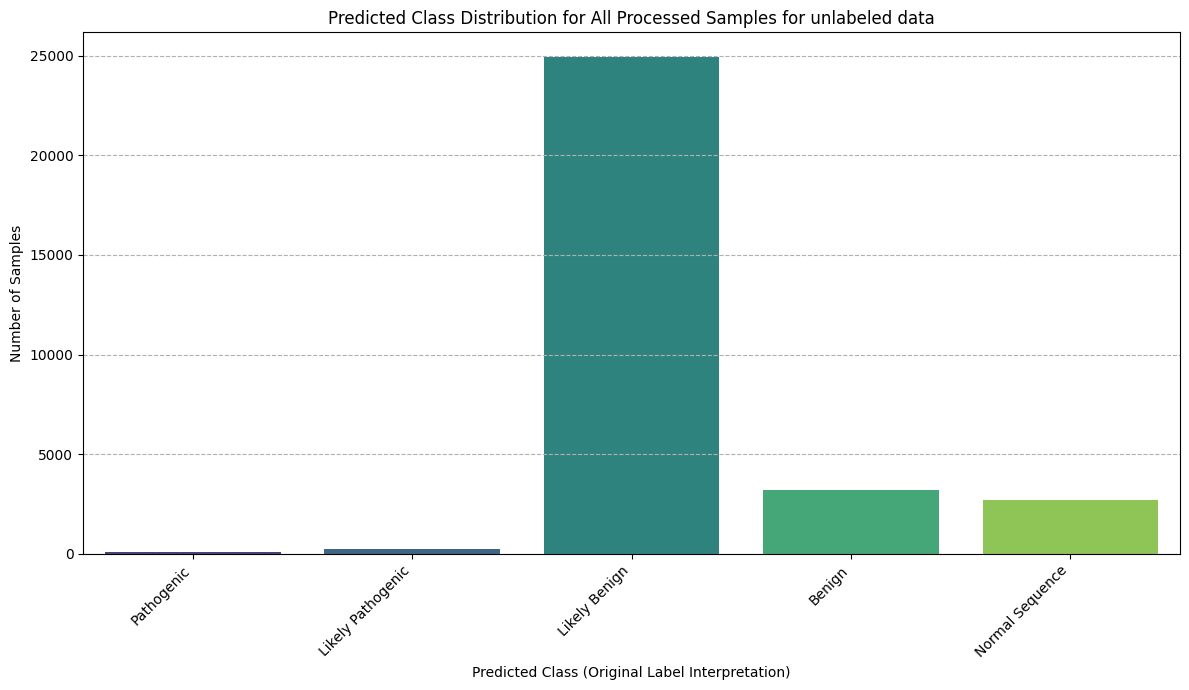


Summary of predictions for all processed samples:
    Predicted as 'Pathogenic' (Original value: -2): 113 samples
    Predicted as 'Likely Pathogenic' (Original value: -1): 244 samples
    Predicted as 'Likely Benign' (Original value: 1): 24926 samples
    Predicted as 'Benign' (Original value: 2): 3195 samples
    Predicted as 'Normal Sequence' (Original value: 3): 2721 samples

Plotting probability score distributions for each predicted class...


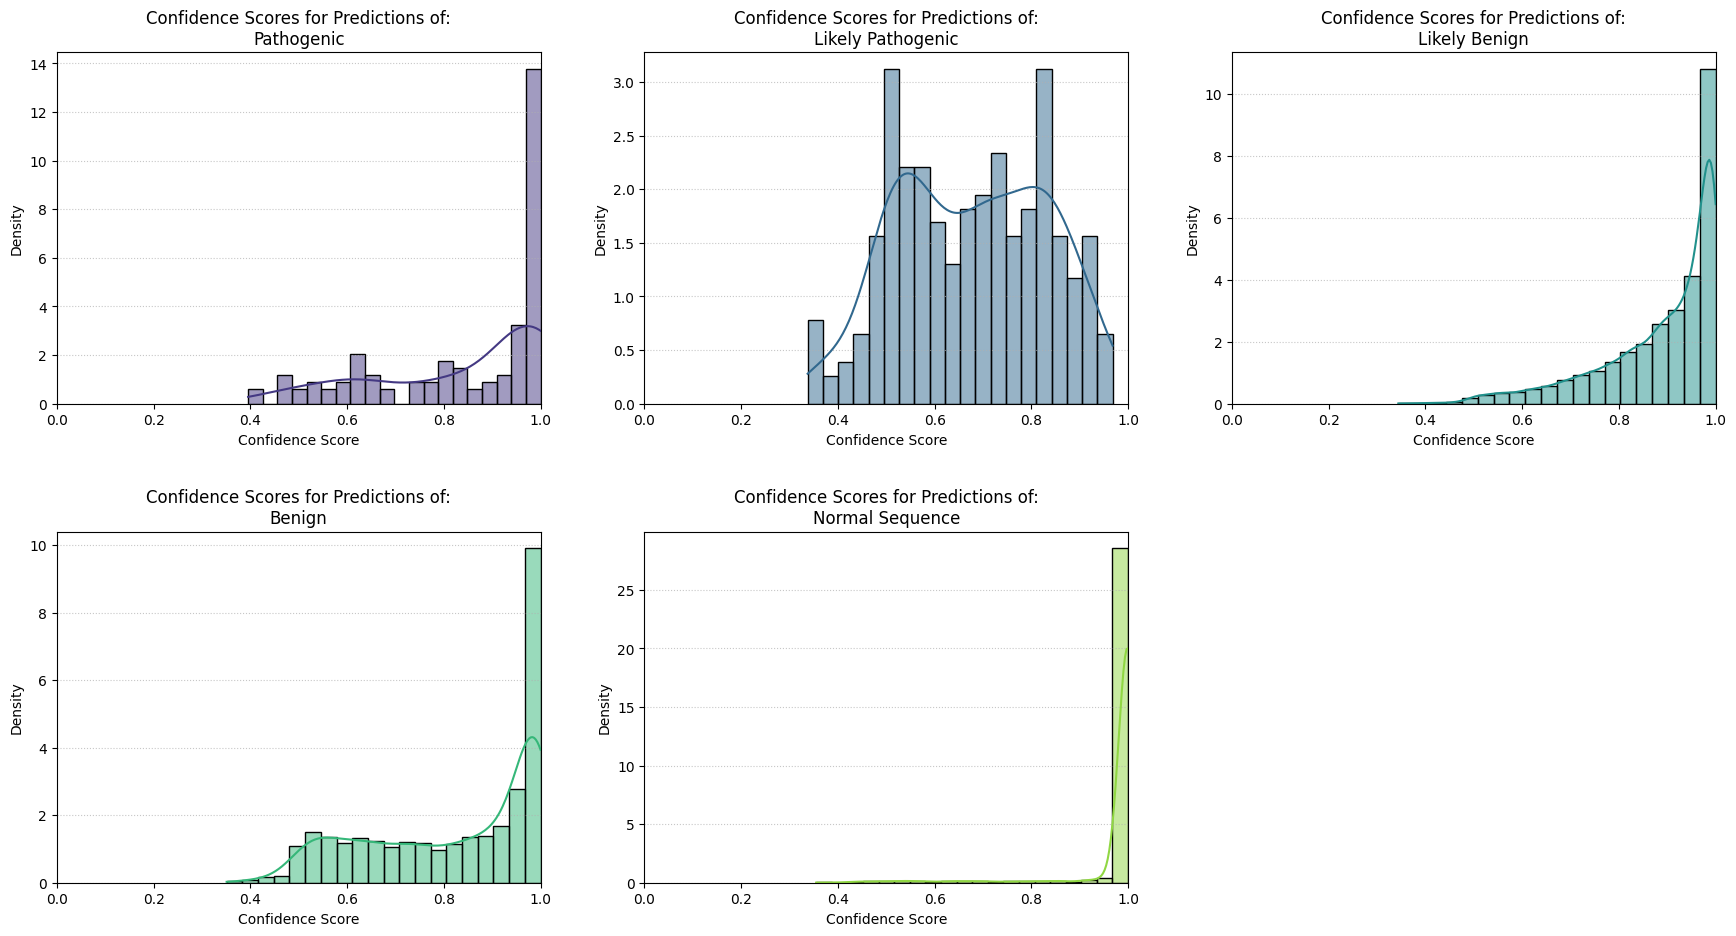


--- Prediction and Probability Plotting Complete ---


In [34]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import gc

# --- 1. Ensure Model is Loaded ---
if 'final_model' not in locals() or 'final_best_model_state_retrain' not in locals():
    raise NameError("The 'final_model' or 'final_best_model_state_retrain' is not available.")

if final_best_model_state_retrain:
    print("Loading best model state into final_model...")
    final_model.load_state_dict(final_best_model_state_retrain)
else:
    print("Warning: final_best_model_state_retrain is None.")

if 'device' not in locals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device not found, setting to: {device}")

final_model.to(device)
final_model.eval()

# --- 2. Prepare All Samples for Prediction ---
print("\nPreprocessing all samples from X_fused for prediction...")

if 'X_fused' not in locals():
    raise NameError("Original 'X_fused' data is not available.")
if 'scaler_dna' not in locals() or 'scaler_esm2' not in locals():
    raise NameError("Scalers ('scaler_dna', 'scaler_esm2') not available.")

X_to_predict_original_fused = X_fused
print(f"Found {len(X_to_predict_original_fused)} samples in X_fused to process.")

# Get dimensions directly from scalers
dim_dna = scaler_dna.n_features_in_
dim_esm2 = scaler_esm2.n_features_in_

scaled_components_all = []
current_start_index_all = 0

# DNA part
if X_to_predict_original_fused.shape[1] >= current_start_index_all + dim_dna:
    X_to_predict_dna = X_to_predict_original_fused[:, current_start_index_all : current_start_index_all + dim_dna]
    X_to_predict_dna_scaled = scaler_dna.transform(X_to_predict_dna)
    scaled_components_all.append(X_to_predict_dna_scaled)
    current_start_index_all += dim_dna
    print(f"Processed DNA part with {dim_dna} features for all samples.")
else:
    raise ValueError(f"X_to_predict_original_fused is too narrow for DNA features. Expected at least {dim_dna}, got {X_to_predict_original_fused.shape[1]}.")

# ESM-2 part
if X_to_predict_original_fused.shape[1] >= current_start_index_all + dim_esm2:
    X_to_predict_esm2 = X_to_predict_original_fused[:, current_start_index_all : current_start_index_all + dim_esm2]
    X_to_predict_esm2_scaled = scaler_esm2.transform(X_to_predict_esm2)
    scaled_components_all.append(X_to_predict_esm2_scaled)
    current_start_index_all += dim_esm2
    print(f"Processed ESM-2 part with {dim_esm2} features for all samples.")
else:
    raise ValueError(f"X_to_predict_original_fused is too narrow for ESM-2 features. Expected at least {current_start_index_all + dim_esm2} total, got {X_to_predict_original_fused.shape[1]}.")

# X3 part (optional)
if 'scaler_x3' in locals() and scaler_x3 is not None:
    dim_x3 = scaler_x3.n_features_in_
    if X_to_predict_original_fused.shape[1] >= current_start_index_all + dim_x3:
        X_to_predict_x3 = X_to_predict_original_fused[:, current_start_index_all : current_start_index_all + dim_x3]
        X_to_predict_x3_scaled = scaler_x3.transform(X_to_predict_x3)
        scaled_components_all.append(X_to_predict_x3_scaled)
        current_start_index_all += dim_x3
        print(f"Processed X3 part with {dim_x3} features for all samples.")
    else:
        print(f"CRITICAL WARNING: scaler_x3 exists, but X_to_predict_original_fused is too narrow for X3 features. Expected at least {current_start_index_all + dim_x3} total, got {X_to_predict_original_fused.shape[1]}.")
        print("Predictions might be incorrect if the model expects X3 features.")
elif X_to_predict_original_fused.shape[1] > current_start_index_all:
    print(f"Warning: X_to_predict_original_fused has {X_to_predict_original_fused.shape[1] - current_start_index_all} additional features, but 'scaler_x3' is not available or not used. These features are being ignored.")

X_to_predict_fused_scaled = np.concatenate(scaled_components_all, axis=1)

if 'fused_input_dim' in locals():
    if X_to_predict_fused_scaled.shape[1] != fused_input_dim:
        print(f"CRITICAL WARNING: Final preprocessed data for ALL samples has {X_to_predict_fused_scaled.shape[1]} features, "
              f"but the model was trained on {fused_input_dim} features.")
else:
    print("Warning: 'fused_input_dim' not found. Cannot verify final feature dimension for ALL samples.")
    
X_to_predict_tensor = torch.tensor(X_to_predict_fused_scaled, dtype=torch.float32).to(device)
print(f"Shape of preprocessed tensor for prediction: {X_to_predict_tensor.shape}")

# --- 3. Perform Classification and Get Probabilities ---
print("\nClassifying samples and calculating probabilities...")
predicted_encoded_labels_list = []
predicted_probabilities_list = []

with torch.no_grad():
    # Consider batching if X_to_predict_tensor is very large
    # For now, assuming it fits in memory for a single pass
    outputs_all = final_model(X_to_predict_tensor)
    probabilities_all = F.softmax(outputs_all, dim=1)
    max_probabilities, predicted_encoded_labels = torch.max(probabilities_all, 1)
    
    predicted_encoded_labels_list.extend(predicted_encoded_labels.cpu().numpy())
    predicted_probabilities_list.extend(max_probabilities.cpu().numpy())

predicted_encoded_labels_np = np.array(predicted_encoded_labels_list)
predicted_max_probs_np = np.array(predicted_probabilities_list)

# --- 4. Interpret Predictions ---
if 'le' not in locals():
    raise NameError("'LabelEncoder' object 'le' is not available.")
predicted_original_labels_all = le.inverse_transform(predicted_encoded_labels_np)

# --- 5. Plot Predicted Class Distribution ---
print("\nPlotting predicted class distribution for all processed samples...")
unique_predicted_labels, counts = np.unique(predicted_original_labels_all, return_counts=True)
predicted_counts_map = dict(zip(unique_predicted_labels, counts))
known_original_labels = le.classes_

# Initial setup of original_to_display_name_map and plot_labels_display_names
if 'target_names_display' not in locals() or len(target_names_display) != len(le.classes_):
    print("Warning: 'target_names_display' might not be correctly aligned. Using raw original labels for plot.")
    # This map will hold default names, e.g., {-2: "-2"}
    original_to_display_name_map = {l: str(l) for l in known_original_labels}
else:
    # This map will hold names from target_names_display, e.g., {-2: "Neg Med (-2)"}
    original_to_display_name_map = dict(zip(le.classes_, target_names_display))

### START MODIFICATION ###
# Define your custom label overrides
custom_label_override_map = {
    -2: 'Pathogenic',
    -1: 'Likely Pathogenic',
    1:  'Likely Benign',
    2:  'Benign',
    3:  'Normal Sequence'
    # Any original labels in le.classes_ not listed here (e.g., -3)
    # will retain their names from the original_to_display_name_map setup above.
}

# Create a new map that incorporates the overrides
updated_original_to_display_name_map = {}
for original_label_val in known_original_labels: # known_original_labels is le.classes_
    # Get the default name established above
    default_name = original_to_display_name_map.get(original_label_val, str(original_label_val))
    # Apply override if it exists for this original_label_val, otherwise use default
    final_name = custom_label_override_map.get(original_label_val, default_name)
    updated_original_to_display_name_map[original_label_val] = final_name

# Update the main map variable used by subsequent plotting code
original_to_display_name_map = updated_original_to_display_name_map

# Regenerate plot_labels_display_names based on the updated map,
# ensuring the order matches known_original_labels for the bar plot.
plot_labels_display_names = [original_to_display_name_map.get(l, str(l)) for l in known_original_labels]
print("Applied custom label overrides for plotting.")
### END MODIFICATION ###

plot_counts = [predicted_counts_map.get(label, 0) for label in known_original_labels]

plt.figure(figsize=(12, 7))
# sns.barplot will now use the updated plot_labels_display_names
sns.barplot(x=plot_labels_display_names, y=plot_counts, palette="viridis")
plt.title('Predicted Class Distribution for All Processed Samples for unlabeled data')
plt.xlabel('Predicted Class (Original Label Interpretation)')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

print("\nSummary of predictions for all processed samples:")
for i, original_label_val in enumerate(known_original_labels):
    # display_name will come from the updated plot_labels_display_names
    display_name = plot_labels_display_names[i]
    count = plot_counts[i]
    print(f"    Predicted as '{display_name}' (Original value: {original_label_val}): {count} samples")

# --- 6. Plot Probability Score Distributions ---
print("\nPlotting probability score distributions for each predicted class...")
num_known_classes = len(known_original_labels)
if num_known_classes > 0:
    ncols_prob = 3 if num_known_classes > 2 else num_known_classes
    nrows_prob = (num_known_classes + ncols_prob - 1) // ncols_prob
    fig_prob, axes_prob = plt.subplots(nrows_prob, ncols_prob, figsize=(6 * ncols_prob, 5 * nrows_prob), squeeze=False)
    axes_prob_flat = axes_prob.flatten()
    for i, original_label_val_iter in enumerate(known_original_labels):
        # current_display_name will be fetched from the updated original_to_display_name_map
        current_display_name = original_to_display_name_map.get(original_label_val_iter, str(original_label_val_iter))
        try:
            encoded_equivalent_for_iter = le.transform([original_label_val_iter])[0]
            scores_for_this_predicted_class = predicted_max_probs_np[predicted_encoded_labels_np == encoded_equivalent_for_iter]
        except ValueError:
            scores_for_this_predicted_class = np.array([])
            print(f"Warning: Could not find encoded equivalent for {original_label_val_iter} during probability plotting.")
        ax = axes_prob_flat[i]
        if len(scores_for_this_predicted_class) > 0:
            sns.histplot(scores_for_this_predicted_class, ax=ax, kde=True, bins=20, stat="density", color=sns.color_palette("viridis", num_known_classes)[i])
            # Titles will use the updated current_display_name
            ax.set_title(f'Confidence Scores for Predictions of:\n{current_display_name}')
            ax.set_ylabel('Density'); ax.set_xlabel('Confidence Score'); ax.set_xlim(0, 1)
            ax.grid(axis='y', linestyle=':', alpha=0.7)
        else:
            # Text in empty plots will also use the updated current_display_name
            ax.text(0.5, 0.5, f'No samples predicted as\n{current_display_name}', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.set_title(f'Confidence Scores for Predictions of:\n{current_display_name}')
            ax.set_xlabel('Confidence Score'); ax.set_ylabel('Density'); ax.set_xlim(0, 1)
    for j in range(num_known_classes, len(axes_prob_flat)):
        fig_prob.delaxes(axes_prob_flat[j])
    plt.tight_layout(pad=3.0); plt.show()
else:
    print("No known classes to plot probability distributions for.")

# ... (rest of the script from line 4181 onwards) ...
print("\n--- Prediction and Probability Plotting Complete ---")


In [35]:
if len(df_test) != len(predicted_original_labels_all):
    raise ValueError(f"Mismatch in lengths! df_test has {len(df_test)} rows, "
                     f"but there are {len(predicted_original_labels_all)} predictions. "
                     "Ensure df_test corresponds to the data used for X_fused.")

print(f"Length of df_test: {len(df_test)}")
print(f"Number of predictions: {len(predicted_original_labels_all)}")
print(f"Number of probability scores: {len(predicted_max_probs_np)}")

# --- 2. Create the New DataFrame with Selected Columns ---
# Define the columns you want to pull from df_test
# Using 'variant_types' as it appears in your example df_test head for 'variant_type'
# Using 'chrposvariation' for 'pos' as a specific 'pos' column is not shown
columns_from_df_test = {
    'snp_id': 'snp_id',
    'protein_sequence': 'protein_sequence',
    'variant_type': 'variant_type', # Mapping user's request 'variant_type' to 'variant_types'
    'position': 'pos',   # Mapping user's request 'pos' to 'chrposvariation'
    'gene': 'gene',
    'original': 'original',  # Assuming 'original' is a column in df_test
    'mutant': 'mutant',
    'frequency': 'frequency',
    'function_class': 'function_class',  # Assuming 'function_class' is a column in df_test
}

# Check if all required columns exist in df_test
missing_cols = [col for col in columns_from_df_test.values() if col not in df_test.columns]
if missing_cols:
    raise KeyError(f"The following required columns are missing from df_test: {missing_cols}")

# Create the new DataFrame by selecting and renaming columns
predictions_df = df_test[list(columns_from_df_test.values())].copy()
predictions_df.rename(columns={v: k for k, v in columns_from_df_test.items()}, inplace=True)


# --- 3. Add Prediction and Probability Columns ---

predictions_df['Predicted_Label_Original'] = predicted_original_labels_all
predictions_df['Prediction_Confidence'] = predicted_max_probs_np

# --- 4. (Optional) Map Predicted Original Labels to Display Names ---
# If you have 'le' (LabelEncoder) and 'target_names_display' or 'class_names_map'
# from your training/previous prediction script, you can add a column with human-readable names.

if 'le' in locals() and ('target_names_display' in locals() or 'class_names_map' in locals()):
    # Ensure le.classes_ are the original values like -3, -2, 1, 2, 3
    # Ensure target_names_display corresponds to these le.classes_
    
    # Option 1: Using target_names_display (if it's aligned with le.classes_)
    if 'target_names_display' in locals() and len(le.classes_) == len(target_names_display):
        original_to_display_map_for_pred = dict(zip(le.classes_, target_names_display))
        predictions_df['Predicted_Label_Display'] = predictions_df['Predicted_Label_Original'].map(original_to_display_map_for_pred)
        print("Added 'Predicted_Label_Display' using 'target_names_display'.")
    
    # Option 2: Using class_names_map (if you have it and it maps original labels to names)
    elif 'class_names_map' in locals():
        # class_names_map = {-3: 'Neg High (-3)', -2: 'Neg Med (-2)', ...}
        predictions_df['Predicted_Label_Display'] = predictions_df['Predicted_Label_Original'].map(class_names_map)
        print("Added 'Predicted_Label_Display' using 'class_names_map'.")
    else:
        print("Could not map predicted labels to display names as 'target_names_display' or 'class_names_map' alignment is unclear.")
else:
    print("Skipping mapping of predicted labels to display names as 'le', 'target_names_display', or 'class_names_map' is not available.")

# --- START MODIFICATION: Apply custom descriptive term mapping ---
if 'Predicted_Label_Display' in predictions_df.columns:
    print("\nApplying custom descriptive term mapping to 'Predicted_Label_Display'...")

    def map_labels_to_descriptive_terms(df, column_name_to_map):
        

        for index, row in df.iterrows(): # Iterate over the original df
            current_display_label = row[column_name_to_map]
            if current_display_label == 'Neg Med (-2)':
                df.loc[index, column_name_to_map] = 'Pathogenic'
            elif current_display_label == 'Neg Low (-1)':
                df.loc[index, column_name_to_map] = 'Likely Pathogenic'
            elif current_display_label == 'Pos Low (1)':
                df.loc[index, column_name_to_map] = 'Likely Benign'
            elif current_display_label == 'Pos Med (2)':
                df.loc[index, column_name_to_map] = 'Benign'
            elif current_display_label == 'Pos High (3)':
                df.loc[index, column_name_to_map] = 'Normal'
            # Example for 'Neg High (-3)' if it's part of your target_names_display
            # and you want to map it:
            # elif current_display_label == 'Neg High (-3)':
            #     df.loc[index, column_name_to_map] = 'Highly Pathogenic' # Or other term
        return df # Return the modified DataFrame

    predictions_df = map_labels_to_descriptive_terms(predictions_df, 'Predicted_Label_Display')
    print("Custom descriptive term mapping applied to 'Predicted_Label_Display'.")
else:
    print("\nSkipping custom descriptive term mapping as 'Predicted_Label_Display' column does not exist or was not created.")
# --- END MODIFICATION ---

# --- 5. Display the Head of the New DataFrame ---
print("\nHead of the new predictions DataFrame:")
print(predictions_df.head())

# --- 6. Display Info about the New DataFrame ---
print("\nInfo for the new predictions DataFrame:")
predictions_df.info()

Length of df_test: 31199
Number of predictions: 31199
Number of probability scores: 31199
Added 'Predicted_Label_Display' using 'target_names_display'.

Applying custom descriptive term mapping to 'Predicted_Label_Display'...
Custom descriptive term mapping applied to 'Predicted_Label_Display'.

Head of the new predictions DataFrame:
           snp_id                                   protein_sequence  \
48753  2470589170  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
8415   1657983707  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   
1912   1204771673  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   
60889   994227826  MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNL...   
21890   984063949  MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASL...   

      variant_type   position     gene original mutant  \
48753          snv  227706377  SLC19A3        T      T   
8415           snv  169466253  SLC19A2        T      T   
1912           snv  169465979  SLC19A2        T      T   


Added 'normal_seq' column to predictions_df.
Number of normal sequences: 29974
Number of abnormal sequences: 1225


/tmp/ipykernel_46872/683625457.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=abnormal_predictions_df, x='Predicted_Label_Display', order=abnormal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")


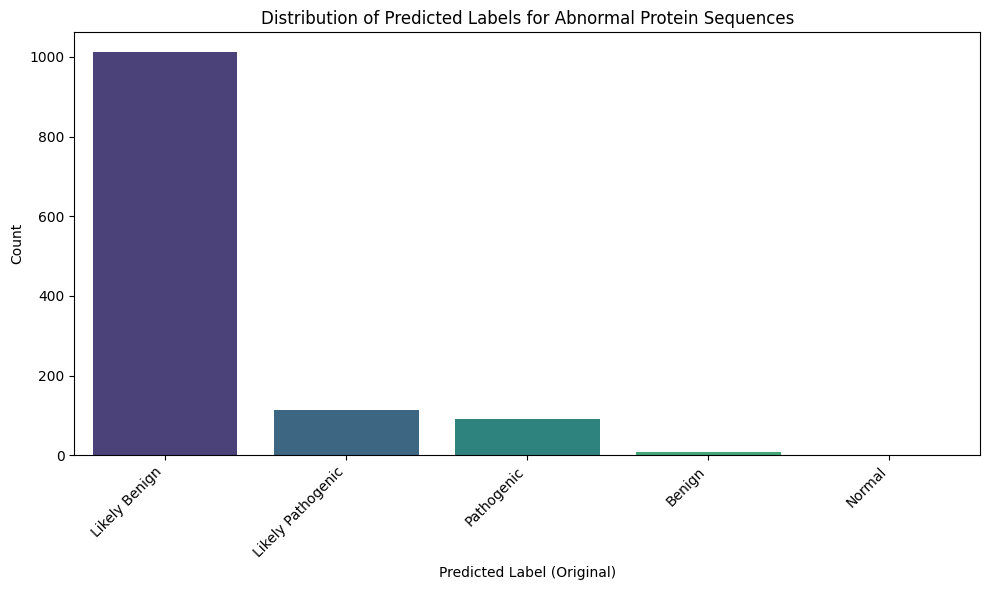

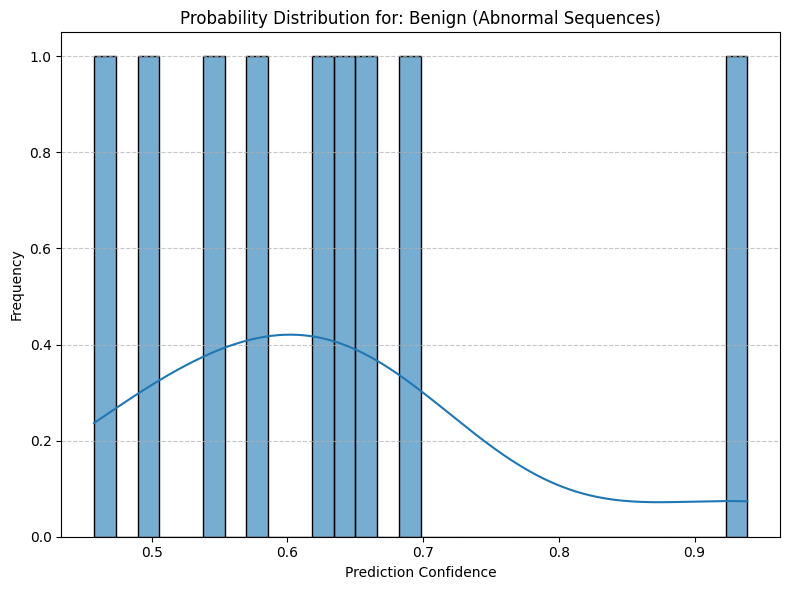

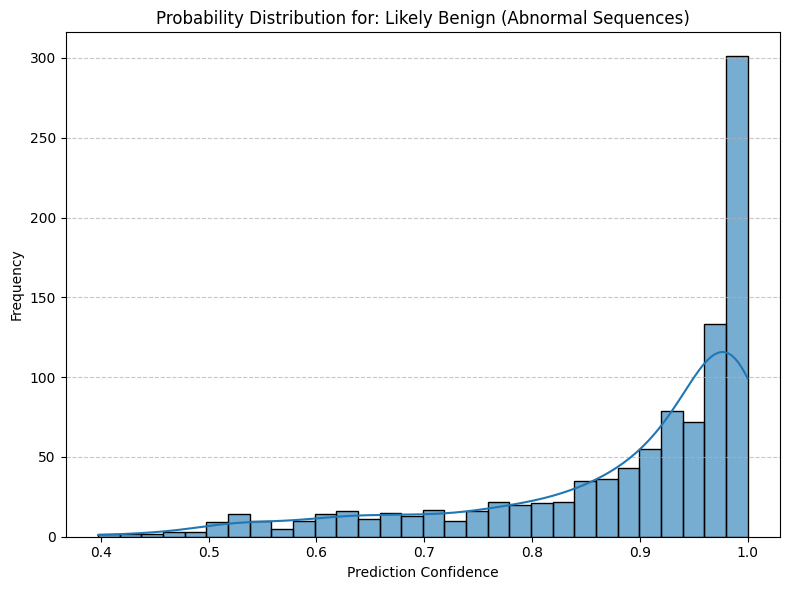

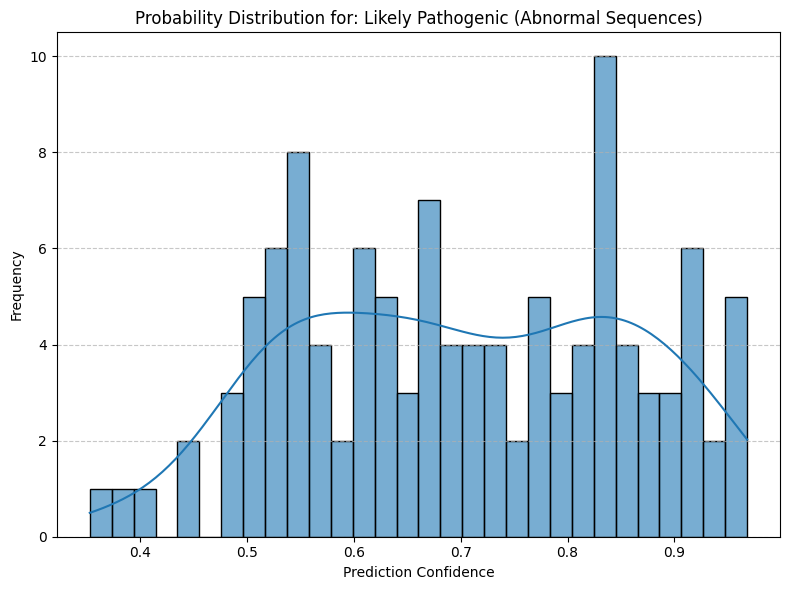

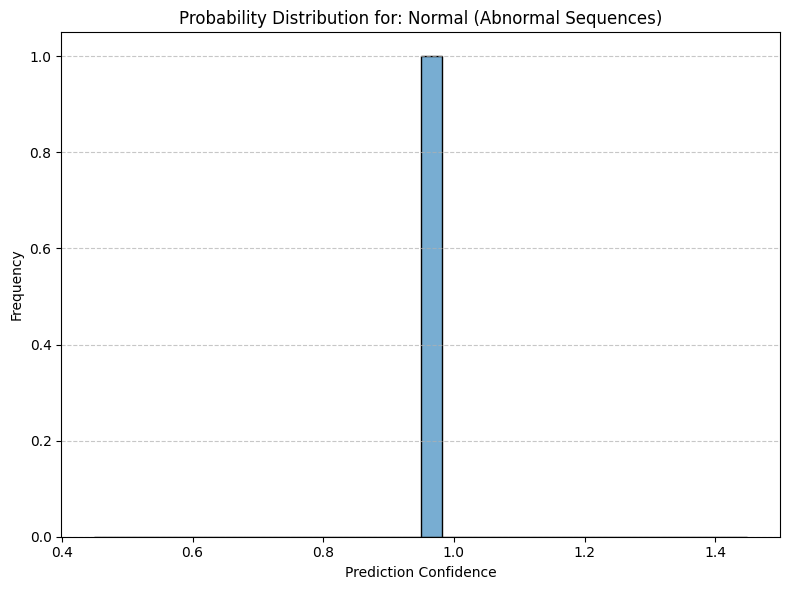

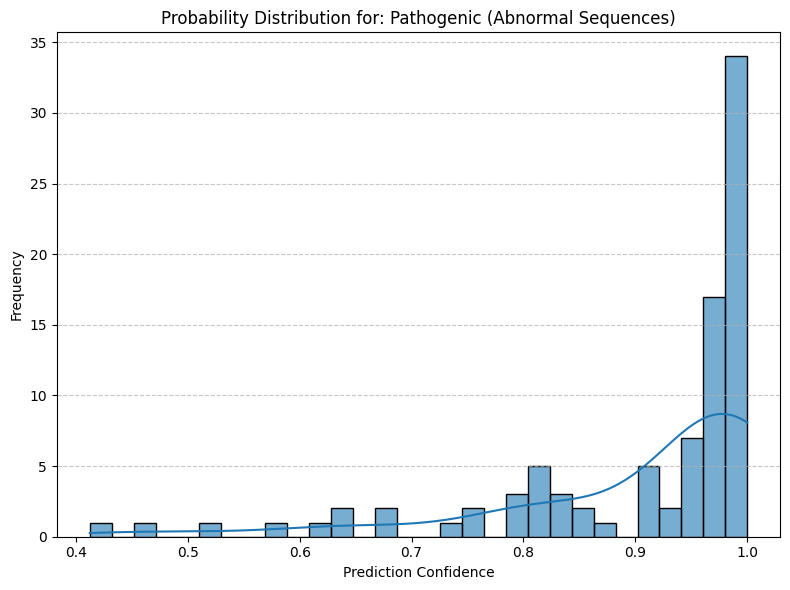

In [36]:
normal_seq = 'MDVPGPVSRRAAAAAATVLLRTARVRRECWFLPTALLCAYGFFASLRPSEPFLTPYLLGPDKNLTEREVFNEIYPVWTYSYLVLLFPVFLATDYLRYKPVVLLQGLSLIVTWFMLLYAQGLLAIQFLEFFYGIATATEIAYYSYIYSVVDLGMYQKVTSYCRSATLVGFTVGSVLGQILVSVAGWSLFSLNVISLTCVSVAFAVAWFLPMPQKSLFFHHIPSTCQRVNGIKVQNGGIVTDTPASNHLPGWEDIESKIPLNMEEPPVEEPEPKPDRLLVLKVLWNDFLMCYSSRPLLCWSVWWALSTCGYFQVVNYTQGLWEKVMPSRYAAIYNGGVEAVSTLLGAVAVFAVGYIKISWSTWGEMTLSLFSLLIAAAVYIMDTVGNIWVCYASYVVFRIIYMLLITIATFQIAANLSMERYALVFGVNTFIALALQTLLTLIVVDASGLGLEITTQFLIYASYFALIAVVFLASGAVSVMKKCRKLEDPQSSSQVTTS'
normal_seq_2 = 'MDCYRTSLSSSWIYPTVILCLFGFFSMMRPSEPFLIPYLSGPDKNLTSAEITNEIFPVWTYSYLVLLLPVFVLTDYVRYKPVIILQGISFIITWLLLLFGQGVKTMQVVEFFYGMVTAAEVAYYAYIYSVVSPEHYQRVSGYCRSVTLAAYTAGSVLAQLLVSLANMSYFYLNVISLASVSVAFLFSLFLPMPKKSMFFHAKPSREIKKSSSVNPVLEETHEGEAPGCEEQKPTSEILSTSGKLNKGQLNSLKPSNVTVDVFVQWFQDLKECYSSKRLFYWSLWWAFATAGFNQVLNYVQILWDYKAPSQDSSIYNGAVEAIATFGGAVAAFAVGYVKVNWDLLGELALVVFSVVNAGSLFLMHYTANIWACYAGYLIFKSSYMLLITIAVFQIAVNLNVERYALVFGINTFIALVIQTIMTVIVVDQRGLNLPVSIQFLVYGSYFAVIAGIFLMRSMYITYSTKSQKDVQSPAPSENPDVSHPEEESNIIMSTKL'

predictions_df['normal_seq'] = None
normal_ones = 0
abnormal_ones = 0

for i, row in predictions_df.iterrows():
    if row['protein_sequence'] == normal_seq or row['protein_sequence'] == normal_seq_2:
        predictions_df.at[i, 'normal_seq'] = True
        normal_ones += 1
    else:
        predictions_df.at[i, 'normal_seq'] = False
        abnormal_ones += 1  

print("\nAdded 'normal_seq' column to predictions_df.")
print(f"Number of normal sequences: {normal_ones}")
print(f"Number of abnormal sequences: {abnormal_ones}")

# Filter abnormal sequences
abnormal_predictions_df = predictions_df[predictions_df['normal_seq'] == False]

# Plot the distribution of predicted labels for abnormal sequences
plt.figure(figsize=(10, 6))
sns.countplot(data=abnormal_predictions_df, x='Predicted_Label_Display', order=abnormal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")
plt.title('Distribution of Predicted Labels for Abnormal Protein Sequences')
plt.xlabel('Predicted Label (Original)')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plot probability distribution for each label in abnormal_predictions_df in separate windows
unique_labels = np.unique(abnormal_predictions_df['Predicted_Label_Display'])

for label in unique_labels:
    plt.figure(figsize=(8, 6))
    label_probs = abnormal_predictions_df[abnormal_predictions_df['Predicted_Label_Display'] == label]['Prediction_Confidence']
    sns.histplot(label_probs, kde=True, bins=30, alpha=0.6)
    plt.title(f'Probability Distribution for: {label} (Abnormal Sequences)')
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_2465/3063723964.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=normal_predictions_df, x='Predicted_Label_Display', order=normal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")


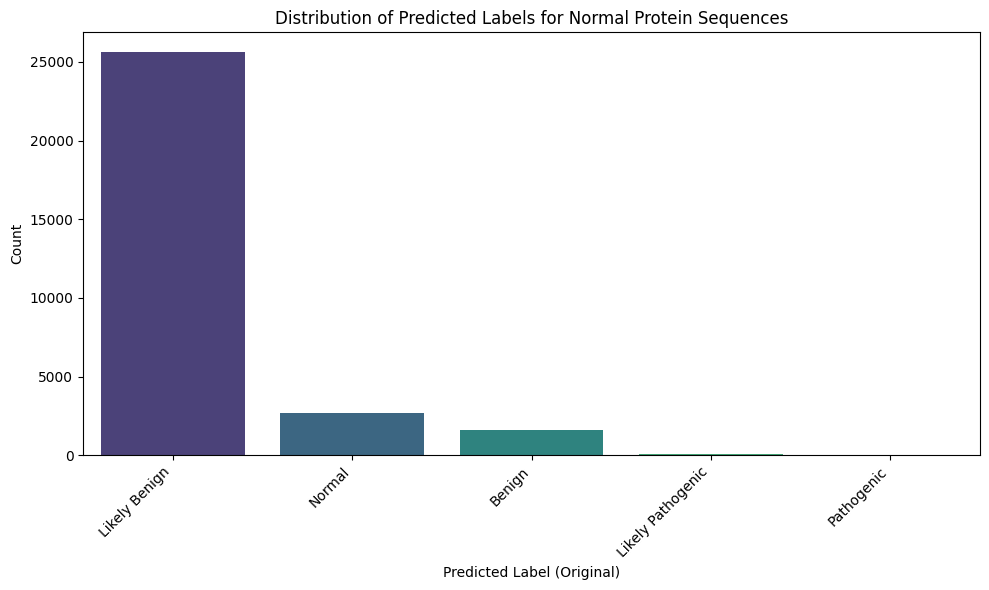

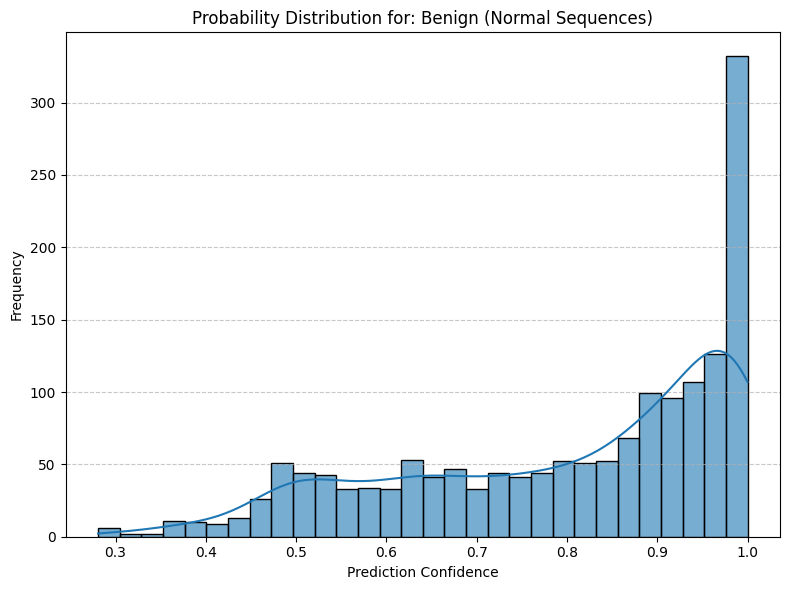

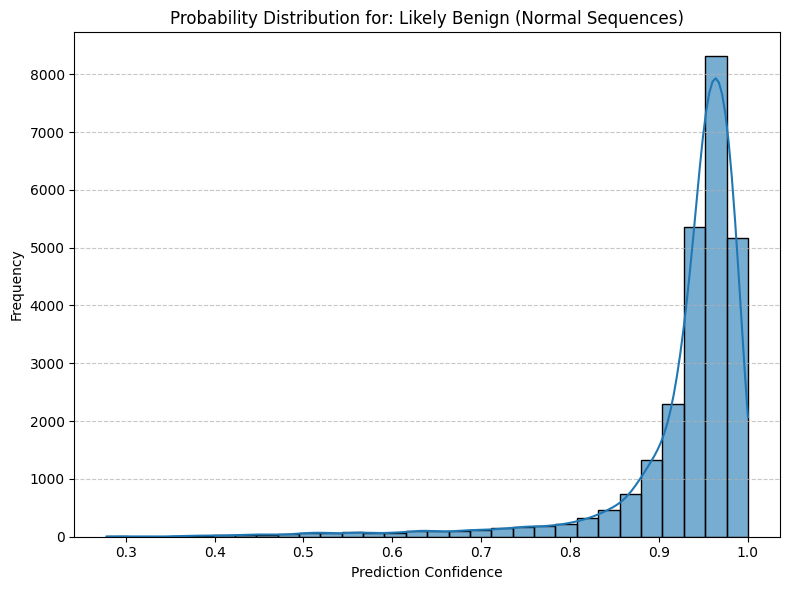

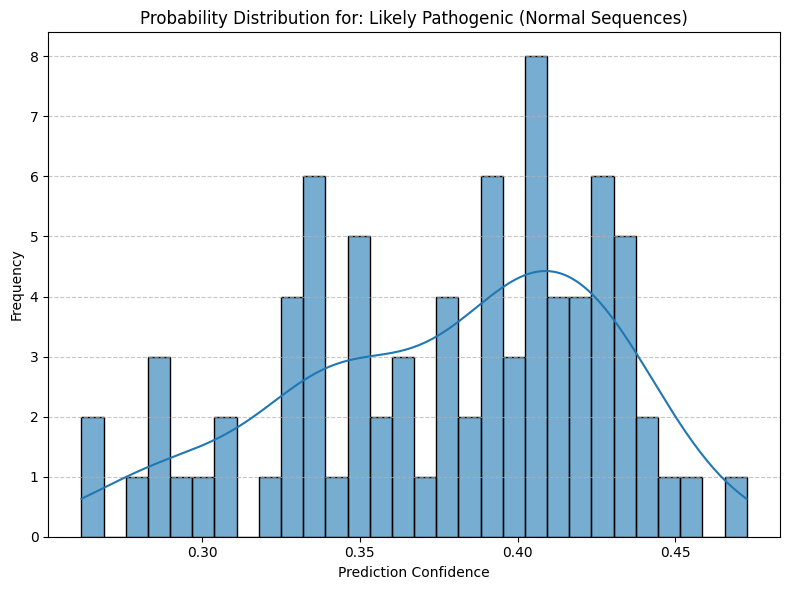

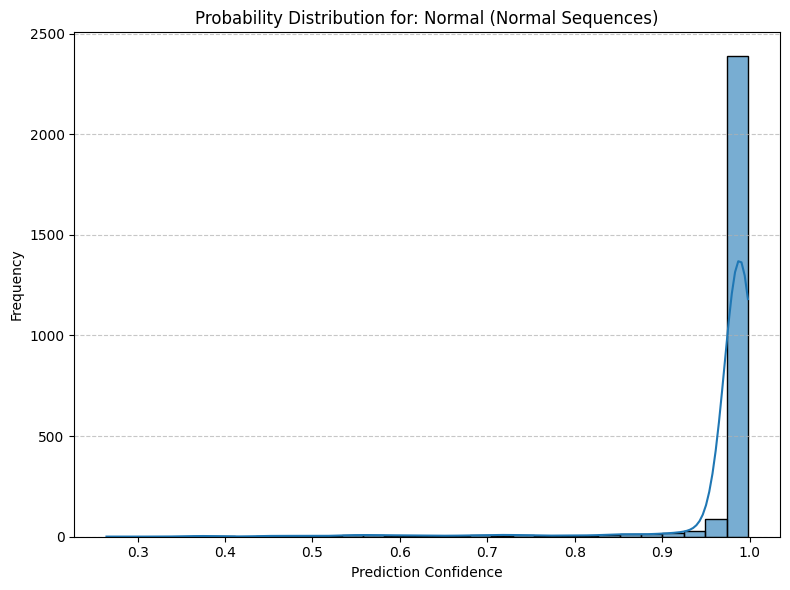

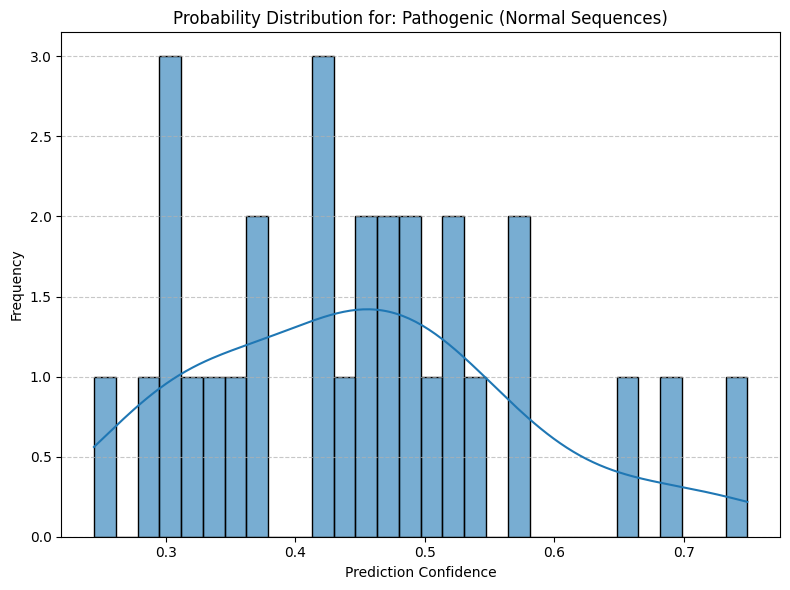

In [209]:
# Filter abnormal sequences
normal_predictions_df = predictions_df[predictions_df['normal_seq'] == True]

# Plot the distribution of predicted labels for abnormal sequences
plt.figure(figsize=(10, 6))
sns.countplot(data=normal_predictions_df, x='Predicted_Label_Display', order=normal_predictions_df['Predicted_Label_Display'].value_counts().index, palette="viridis")
plt.title('Distribution of Predicted Labels for Normal Protein Sequences')
plt.xlabel('Predicted Label (Original)')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
# Plot probability distribution for each label in abnormal_predictions_df in separate windows
unique_labels = np.unique(normal_predictions_df['Predicted_Label_Display'])

for label in unique_labels:
    plt.figure(figsize=(8, 6))
    label_probs = normal_predictions_df[normal_predictions_df['Predicted_Label_Display'] == label]['Prediction_Confidence']
    sns.histplot(label_probs, kde=True, bins=30, alpha=0.6)
    plt.title(f'Probability Distribution for: {label} (Normal Sequences)')
    plt.xlabel('Prediction Confidence')
    plt.ylabel('Frequency')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [37]:
predictions_df.to_csv('results/predictions_with_details.csv', index=False)
print("\nSaved predictions_df to 'predictions_with_details.csv'")


Saved predictions_df to 'predictions_with_details.csv'
